In [1]:
# ============================================================
# CELL 1 — Verify Python, PyTorch, CUDA and GPU
# ============================================================

import sys
import torch
import transformers
import pandas as pd

# Show which Python executable this notebook is actually using.
# This is important because we have multiple Python environments.
print("Python:", sys.executable)

# Show the installed PyTorch version.
print("PyTorch:", torch.__version__)

# Show the CUDA version that PyTorch was built with.
print("PyTorch CUDA:", torch.version.cuda)

# Check whether PyTorch can actually access the NVIDIA GPU.
print("CUDA available:", torch.cuda.is_available())

# If CUDA is available, show the GPU name.
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Show Transformers version.
print("Transformers:", transformers.__version__)

# Show Pandas version.
print("Pandas:", pd.__version__)

c:\Users\amjad\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: c:\Users\amjad\AppData\Local\Programs\Python\Python312\python.exe
PyTorch: 2.9.1+cu126
PyTorch CUDA: 12.6
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Transformers: 5.17.0
Pandas: 3.0.3


In [2]:
# ============================================================
# CELL 2 — Load DistilBERT
# ============================================================

import torch
from transformers import AutoTokenizer, AutoModel

# ------------------------------------------------------------
# Model name
# ------------------------------------------------------------
# DistilBERT is a smaller and faster version of BERT.
# We are using the standard pretrained English DistilBERT model
# as the starting point for our experiment.
MODEL_NAME = "distilbert-base-uncased"

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
# "cuda" means use the NVIDIA GPU.
# "cpu" means use the computer's processor instead.
#
# We already confirmed that CUDA is available, so this should
# select your RTX 4050 automatically.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

# ------------------------------------------------------------
# Tokenizer
# ------------------------------------------------------------
# The tokenizer converts normal text into tokens/numbers that
# DistilBERT understands.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# ------------------------------------------------------------
# DistilBERT model
# ------------------------------------------------------------
# AutoModel loads the pretrained DistilBERT neural network.
# It does NOT perform classification yet.
# We will use its hidden representations to create embeddings.
text_model = AutoModel.from_pretrained(MODEL_NAME)

# Move the model from CPU memory to the NVIDIA GPU.
text_model = text_model.to(DEVICE)

# Put the model into evaluation mode.
# This tells PyTorch that we are using the model for inference,
# not training at this stage.
text_model.eval()

print("DistilBERT loaded successfully!")
print("Model:", MODEL_NAME)

Using device: cuda


c:\Users\amjad\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amjad\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 33327.80it/s]
[transformers] Distil

DistilBERT loaded successfully!
Model: distilbert-base-uncased


In [3]:
# ============================================================
# CELL 3 — Test DistilBERT Text Embedding
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Test query
# ------------------------------------------------------------
# This is the kind of natural-language query our furniture
# recommendation system should understand.
query = "kitchen equipment"

# ------------------------------------------------------------
# Convert the query into DistilBERT tokens
# ------------------------------------------------------------
# The tokenizer converts the text into numbers that DistilBERT
# can process.
inputs = tokenizer(
    query,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

# Move the tokenized input from CPU to the RTX 4050.
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

# ------------------------------------------------------------
# Generate DistilBERT representation
# ------------------------------------------------------------
# no_grad() tells PyTorch that we are NOT training.
# This saves GPU memory and makes inference faster.
with torch.no_grad():
    outputs = text_model(**inputs)

# outputs.last_hidden_state contains a vector for every token.
# Shape is approximately:
#
# (number_of_sentences, number_of_tokens, 768)
#
# DistilBERT-base produces 768-dimensional hidden vectors.
token_embeddings = outputs.last_hidden_state

print("Token embedding shape:", token_embeddings.shape)

# ------------------------------------------------------------
# Mean pooling
# ------------------------------------------------------------
# We need ONE vector representing the entire query.
#
# Mean pooling averages the token vectors while ignoring
# padding tokens.
attention_mask = inputs["attention_mask"]

mask = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

sum_embeddings = torch.sum(token_embeddings * mask, dim=1)

sum_mask = torch.clamp(mask.sum(dim=1), min=1e-9)

query_embedding = sum_embeddings / sum_mask

# ------------------------------------------------------------
# L2 normalization
# ------------------------------------------------------------
# Normalization makes cosine similarity easier and more stable
# when comparing this query with product embeddings.
query_embedding = F.normalize(query_embedding, p=2, dim=1)

print("Final query embedding shape:", query_embedding.shape)
print("Embedding dimension:", query_embedding.shape[1])

Token embedding shape: torch.Size([1, 4, 768])
Final query embedding shape: torch.Size([1, 768])
Embedding dimension: 768


In [4]:
# ============================================================
# CELL 4 — Load Product Metadata
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# Path to our already prepared 30,000-product metadata file.
# ------------------------------------------------------------
# We reuse this file from the original project.
# There is NO need to download the Amazon dataset again.
METADATA_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\product_metadata.parquet"
)

# Check that the file actually exists before trying to load it.
if not METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Product metadata file not found:\n{METADATA_PATH}"
    )

# Read the Parquet file into a Pandas DataFrame.
products_df = pd.read_parquet(METADATA_PATH)

# Display basic information.
print("Number of products:", len(products_df))
print("Number of columns:", len(products_df.columns))

print("\nColumns:")
print(products_df.columns.tolist())

# Show a few product titles.
print("\nSample products:")
display(products_df[["parent_asin", "title"]].head())

Number of products: 30000
Number of columns: 9

Columns:
['parent_asin', 'title', 'image_url', 'price', 'average_rating', 'rating_number', 'main_category', 'description', 'categories']

Sample products:


,parent_asin,title
0,B0C4CPL2RV,"Walensee Large Bathroom Rug (24 x 60, Black) E..."
1,B09L626MHB,CHILLOUT LIFE 20 oz Stainless Steel Tumbler wi...
2,B0BPJ69P2H,H.VERSAILTEX Blackout Curtains 84 Inch Length ...
3,B00JIKM0UQ,Best Home Fashion Wide Width Thermal Insulated...
4,B081J8DH1K,Bedsure Linen Duvet Cover Queen Linen Cotton B...


In [6]:
# ============================================================
# CELL 5 — Prepare Product Text for DistilBERT
# ============================================================

import numpy as np
import pandas as pd


def clean_text(value):
    """
    Convert a product field into clean text.

    Product metadata is not always stored as a simple string.
    Some fields, especially 'categories', can contain lists or
    NumPy arrays.

    This function converts all of those formats safely into text.
    """

    # --------------------------------------------------------
    # Case 1: Missing value
    # --------------------------------------------------------
    # Check missing values ONLY when the value is a single
    # scalar value. This avoids the array-related error we got.
    if value is None:
        return ""

    # --------------------------------------------------------
    # Case 2: List or NumPy array
    # --------------------------------------------------------
    # Categories can contain multiple values.
    #
    # Example:
    # ["Home & Kitchen", "Bathroom", "Bath Rugs"]
    #
    # We join them together into one text string.
    if isinstance(value, (list, tuple, np.ndarray)):
        return " ".join(
            str(item).strip()
            for item in value
            if item is not None
        )

    # --------------------------------------------------------
    # Case 3: Pandas missing value
    # --------------------------------------------------------
    # At this point we are dealing with a single value, so
    # pd.isna() safely returns one True/False result.
    try:
        if pd.isna(value):
            return ""
    except (TypeError, ValueError):
        # If an unusual data type causes a problem, simply
        # continue and convert the value to text.
        pass

    # --------------------------------------------------------
    # Case 4: Normal text/number
    # --------------------------------------------------------
    return str(value).strip()


# ------------------------------------------------------------
# Create text representation for all 30,000 products.
# ------------------------------------------------------------

product_texts = []

for _, row in products_df.iterrows():

    # Product title.
    title = clean_text(row["title"])

    # Main category.
    main_category = clean_text(row["main_category"])

    # Detailed categories.
    categories = clean_text(row["categories"])

    # Product description.
    description = clean_text(row["description"])

    # Limit the description so that very long product
    # descriptions don't unnecessarily increase processing time.
    description = description[:1000]

    # Combine the useful product information into one text.
    product_text = (
        f"Product: {title}. "
        f"Category: {main_category}. "
        f"Subcategories: {categories}. "
        f"Description: {description}"
    )

    product_texts.append(product_text)


# Add the generated text to our DataFrame.
products_df["distilbert_text"] = product_texts


# ------------------------------------------------------------
# Verify the result.
# ------------------------------------------------------------

print("Number of product texts:", len(products_df["distilbert_text"]))

print("\nFirst product text:\n")
print(products_df["distilbert_text"].iloc[0])

Number of product texts: 30000

First product text:

Product: Walensee Large Bathroom Rug (24 x 60, Black) Extra Soft and Absorbent Shaggy Bathroom Mat Machine Washable Microfiber Bath Mat for Bathroom, Non Slip Bath Mat, Luxury Bathroom Floor Mats. Category: Amazon Home. Subcategories: Home & Kitchen Bath Bath Rugs. Description: 


In [7]:
# ============================================================
# CELL 6 — Inspect Prepared Product Text
# ============================================================

# Display the first five products and the text that will
# eventually be given to DistilBERT.
display(
    products_df[
        [
            "parent_asin",
            "title",
            "distilbert_text"
        ]
    ].head(5)
)

,parent_asin,title,distilbert_text
0,B0C4CPL2RV,"Walensee Large Bathroom Rug (24 x 60, Black) E...","Product: Walensee Large Bathroom Rug (24 x 60,..."
1,B09L626MHB,CHILLOUT LIFE 20 oz Stainless Steel Tumbler wi...,Product: CHILLOUT LIFE 20 oz Stainless Steel T...
2,B0BPJ69P2H,H.VERSAILTEX Blackout Curtains 84 Inch Length ...,Product: H.VERSAILTEX Blackout Curtains 84 Inc...
3,B00JIKM0UQ,Best Home Fashion Wide Width Thermal Insulated...,Product: Best Home Fashion Wide Width Thermal ...
4,B081J8DH1K,Bedsure Linen Duvet Cover Queen Linen Cotton B...,Product: Bedsure Linen Duvet Cover Queen Linen...


In [8]:
# ============================================================
# CELL 7 — Generate DistilBERT Embeddings for 30,000 Products
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from pathlib import Path


# ------------------------------------------------------------
# Output location
# ------------------------------------------------------------
# We save the embeddings so that we DON'T have to generate
# them again every time we restart the notebook.
OUTPUT_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL"
) / "distilbert_text_embeddings.npy"

print("Embeddings will be saved to:")
print(OUTPUT_PATH)


# ------------------------------------------------------------
# Check whether embeddings already exist
# ------------------------------------------------------------
# This is an important safety check.
#
# If we already generated the embeddings successfully, we
# should NOT waste GPU time generating them again.
if OUTPUT_PATH.exists():

    existing_embeddings = np.load(OUTPUT_PATH, mmap_mode="r")

    print("\nExisting embeddings found!")
    print("Shape:", existing_embeddings.shape)

    if existing_embeddings.shape == (30000, 768):
        print("✓ Correct embeddings already exist.")
        print("✓ Skipping expensive computation.")

    else:
        print("Existing file has an unexpected shape.")
        print("We will regenerate it.")


# ------------------------------------------------------------
# Generate embeddings only if they don't already exist
# ------------------------------------------------------------

if not OUTPUT_PATH.exists() or existing_embeddings.shape != (30000, 768):

    # Put the model into evaluation mode.
    text_model.eval()

    # Batch size controls how many products are processed
    # simultaneously on the GPU.
    #
    # 32 is a safe starting point for your RTX 4050.
    BATCH_SIZE = 32

    # Store the embeddings generated for each batch.
    all_embeddings = []

    print("\nStarting DistilBERT embedding generation...")
    print("Total products:", len(products_df))
    print("Batch size:", BATCH_SIZE)

    # --------------------------------------------------------
    # Process products batch-by-batch
    # --------------------------------------------------------
    for start in tqdm(
        range(0, len(products_df), BATCH_SIZE),
        desc="Generating embeddings"
    ):

        # Calculate the end position of this batch.
        end = min(start + BATCH_SIZE, len(products_df))

        # Get the product texts for this batch.
        batch_texts = products_df["distilbert_text"].iloc[start:end].tolist()

        # ----------------------------------------------------
        # Tokenize the batch
        # ----------------------------------------------------
        # Padding makes all texts in the batch the same length.
        # Truncation prevents extremely long descriptions from
        # exceeding DistilBERT's maximum input length.
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        )

        # Move tokenized data to the RTX 4050.
        inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
        }

        # ----------------------------------------------------
        # Run DistilBERT
        # ----------------------------------------------------
        # no_grad() disables gradient calculation because we
        # are generating embeddings, NOT training the model.
        with torch.no_grad():

            outputs = text_model(**inputs)

        # Token-level representations.
        token_embeddings = outputs.last_hidden_state

        # ----------------------------------------------------
        # Mean pooling
        # ----------------------------------------------------
        # DistilBERT produces one vector per token.
        # We need ONE vector for the complete product.
        #
        # The attention mask ensures that padding tokens are
        # ignored when calculating the average.
        attention_mask = inputs["attention_mask"]

        mask = attention_mask.unsqueeze(-1).expand(
            token_embeddings.size()
        ).float()

        sum_embeddings = torch.sum(
            token_embeddings * mask,
            dim=1
        )

        sum_mask = torch.clamp(
            mask.sum(dim=1),
            min=1e-9
        )

        batch_embeddings = sum_embeddings / sum_mask

        # ----------------------------------------------------
        # L2 normalization
        # ----------------------------------------------------
        # Normalize every product vector so cosine similarity
        # can be used later for semantic search.
        batch_embeddings = F.normalize(
            batch_embeddings,
            p=2,
            dim=1
        )

        # ----------------------------------------------------
        # Move embeddings from GPU → CPU
        # ----------------------------------------------------
        # NumPy arrays live in CPU memory, so we move the
        # generated embeddings back to the CPU.
        batch_embeddings = batch_embeddings.cpu().numpy()

        # Add this batch to our complete embedding list.
        all_embeddings.append(batch_embeddings)

    # --------------------------------------------------------
    # Combine all batches
    # --------------------------------------------------------
    distilbert_embeddings = np.vstack(all_embeddings)

    print("\nEmbedding generation completed!")
    print("Embedding shape:", distilbert_embeddings.shape)

    # --------------------------------------------------------
    # Save embeddings permanently
    # --------------------------------------------------------
    np.save(OUTPUT_PATH, distilbert_embeddings)

    print("\nSaved successfully:")
    print(OUTPUT_PATH)

    # Free some memory after saving.
    del all_embeddings

Embeddings will be saved to:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\distilbert_text_embeddings.npy

Starting DistilBERT embedding generation...
Total products: 30000
Batch size: 32


Generating embeddings: 100%|██████████| 938/938 [02:33<00:00,  6.11it/s]



Embedding generation completed!
Embedding shape: (30000, 768)

Saved successfully:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\distilbert_text_embeddings.npy


In [9]:
# ============================================================
# CELL 8 — DistilBERT Semantic Product Search
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# Load the saved DistilBERT embeddings
# ------------------------------------------------------------
# We use the saved file instead of generating the embeddings
# again. This makes future experiments much faster.
DISTILBERT_EMBEDDINGS_PATH = (
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\distilbert_text_embeddings.npy"
)

distilbert_embeddings = np.load(DISTILBERT_EMBEDDINGS_PATH)

print("DistilBERT embeddings shape:")
print(distilbert_embeddings.shape)


# ------------------------------------------------------------
# Function to create an embedding for a user query
# ------------------------------------------------------------

def create_query_embedding(query):
    """
    Convert a user's natural-language query into a
    normalized 768-dimensional DistilBERT embedding.
    """

    # Convert the query text into DistilBERT tokens.
    inputs = tokenizer(
        query,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    # Move the tokens to the RTX 4050.
    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    # We are only creating an embedding, not training.
    with torch.no_grad():

        outputs = text_model(**inputs)

    # Get the vector for every token.
    token_embeddings = outputs.last_hidden_state

    # --------------------------------------------------------
    # Mean pooling
    # --------------------------------------------------------
    # Convert token vectors into ONE vector representing
    # the complete query.
    attention_mask = inputs["attention_mask"]

    mask = attention_mask.unsqueeze(-1).expand(
        token_embeddings.size()
    ).float()

    sum_embeddings = torch.sum(
        token_embeddings * mask,
        dim=1
    )

    sum_mask = torch.clamp(
        mask.sum(dim=1),
        min=1e-9
    )

    query_embedding = sum_embeddings / sum_mask

    # Normalize the query vector.
    query_embedding = F.normalize(
        query_embedding,
        p=2,
        dim=1
    )

    # Move from GPU to CPU and convert to NumPy.
    return query_embedding.cpu().numpy()[0]


# ------------------------------------------------------------
# Test query
# ------------------------------------------------------------

query = "kitchen equipment"

query_embedding = create_query_embedding(query)

print("\nQuery:", query)
print("Query embedding shape:", query_embedding.shape)


# ------------------------------------------------------------
# Calculate cosine similarity
# ------------------------------------------------------------
# Because both product and query embeddings are normalized,
# their dot product is equivalent to cosine similarity.
similarities = distilbert_embeddings @ query_embedding


# ------------------------------------------------------------
# Get the top 10 products
# ------------------------------------------------------------

top_k = 10

# np.argsort() gives the indices sorted by similarity.
# [::-1] reverses the order so the highest similarity comes first.
top_indices = np.argsort(similarities)[::-1][:top_k]


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

results = products_df.iloc[top_indices].copy()

results["semantic_score"] = similarities[top_indices]

display(
    results[
        [
            "parent_asin",
            "title",
            "average_rating",
            "rating_number",
            "price",
            "semantic_score"
        ]
    ]
)

DistilBERT embeddings shape:
(30000, 768)

Query: kitchen equipment
Query embedding shape: (768,)


,parent_asin,title,average_rating,rating_number,price,semantic_score
26115,B01MCZNZGA,PRODUCT NOT AVAILABLE,2.9,347,None,0.592205
10143,B0794MBDK8,Sorbus Bathroom Storage Shelf Over Toilet Spac...,4.1,1772,45.99,0.584847
25295,B00518BQD6,"U.S. Shell, Inc. Starfish Mix",4.4,383,11.65,0.584081
23394,B0BG2V2ZZB,Trangia Spirit burner for storm cookers,4.8,4302,17.99,0.581027
28381,B06XKG565Z,hOmeLabs 1.3 Cu. Ft. Microwave,4.0,673,None,0.580460
15003,B01LXKKUY8,Simple Houseware Spice Jars Bottles w/label (S...,4.6,1704,12.97,0.580231
17629,B011A3ZX4S,FreezerBoy (TM) Dry-Erase Whiteboard Refrigera...,4.7,1235,None,0.579243
23664,B00M50F8JQ,Blade Butler Professional Knife Sharpener,3.9,454,None,0.579215
21501,B07PCK8897,NOKESS Universal Pot Lid Replacement Knobs Pan...,4.8,8093,5.48,0.578566
28618,B0BXH7VZ25,"Home Basics TB10351 Toilet, Brushed Silver",4.2,482,11.69,0.578231


In [10]:
# ============================================================
# CELL 9 — BLIP Compatibility Test
# ============================================================

# BLIP = Bootstrapping Language-Image Pre-training.
#
# BLIP is a vision-language model. It can look at an image
# and generate a natural-language description (caption).
#
# We are ONLY checking whether BLIP can be loaded correctly.
# We are NOT processing our 30,000 products yet.

import torch

from transformers import (
    BlipProcessor,
    BlipForConditionalGeneration
)


# ------------------------------------------------------------
# BLIP model
# ------------------------------------------------------------
# This is a pretrained BLIP model designed for image captioning.
#
# The first run may download the model from Hugging Face.
BLIP_MODEL_NAME = "Salesforce/blip-image-captioning-base"


# ------------------------------------------------------------
# Select GPU
# ------------------------------------------------------------
# We already confirmed that your RTX 4050 is available.
BLIP_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("BLIP device:", BLIP_DEVICE)


# ------------------------------------------------------------
# Load BLIP processor
# ------------------------------------------------------------
# The processor prepares an image so BLIP can understand it.
blip_processor = BlipProcessor.from_pretrained(
    BLIP_MODEL_NAME
)


# ------------------------------------------------------------
# Load BLIP model
# ------------------------------------------------------------
# This loads the pretrained vision-language model.
blip_model = BlipForConditionalGeneration.from_pretrained(
    BLIP_MODEL_NAME
)


# Move BLIP to the GPU.
blip_model = blip_model.to(BLIP_DEVICE)


# Put BLIP into evaluation mode.
# We are testing image captioning, not training yet.
blip_model.eval()


print("\nBLIP loaded successfully!")
print("Model:", BLIP_MODEL_NAME)

BLIP device: cuda


c:\Users\amjad\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amjad\.cache\huggingface\hub\models--Salesforce--blip-image-captioning-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 473/473 [00:00<00:00, 36403.95it/s]



BLIP loaded successfully!
Model: Salesforce/blip-image-captioning-base


Product:
Walensee Large Bathroom Rug (24 x 60, Black) Extra Soft and Absorbent Shaggy Bathroom Mat Machine Washable Microfiber Bath Mat for Bathroom, Non Slip Bath Mat, Luxury Bathroom Floor Mats

Image URL:
https://m.media-amazon.com/images/I/61PYg8i0C5L._AC_SL1000_.jpg


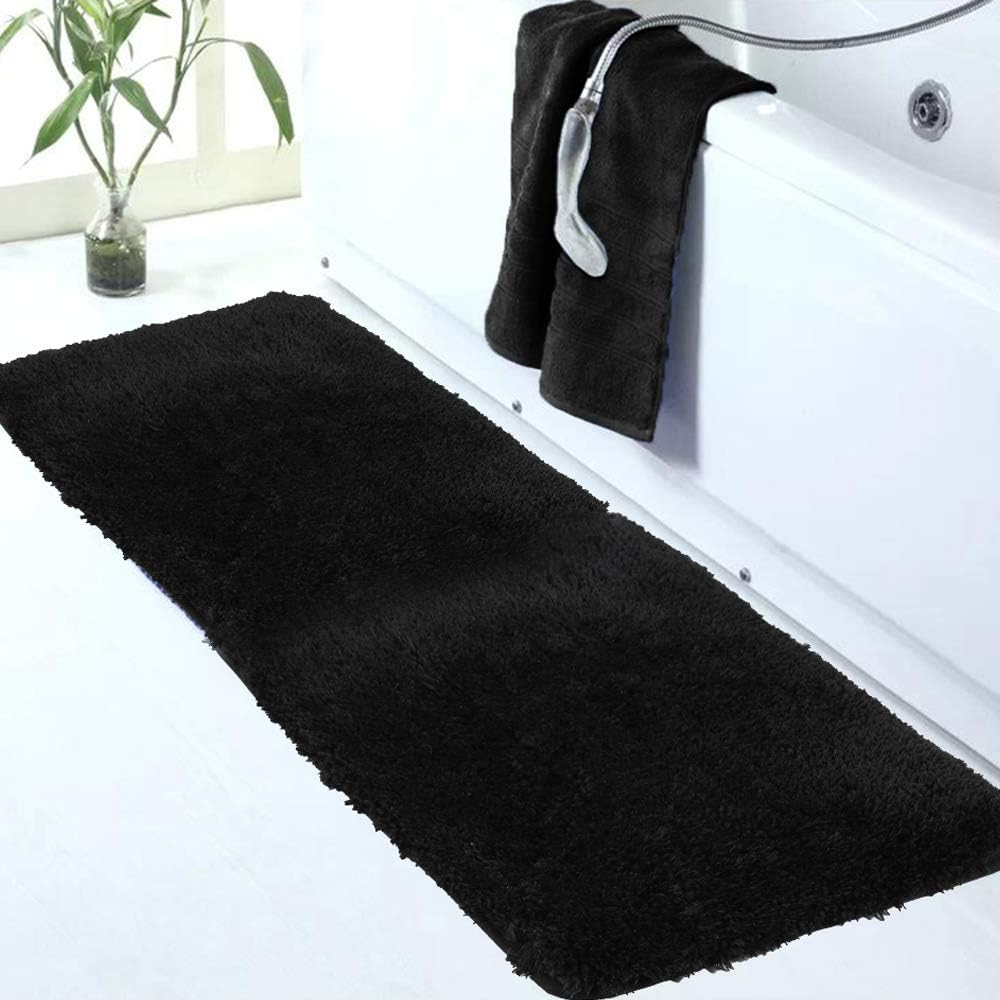


BLIP caption:
a black bath mat on a white bathtub


In [11]:
# ============================================================
# CELL 10 — Test BLIP on One Product Image
# ============================================================

from PIL import Image
import requests
from io import BytesIO


# ------------------------------------------------------------
# Select one product that has an image URL
# ------------------------------------------------------------
# We search our 30,000-product catalog for the first product
# that has a usable image URL.
test_product = None

for _, row in products_df.iterrows():

    image_url = row["image_url"]

    # Check that the image URL is actually available.
    if isinstance(image_url, str) and image_url.startswith("http"):

        test_product = row
        break


# Make sure we found an image.
if test_product is None:
    raise ValueError("No usable product image URL was found.")


# ------------------------------------------------------------
# Display the selected product
# ------------------------------------------------------------

print("Product:")
print(test_product["title"])

print("\nImage URL:")
print(test_product["image_url"])


# ------------------------------------------------------------
# Download the image
# ------------------------------------------------------------
# Requests sends a web request to retrieve the image.
response = requests.get(
    test_product["image_url"],
    timeout=20
)

# Raise an error if the image could not be downloaded.
response.raise_for_status()


# ------------------------------------------------------------
# Open the image
# ------------------------------------------------------------
# BytesIO allows PIL to read the downloaded image directly
# from memory without saving it as a local file.
image = Image.open(
    BytesIO(response.content)
).convert("RGB")


# Display the image inside Jupyter.
display(image)


# ------------------------------------------------------------
# Prepare image for BLIP
# ------------------------------------------------------------
# BLIP's processor converts the image into tensors that the
# model understands.
inputs = blip_processor(
    images=image,
    return_tensors="pt"
)

# Move the image tensor to the RTX 4050.
inputs = {
    key: value.to(BLIP_DEVICE)
    for key, value in inputs.items()
}


# ------------------------------------------------------------
# Generate caption
# ------------------------------------------------------------
# no_grad() saves GPU memory because we are only performing
# inference and are not training BLIP.
with torch.no_grad():

    output = blip_model.generate(
        **inputs,
        max_new_tokens=50
    )


# ------------------------------------------------------------
# Convert BLIP output back into normal text
# ------------------------------------------------------------
caption = blip_processor.decode(
    output[0],
    skip_special_tokens=True
)


print("\nBLIP caption:")
print(caption)

In [12]:
# ============================================================
# CELL 11 — Test BLIP on 10 Product Images
# ============================================================

from PIL import Image
import requests
from io import BytesIO
import pandas as pd
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Select up to 10 products that have image URLs
# ------------------------------------------------------------

test_products = products_df[
    products_df["image_url"].apply(
        lambda x: isinstance(x, str) and x.startswith("http")
    )
].head(10).copy()

print("Products selected:", len(test_products))


# ------------------------------------------------------------
# Generate BLIP captions
# ------------------------------------------------------------

test_captions = []

for _, row in tqdm(
    test_products.iterrows(),
    total=len(test_products),
    desc="Generating BLIP captions"
):

    try:
        # Get the product's image URL.
        image_url = row["image_url"]

        # Download the image.
        response = requests.get(
            image_url,
            timeout=20
        )

        # Stop this product if the download failed.
        response.raise_for_status()

        # Open the downloaded image.
        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        # ----------------------------------------------------
        # Prepare image for BLIP
        # ----------------------------------------------------

        inputs = blip_processor(
            images=image,
            return_tensors="pt"
        )

        # Move image data to the RTX 4050.
        inputs = {
            key: value.to(BLIP_DEVICE)
            for key, value in inputs.items()
        }

        # ----------------------------------------------------
        # Generate caption
        # ----------------------------------------------------

        with torch.no_grad():

            output = blip_model.generate(
                **inputs,
                max_new_tokens=50
            )

        # Convert model output into normal text.
        caption = blip_processor.decode(
            output[0],
            skip_special_tokens=True
        )

        test_captions.append(caption)

    except Exception as e:

        # If one image fails, don't stop the entire experiment.
        test_captions.append(
            f"[CAPTION_FAILED: {type(e).__name__}]"
        )


# ------------------------------------------------------------
# Add captions to our test DataFrame
# ------------------------------------------------------------

test_products["blip_caption"] = test_captions


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

display(
    test_products[
        [
            "parent_asin",
            "title",
            "blip_caption"
        ]
    ]
)

Products selected: 10


Generating BLIP captions: 100%|██████████| 10/10 [00:32<00:00,  3.29s/it]


,parent_asin,title,blip_caption
0,B0C4CPL2RV,"Walensee Large Bathroom Rug (24 x 60, Black) E...",a black bath mat on a white bathtub
1,B09L626MHB,CHILLOUT LIFE 20 oz Stainless Steel Tumbler wi...,chill it stainless tumbler with straw lid
2,B0BPJ69P2H,H.VERSAILTEX Blackout Curtains 84 Inch Length ...,the curtain is hanging on a window
3,B00JIKM0UQ,Best Home Fashion Wide Width Thermal Insulated...,a purple curtain with black hardware on the top
4,B081J8DH1K,Bedsure Linen Duvet Cover Queen Linen Cotton B...,"buy john lewis linen duvett, grey online at jo..."
5,B0BPGB6SZJ,KitchenAid Asteroid Oval Pot Holder 2-Pack Set...,two pink oven mits with grey trim
6,B0BN4QLZC1,Gee Di Moda Rectangle Tablecloth - 60 x 84 Inc...,a light blue tablecloth on a wooden table
7,B0711LB2PP,AllSpice 312 Preprinted Water Resistant Square...,a jar of spices and a jar of spices with the w...
8,B08G1T7XZ6,"Twinkle Star C6 Christmas String Lights, 100 L...",blue led christmas lights
9,B07L778NKZ,"Sunbeam Heated Blanket | Velvet Plush, 10 Heat...",the best weighted blankets for your bed


In [13]:
# ============================================================
# CELL 12 — Test BLIP with a Product Prompt
# ============================================================

# We will test BLIP again using a short prompt.
#
# The prompt tells BLIP that the image is a product photo.
# This may help it focus on identifying the actual product
# instead of inventing a broader scene or context.

prompt = "a product photo of"


# ------------------------------------------------------------
# Test the same 10 products again
# ------------------------------------------------------------

prompted_captions = []


for _, row in tqdm(
    test_products.iterrows(),
    total=len(test_products),
    desc="Generating prompted captions"
):

    try:

        # Get image URL.
        image_url = row["image_url"]

        # Download image.
        response = requests.get(
            image_url,
            timeout=20
        )

        response.raise_for_status()

        # Open image.
        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")


        # ----------------------------------------------------
        # Give BLIP both the image and our text prompt.
        # ----------------------------------------------------

        inputs = blip_processor(
            images=image,
            text=prompt,
            return_tensors="pt"
        )

        # Move inputs to GPU.
        inputs = {
            key: value.to(BLIP_DEVICE)
            for key, value in inputs.items()
        }


        # ----------------------------------------------------
        # Generate caption.
        # ----------------------------------------------------

        with torch.no_grad():

            output = blip_model.generate(
                **inputs,
                max_new_tokens=50
            )


        # Convert generated tokens back to text.
        caption = blip_processor.decode(
            output[0],
            skip_special_tokens=True
        )

        prompted_captions.append(caption)


    except Exception as e:

        prompted_captions.append(
            f"[CAPTION_FAILED: {type(e).__name__}]"
        )


# ------------------------------------------------------------
# Store prompted captions.
# ------------------------------------------------------------

test_products["prompted_caption"] = prompted_captions


# ------------------------------------------------------------
# Compare original vs prompted captions.
# ------------------------------------------------------------

display(
    test_products[
        [
            "title",
            "blip_caption",
            "prompted_caption"
        ]
    ]
)

Generating prompted captions: 100%|██████████| 10/10 [00:15<00:00,  1.58s/it]


,title,blip_caption,prompted_caption
0,"Walensee Large Bathroom Rug (24 x 60, Black) E...",a black bath mat on a white bathtub,a product photo of a black bath mat
1,CHILLOUT LIFE 20 oz Stainless Steel Tumbler wi...,chill it stainless tumbler with straw lid,a product photo of chillit stainless tumbles
2,H.VERSAILTEX Blackout Curtains 84 Inch Length ...,the curtain is hanging on a window,a product photo of a curtain with a floral pat...
3,Best Home Fashion Wide Width Thermal Insulated...,a purple curtain with black hardware on the top,a product photo of a purple curtain
4,Bedsure Linen Duvet Cover Queen Linen Cotton B...,"buy john lewis linen duvett, grey online at jo...",a product photo of a bed with a grey linen duvet
5,KitchenAid Asteroid Oval Pot Holder 2-Pack Set...,two pink oven mits with grey trim,a product photo of two oven mits in pink and grey
6,Gee Di Moda Rectangle Tablecloth - 60 x 84 Inc...,a light blue tablecloth on a wooden table,a product photo of a light blue tablecloth
7,AllSpice 312 Preprinted Water Resistant Square...,a jar of spices and a jar of spices with the w...,a product photo of a jar of spices and a jar o...
8,"Twinkle Star C6 Christmas String Lights, 100 L...",blue led christmas lights,a product photo of a blue led christmas wreath
9,"Sunbeam Heated Blanket | Velvet Plush, 10 Heat...",the best weighted blankets for your bed,a product photo of a pile of charcoal gray fle...


In [14]:
# ============================================================
# CELL 13 — Resumable BLIP Captioning Pipeline
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import requests
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Output file
# ------------------------------------------------------------
# Every generated caption will be saved here.
#
# Because the file is saved during processing, we can resume
# the experiment later if the notebook stops.
CAPTION_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\blip_product_captions.parquet"
)

print("Caption file:")
print(CAPTION_PATH)


# ------------------------------------------------------------
# Prepare the product list
# ------------------------------------------------------------
# We only attempt products that have a valid HTTP image URL.
products_with_images = products_df[
    products_df["image_url"].apply(
        lambda x: isinstance(x, str) and x.startswith("http")
    )
].copy()

# Reset the DataFrame index.
products_with_images = products_with_images.reset_index()

# The original DataFrame index is useful because it tells us
# which row corresponds to each product embedding.
products_with_images = products_with_images.rename(
    columns={"index": "product_index"}
)

print("\nProducts with image URLs:", len(products_with_images))


# ------------------------------------------------------------
# Create a caption results DataFrame
# ------------------------------------------------------------

if CAPTION_PATH.exists():

    # If we already have captions from an earlier run,
    # load them instead of starting from zero.
    captions_df = pd.read_parquet(CAPTION_PATH)

    print("\nExisting caption file found.")
    print("Existing records:", len(captions_df))

else:

    # Create an empty results table for the first run.
    captions_df = pd.DataFrame(
        columns=[
            "product_index",
            "parent_asin",
            "image_url",
            "blip_caption",
            "caption_status"
        ]
    )

    print("\nNo existing caption file found.")
    print("Starting a new caption dataset.")


# ------------------------------------------------------------
# Find products that still need captions
# ------------------------------------------------------------

# Product indices that have already been processed.
completed_indices = set(
    captions_df["product_index"].dropna().astype(int)
)

# Keep only products that haven't been processed yet.
remaining_products = products_with_images[
    ~products_with_images["product_index"].isin(
        completed_indices
    )
].copy()

print("\nAlready processed:", len(completed_indices))
print("Remaining:", len(remaining_products))

Caption file:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\blip_product_captions.parquet

Products with image URLs: 28204

No existing caption file found.
Starting a new caption dataset.

Already processed: 0
Remaining: 28204


In [15]:
# ============================================================
# CELL 14 — Generate a Small 100-Image BLIP Checkpoint
# ============================================================

# ------------------------------------------------------------
# Number of new images for this test
# ------------------------------------------------------------
# We intentionally start with only 100.
#
# This lets us measure:
# - processing speed
# - failure rate
# - caption quality
# - GPU memory behavior
#
# BEFORE committing to the full dataset.
TEST_LIMIT = 100


# Select the first 100 unprocessed products.
batch_products = remaining_products.head(TEST_LIMIT).copy()

print("Images to process:", len(batch_products))


# ------------------------------------------------------------
# Generate captions
# ------------------------------------------------------------

new_results = []


for _, row in tqdm(
    batch_products.iterrows(),
    total=len(batch_products),
    desc="BLIP captioning"
):

    product_index = int(row["product_index"])
    parent_asin = row["parent_asin"]
    image_url = row["image_url"]

    try:

        # ----------------------------------------------------
        # Download product image
        # ----------------------------------------------------

        response = requests.get(
            image_url,
            timeout=20
        )

        response.raise_for_status()

        # Open image and convert it to RGB.
        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")


        # ----------------------------------------------------
        # Prepare image for BLIP
        # ----------------------------------------------------

        # We use the prompted version that performed better
        # during our 10-image experiment.
        inputs = blip_processor(
            images=image,
            text="a product photo of",
            return_tensors="pt"
        )

        # Move inputs to the RTX 4050.
        inputs = {
            key: value.to(BLIP_DEVICE)
            for key, value in inputs.items()
        }


        # ----------------------------------------------------
        # Generate caption
        # ----------------------------------------------------

        with torch.no_grad():

            output = blip_model.generate(
                **inputs,
                max_new_tokens=50
            )


        # Convert BLIP's generated tokens into normal text.
        caption = blip_processor.decode(
            output[0],
            skip_special_tokens=True
        )


        # Store successful result.
        new_results.append(
            {
                "product_index": product_index,
                "parent_asin": parent_asin,
                "image_url": image_url,
                "blip_caption": caption,
                "caption_status": "success"
            }
        )


    except Exception as e:

        # ----------------------------------------------------
        # Don't stop the entire experiment because one image
        # fails.
        # ----------------------------------------------------

        new_results.append(
            {
                "product_index": product_index,
                "parent_asin": parent_asin,
                "image_url": image_url,
                "blip_caption": "",
                "caption_status": (
                    f"failed: {type(e).__name__}"
                )
            }
        )


# ------------------------------------------------------------
# Convert new results into a DataFrame
# ------------------------------------------------------------

new_results_df = pd.DataFrame(new_results)


# ------------------------------------------------------------
# Add new results to existing results
# ------------------------------------------------------------

captions_df = pd.concat(
    [
        captions_df,
        new_results_df
    ],
    ignore_index=True
)


# Remove accidental duplicate product indices.
captions_df = captions_df.drop_duplicates(
    subset=["product_index"],
    keep="last"
)


# ------------------------------------------------------------
# Save checkpoint
# ------------------------------------------------------------

captions_df.to_parquet(
    CAPTION_PATH,
    index=False
)


# ------------------------------------------------------------
# Show statistics
# ------------------------------------------------------------

success_count = (
    captions_df["caption_status"]
    .astype(str)
    .str.startswith("success")
    .sum()
)

failure_count = len(captions_df) - success_count


print("\n============================================")
print("BLIP CHECKPOINT COMPLETE")
print("============================================")

print("Total saved:", len(captions_df))
print("Successful:", success_count)
print("Failed:", failure_count)

print("\nSaved to:")
print(CAPTION_PATH)

Images to process: 100


BLIP captioning: 100%|██████████| 100/100 [03:57<00:00,  2.37s/it]


BLIP CHECKPOINT COMPLETE
Total saved: 100
Successful: 100
Failed: 0

Saved to:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\blip_product_captions.parquet


In [16]:
# ============================================================
# CELL 15 — Generate BLIP Captions for ALL Remaining Images
# ============================================================

# ------------------------------------------------------------
# IMPORTANT
# ------------------------------------------------------------
# The checkpoint file already contains the 100 images we
# processed successfully.
#
# This cell automatically skips those 100 and processes only
# the remaining images.
#
# If the notebook stops later, simply run Cell 13 again and
# then this cell. Already completed products will be skipped.
# ------------------------------------------------------------


# Reload the latest checkpoint.
# This makes sure we use everything that was saved to disk.
captions_df = pd.read_parquet(CAPTION_PATH)


# Find product indices that are already processed.
completed_indices = set(
    captions_df["product_index"].astype(int)
)


# Select only products that haven't been processed yet.
remaining_products = products_with_images[
    ~products_with_images["product_index"].isin(
        completed_indices
    )
].copy()


print("============================================")
print("BLIP FULL CAPTIONING")
print("============================================")
print("Already completed:", len(completed_indices))
print("Remaining:", len(remaining_products))
print()


# ------------------------------------------------------------
# Process remaining products
# ------------------------------------------------------------

new_results = []


for _, row in tqdm(
    remaining_products.iterrows(),
    total=len(remaining_products),
    desc="Generating BLIP captions"
):

    product_index = int(row["product_index"])
    parent_asin = row["parent_asin"]
    image_url = row["image_url"]

    try:

        # Download the product image.
        response = requests.get(
            image_url,
            timeout=20
        )

        response.raise_for_status()

        # Convert downloaded bytes into an RGB image.
        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")


        # Prepare the image for BLIP.
        inputs = blip_processor(
            images=image,
            text="a product photo of",
            return_tensors="pt"
        )


        # Move the inputs to the RTX 4050 GPU.
        inputs = {
            key: value.to(BLIP_DEVICE)
            for key, value in inputs.items()
        }


        # Generate the product caption.
        with torch.no_grad():

            output = blip_model.generate(
                **inputs,
                max_new_tokens=50
            )


        # Convert generated tokens into text.
        caption = blip_processor.decode(
            output[0],
            skip_special_tokens=True
        )


        # Store successful caption.
        new_results.append(
            {
                "product_index": product_index,
                "parent_asin": parent_asin,
                "image_url": image_url,
                "blip_caption": caption,
                "caption_status": "success"
            }
        )


    except Exception as e:

        # Store failed images instead of stopping the entire run.
        new_results.append(
            {
                "product_index": product_index,
                "parent_asin": parent_asin,
                "image_url": image_url,
                "blip_caption": "",
                "caption_status": f"failed: {type(e).__name__}"
            }
        )


    # --------------------------------------------------------
    # Checkpoint every 100 images
    # --------------------------------------------------------
    #
    # This is important.
    #
    # If the computer crashes after several hours, we don't
    # lose all the work.
    #
    # Only the current checkpoint interval could be lost.
    # --------------------------------------------------------

    if len(new_results) % 100 == 0:

        checkpoint_df = pd.DataFrame(new_results)

        captions_df = pd.concat(
            [
                captions_df,
                checkpoint_df
            ],
            ignore_index=True
        )

        captions_df = captions_df.drop_duplicates(
            subset=["product_index"],
            keep="last"
        )

        captions_df.to_parquet(
            CAPTION_PATH,
            index=False
        )

        # Clear temporary results after saving.
        new_results = []

        print(
            f"\nCheckpoint saved: "
            f"{len(captions_df)} captions"
        )


# ------------------------------------------------------------
# Save any remaining results
# ------------------------------------------------------------

if len(new_results) > 0:

    checkpoint_df = pd.DataFrame(new_results)

    captions_df = pd.concat(
        [
            captions_df,
            checkpoint_df
        ],
        ignore_index=True
    )

    captions_df = captions_df.drop_duplicates(
        subset=["product_index"],
        keep="last"
    )

    captions_df.to_parquet(
        CAPTION_PATH,
        index=False
    )


# ------------------------------------------------------------
# Final statistics
# ------------------------------------------------------------

success_count = (
    captions_df["caption_status"]
    .astype(str)
    .str.startswith("success")
    .sum()
)

failure_count = (
    len(captions_df) - success_count
)


print("\n============================================")
print("BLIP PROCESSING FINISHED")
print("============================================")

print("Total captions:", len(captions_df))
print("Successful:", success_count)
print("Failed:", failure_count)

print("\nSaved to:")
print(CAPTION_PATH)

BLIP FULL CAPTIONING
Already completed: 100
Remaining: 28104



Generating BLIP captions:   0%|          | 100/28104 [03:57<18:40:07,  2.40s/it]


Checkpoint saved: 200 captions


Generating BLIP captions:   1%|          | 200/28104 [06:15<6:51:29,  1.13it/s] 


Checkpoint saved: 300 captions


Generating BLIP captions:   1%|          | 300/28104 [07:57<7:10:51,  1.08it/s] 

... (555 outputs left out)

Generating BLIP captions: 100%|█████████▉| 28100/28104 [7:41:35<00:00, 382.68it/s]


Checkpoint saved: 28200 captions


Generating BLIP captions: 100%|██████████| 28104/28104 [7:41:35<00:00,  1.01it/s] 



BLIP PROCESSING FINISHED
Total captions: 28204
Successful: 26937
Failed: 1267

Saved to:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\blip_product_captions.parquet


In [1]:
# ============================================================
# CELL 16 — Load and Inspect BLIP Captions
# ============================================================

from pathlib import Path
import pandas as pd

BLIP_CAPTION_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\blip_product_captions.parquet"
)

# Load the captions generated by BLIP.
blip_captions_df = pd.read_parquet(BLIP_CAPTION_PATH)

print("BLIP caption dataset shape:")
print(blip_captions_df.shape)

print("\nColumns:")
print(blip_captions_df.columns.tolist())

print("\nCaption status:")
print(
    blip_captions_df["caption_status"]
    .value_counts()
)

print("\nFirst 10 captions:")
display(
    blip_captions_df[
        [
            "parent_asin",
            "blip_caption",
            "caption_status"
        ]
    ].head(10)
)

BLIP caption dataset shape:
(28204, 5)

Columns:
['product_index', 'parent_asin', 'image_url', 'blip_caption', 'caption_status']

Caption status:
caption_status
success                    26937
failed: ConnectionError     1250
failed: ConnectTimeout         9
failed: ReadTimeout            5
failed: SSLError               2
failed: HTTPError              1
Name: count, dtype: int64

First 10 captions:


,parent_asin,blip_caption,caption_status
0,B0C4CPL2RV,a product photo of a black bath mat,success
1,B09L626MHB,a product photo of chillit stainless tumbles,success
2,B0BPJ69P2H,a product photo of a curtain with a floral pat...,success
3,B00JIKM0UQ,a product photo of a purple curtain,success
4,B081J8DH1K,a product photo of a bed with a grey linen duvet,success
5,B0BPGB6SZJ,a product photo of two oven mits in pink and grey,success
6,B0BN4QLZC1,a product photo of a light blue tablecloth,success
7,B0711LB2PP,a product photo of a jar of spices and a jar o...,success
8,B08G1T7XZ6,a product photo of a blue led christmas wreath,success
9,B07L778NKZ,a product photo of a pile of charcoal gray fle...,success


In [2]:
# ============================================================
# CELL 17 — Prepare BLIP Captions for DistilBERT
# ============================================================

import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# Keep only successfully generated captions
# ------------------------------------------------------------

successful_blip_df = blip_captions_df[
    blip_captions_df["caption_status"] == "success"
].copy()

successful_blip_df = successful_blip_df.reset_index(drop=True)


print("Successful BLIP captions:", len(successful_blip_df))

print("\nExample captions:")
display(
    successful_blip_df[
        [
            "product_index",
            "parent_asin",
            "blip_caption"
        ]
    ].head(10)
)


# ------------------------------------------------------------
# Output paths
# ------------------------------------------------------------

BLIP_EMBEDDING_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\blip_caption_embeddings.npy"
)

BLIP_INDEX_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\blip_caption_embedding_indices.npy"
)


print("\nEmbedding output:")
print(BLIP_EMBEDDING_PATH)

print("\nIndex output:")
print(BLIP_INDEX_PATH)

Successful BLIP captions: 26937

Example captions:


,product_index,parent_asin,blip_caption
0,0,B0C4CPL2RV,a product photo of a black bath mat
1,1,B09L626MHB,a product photo of chillit stainless tumbles
2,2,B0BPJ69P2H,a product photo of a curtain with a floral pat...
3,3,B00JIKM0UQ,a product photo of a purple curtain
4,4,B081J8DH1K,a product photo of a bed with a grey linen duvet
5,5,B0BPGB6SZJ,a product photo of two oven mits in pink and grey
6,6,B0BN4QLZC1,a product photo of a light blue tablecloth
7,7,B0711LB2PP,a product photo of a jar of spices and a jar o...
8,8,B08G1T7XZ6,a product photo of a blue led christmas wreath
9,9,B07L778NKZ,a product photo of a pile of charcoal gray fle...



Embedding output:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\blip_caption_embeddings.npy

Index output:
E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\blip_caption_embedding_indices.npy


In [3]:
# ============================================================
# CELL 17.5 — Reload DistilBERT Model and Tokenizer
# ============================================================

import torch
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilbert-base-uncased"

# Select GPU if available
distilbert_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", distilbert_device)


# ------------------------------------------------------------
# Load tokenizer
# ------------------------------------------------------------

distilbert_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


# ------------------------------------------------------------
# Load DistilBERT model
# ------------------------------------------------------------

distilbert_model = AutoModel.from_pretrained(
    MODEL_NAME
)

distilbert_model = distilbert_model.to(
    distilbert_device
)

distilbert_model.eval()


print("DistilBERT loaded successfully.")
print("Model device:", next(distilbert_model.parameters()).device)

c:\Users\amjad\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 19598.64it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded successfully.
Model device: cuda:0


In [6]:
# ============================================================
# CELL 18 — Test DistilBERT on BLIP Captions
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# Select a small test batch
# ------------------------------------------------------------

test_captions = successful_blip_df[
    "blip_caption"
].head(10).tolist()

print("Testing:", len(test_captions), "captions")


# ------------------------------------------------------------
# Tokenize
# ------------------------------------------------------------

inputs = distilbert_tokenizer(
    test_captions,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)


# Move tensors to RTX 4050
inputs = {
    key: value.to(distilbert_device)
    for key, value in inputs.items()
}


# ------------------------------------------------------------
# Generate DistilBERT embeddings
# ------------------------------------------------------------

with torch.no_grad():

    outputs = distilbert_model(
        **inputs
    )

    token_embeddings = outputs.last_hidden_state

    attention_mask = inputs["attention_mask"]

    # Expand attention mask so it can be multiplied
    # with the token embeddings.
    mask = attention_mask.unsqueeze(-1).expand(
        token_embeddings.size()
    ).float()

    # Mean pooling
    summed = torch.sum(
        token_embeddings * mask,
        dim=1
    )

    counts = torch.clamp(
        mask.sum(dim=1),
        min=1e-9
    )

    test_embeddings = summed / counts

    # Normalize vectors
    test_embeddings = F.normalize(
        test_embeddings,
        p=2,
        dim=1
    )


# ------------------------------------------------------------
# Check result
# ------------------------------------------------------------

print("\nEmbedding shape:")
print(test_embeddings.shape)

print("\nEmbedding device:")
print(test_embeddings.device)

print("\nFirst embedding:")
print(test_embeddings[0][:10])

Testing: 10 captions

Embedding shape:
torch.Size([10, 768])

Embedding device:
cuda:0

First embedding:
tensor([ 0.0374, -0.0283,  0.0040,  0.0064,  0.0343,  0.0103,  0.0070,  0.0116,
        -0.0037,  0.0143], device='cuda:0')


In [7]:
# ============================================================
# CELL 19 — Generate DistilBERT Embeddings for BLIP Captions
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from pathlib import Path


# ------------------------------------------------------------
# Output files
# ------------------------------------------------------------

BLIP_EMBEDDING_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\blip_caption_embeddings.npy"
)

BLIP_INDEX_PATH = Path(
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\blip_caption_embedding_indices.npy"
)


# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

if BLIP_EMBEDDING_PATH.exists():

    print("BLIP caption embeddings already exist.")

    existing_embeddings = np.load(
        BLIP_EMBEDDING_PATH,
        mmap_mode="r"
    )

    print("Existing shape:", existing_embeddings.shape)

    print("\nNothing will be recomputed.")

else:

    # --------------------------------------------------------
    # Prepare captions
    # --------------------------------------------------------

    captions = successful_blip_df[
        "blip_caption"
    ].astype(str).tolist()

    product_indices = successful_blip_df[
        "product_index"
    ].astype(int).to_numpy()

    total_captions = len(captions)

    print("Captions to embed:", total_captions)


    # --------------------------------------------------------
    # Settings
    # --------------------------------------------------------

    BATCH_SIZE = 32
    EMBEDDING_DIM = 768


    # --------------------------------------------------------
    # Pre-allocate NumPy array
    # --------------------------------------------------------

    all_embeddings = np.zeros(
        (
            total_captions,
            EMBEDDING_DIM
        ),
        dtype=np.float32
    )


    # --------------------------------------------------------
    # Generate embeddings
    # --------------------------------------------------------

    for start in tqdm(
        range(
            0,
            total_captions,
            BATCH_SIZE
        ),
        desc="Embedding BLIP captions"
    ):

        end = min(
            start + BATCH_SIZE,
            total_captions
        )

        batch_captions = captions[
            start:end
        ]


        # Tokenize batch
        inputs = distilbert_tokenizer(
            batch_captions,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )


        # Move to GPU
        inputs = {
            key: value.to(distilbert_device)
            for key, value in inputs.items()
        }


        # DistilBERT inference
        with torch.no_grad():

            outputs = distilbert_model(
                **inputs
            )

            token_embeddings = (
                outputs.last_hidden_state
            )

            attention_mask = inputs[
                "attention_mask"
            ]

            # Expand mask
            mask = (
                attention_mask
                .unsqueeze(-1)
                .expand(token_embeddings.size())
                .float()
            )

            # Mean pooling
            summed = torch.sum(
                token_embeddings * mask,
                dim=1
            )

            counts = torch.clamp(
                mask.sum(dim=1),
                min=1e-9
            )

            batch_embeddings = (
                summed / counts
            )

            # L2 normalization
            batch_embeddings = F.normalize(
                batch_embeddings,
                p=2,
                dim=1
            )


        # Move GPU → CPU → NumPy
        all_embeddings[
            start:end
        ] = batch_embeddings.cpu().numpy()


        # Free temporary GPU tensors
        del inputs
        del outputs
        del token_embeddings
        del batch_embeddings

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Save embeddings
    # --------------------------------------------------------

    np.save(
        BLIP_EMBEDDING_PATH,
        all_embeddings
    )


    # Save product-index mapping.
    #
    # This is VERY important because the embedding row
    # must remain connected to the correct product.
    np.save(
        BLIP_INDEX_PATH,
        product_indices
    )


    print("\n============================================")
    print("BLIP CAPTION EMBEDDINGS COMPLETE")
    print("============================================")

    print(
        "Embedding shape:",
        all_embeddings.shape
    )

    print(
        "Index shape:",
        product_indices.shape
    )

    print("\nSaved embeddings:")
    print(BLIP_EMBEDDING_PATH)

    print("\nSaved index mapping:")
    print(BLIP_INDEX_PATH)

BLIP caption embeddings already exist.
Existing shape: (26937, 768)

Nothing will be recomputed.


In [8]:
# ============================================================
# CELL 19.5 — Reload Product Metadata
# ============================================================

import pandas as pd

PRODUCT_METADATA_PATH = (
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\product_metadata.parquet"
)

products_df = pd.read_parquet(
    PRODUCT_METADATA_PATH
)

print("Products loaded:", products_df.shape)

print("\nColumns:")
print(products_df.columns.tolist())

print("\nFirst 3 products:")
display(
    products_df[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number"
        ]
    ].head(3)
)

Products loaded: (30000, 9)

Columns:
['parent_asin', 'title', 'image_url', 'price', 'average_rating', 'rating_number', 'main_category', 'description', 'categories']

First 3 products:


,parent_asin,title,price,average_rating,rating_number
0,B0C4CPL2RV,"Walensee Large Bathroom Rug (24 x 60, Black) E...",41.99,4.3,31438
1,B09L626MHB,CHILLOUT LIFE 20 oz Stainless Steel Tumbler wi...,13.49,4.7,18386
2,B0BPJ69P2H,H.VERSAILTEX Blackout Curtains 84 Inch Length ...,34.99,4.7,2696


In [9]:
# ============================================================
# CELL 20 — BLIP Caption Semantic Search
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# Load BLIP caption embeddings
# ------------------------------------------------------------

blip_embeddings = np.load(
    BLIP_EMBEDDING_PATH
)

blip_product_indices = np.load(
    BLIP_INDEX_PATH
)


print("BLIP embeddings:", blip_embeddings.shape)
print("Product index mapping:", blip_product_indices.shape)


# ------------------------------------------------------------
# Function to create a DistilBERT query embedding
# ------------------------------------------------------------

def create_distilbert_query_embedding(query):

    inputs = distilbert_tokenizer(
        [query],
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(distilbert_device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = distilbert_model(
            **inputs
        )

        token_embeddings = (
            outputs.last_hidden_state
        )

        attention_mask = inputs[
            "attention_mask"
        ]

        mask = (
            attention_mask
            .unsqueeze(-1)
            .expand(token_embeddings.size())
            .float()
        )

        summed = torch.sum(
            token_embeddings * mask,
            dim=1
        )

        counts = torch.clamp(
            mask.sum(dim=1),
            min=1e-9
        )

        embedding = summed / counts

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding[0].cpu().numpy()


# ------------------------------------------------------------
# Test query
# ------------------------------------------------------------

query = "brown wooden furniture"

query_embedding = create_distilbert_query_embedding(
    query
)


print("\nQuery:", query)
print("Query embedding shape:", query_embedding.shape)


# ------------------------------------------------------------
# Cosine similarity
# ------------------------------------------------------------

similarities = (
    blip_embeddings @ query_embedding
)


# Get top 10 BLIP matches
top_indices = np.argsort(
    similarities
)[::-1][:10]


# ------------------------------------------------------------
# Map embeddings back to products
# ------------------------------------------------------------

result_indices = blip_product_indices[
    top_indices
]

results = products_df.iloc[
    result_indices
].copy()


results["blip_similarity"] = similarities[
    top_indices
]


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

display(
    results[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number",
            "blip_similarity"
        ]
    ]
)

BLIP embeddings: (26937, 768)
Product index mapping: (26937,)

Query: brown wooden furniture
Query embedding shape: (768,)


,parent_asin,title,price,average_rating,rating_number,blip_similarity
7091,B01IDAO9VE,"instecho Electric Can Opener, 1.2521, Yusowm",None,4.2,542,0.788302
3116,B0C3M24D59,Phantoscope Set of 4 New Living Series Decorat...,25.99,4.6,22051,0.786041
5492,B07VMHP1P6,iDesign - 81232M2 Formbu Bamboo Floor Mat Non-...,None,4.4,6069,0.785657
333,B01M9AHDS7,"Cordless Woven Wood Roman Shades, 24W x 36H, A...",58.98,4.6,2694,0.785657
25903,B06XGYWRB5,NIGHT-GRING 200pcs Rustic Wooden Love Heart We...,6.99,4.5,3675,0.782719
13425,B0785LCP1S,ECOSALL Healthy Wooden Spoons For Cooking Set ...,11.79,4.4,3177,0.779469
6802,B08GLJ56L5,JOJUSIS Modern Geometric Throw Pillow Covers L...,14.99,4.5,7410,0.777917
19161,B00BUKEC4E,ALLSTAR MARKETING Ruggies Rug Grippers,12.5,3.2,922,0.774073
13610,B09C3689S9,Seville Classics Bamboo Wood Bathroom Vanity O...,49.99,4.5,1789,0.773494
1857,B06XJXJTPP,DreamHome Set of 2 Wrinkle Resistant Ultra Sof...,9.95,4.5,14770,0.773359


In [10]:
# ============================================================
# CELL 21 — MiniLM vs BLIP Search Comparison
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# Load original MiniLM embeddings
# ------------------------------------------------------------

MINILM_EMBEDDING_PATH = (
    r"E:\FurnitureRecommendationAI_ImageEmbeddings"
    r"\FINAL_MODEL\text_embeddings.npy"
)

minilm_embeddings = np.load(
    MINILM_EMBEDDING_PATH
)

print("MiniLM embeddings:", minilm_embeddings.shape)


# ------------------------------------------------------------
# Load BLIP embeddings
# ------------------------------------------------------------

blip_embeddings = np.load(
    BLIP_EMBEDDING_PATH
)

blip_product_indices = np.load(
    BLIP_INDEX_PATH
)


# ------------------------------------------------------------
# Create MiniLM query embedding
# ------------------------------------------------------------

# We need the original MiniLM model for this comparison.
# If it isn't currently loaded, we'll handle that next.

MiniLM embeddings: (30000, 384)


In [11]:
# ============================================================
# CELL 22 — Load Existing MiniLM Model
# ============================================================

from transformers import AutoTokenizer, AutoModel
import torch

MINILM_MODEL_PATH = (
    r"C:\Users\amjad\FurnitureRecommendationAI_Models"
    r"\all-MiniLM-L6-v2"
)

# Use GPU
minilm_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("MiniLM device:", minilm_device)


# ------------------------------------------------------------
# Load tokenizer
# ------------------------------------------------------------

minilm_tokenizer = AutoTokenizer.from_pretrained(
    MINILM_MODEL_PATH
)


# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------

minilm_model = AutoModel.from_pretrained(
    MINILM_MODEL_PATH
)

minilm_model = minilm_model.to(
    minilm_device
)

minilm_model.eval()


print("MiniLM loaded successfully.")
print(
    "Model device:",
    next(minilm_model.parameters()).device
)

MiniLM device: cuda


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3317.82it/s]


MiniLM loaded successfully.
Model device: cuda:0


In [12]:
# ============================================================
# CELL 23 — MiniLM vs BLIP-DistilBERT Comparison
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# MiniLM query embedding
# ------------------------------------------------------------

def create_minilm_query_embedding(query):

    inputs = minilm_tokenizer(
        [query],
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(minilm_device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = minilm_model(
            **inputs
        )

        token_embeddings = (
            outputs.last_hidden_state
        )

        attention_mask = inputs[
            "attention_mask"
        ]

        mask = (
            attention_mask
            .unsqueeze(-1)
            .expand(token_embeddings.size())
            .float()
        )

        summed = torch.sum(
            token_embeddings * mask,
            dim=1
        )

        counts = torch.clamp(
            mask.sum(dim=1),
            min=1e-9
        )

        embedding = summed / counts

        embedding = F.normalize(
            embedding,
            p=2,
            dim=1
        )

    return embedding[0].cpu().numpy()


# ------------------------------------------------------------
# Query
# ------------------------------------------------------------

query = "brown wooden furniture"

print("Query:", query)


# ------------------------------------------------------------
# Generate query embeddings
# ------------------------------------------------------------

minilm_query = create_minilm_query_embedding(
    query
)

blip_query = create_distilbert_query_embedding(
    query
)


print("\nMiniLM query shape:", minilm_query.shape)
print("BLIP query shape:", blip_query.shape)


# ------------------------------------------------------------
# Calculate MiniLM similarities
# ------------------------------------------------------------

minilm_scores = (
    minilm_embeddings @ minilm_query
)


# ------------------------------------------------------------
# Calculate BLIP similarities
# ------------------------------------------------------------

blip_scores = (
    blip_embeddings @ blip_query
)


# ------------------------------------------------------------
# Top 10 MiniLM results
# ------------------------------------------------------------

minilm_top = np.argsort(
    minilm_scores
)[::-1][:10]


minilm_results = products_df.iloc[
    minilm_top
].copy()

minilm_results["minilm_similarity"] = (
    minilm_scores[minilm_top]
)


# ------------------------------------------------------------
# Top 10 BLIP results
# ------------------------------------------------------------

blip_top = np.argsort(
    blip_scores
)[::-1][:10]


blip_product_indices_top = (
    blip_product_indices[blip_top]
)


blip_results = products_df.iloc[
    blip_product_indices_top
].copy()

blip_results["blip_similarity"] = (
    blip_scores[blip_top]
)


# ------------------------------------------------------------
# Display MiniLM results
# ------------------------------------------------------------

print("\n============================================")
print("TOP 10 — MINILM")
print("============================================")

display(
    minilm_results[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number",
            "minilm_similarity"
        ]
    ]
)


# ------------------------------------------------------------
# Display BLIP results
# ------------------------------------------------------------

print("\n============================================")
print("TOP 10 — BLIP + DISTILBERT")
print("============================================")

display(
    blip_results[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number",
            "blip_similarity"
        ]
    ]
)

Query: brown wooden furniture

MiniLM query shape: (384,)
BLIP query shape: (768,)

TOP 10 — MINILM


,parent_asin,title,price,average_rating,rating_number,minilm_similarity
24546,B0091V7DWC,"Homelegance Factory 4-Teir Bookcase, Rustic Brown",265.9,4.5,384,0.587717
22231,B003ADACP2,Coaster Home Furnishings Oversized Faux Leathe...,None,4.2,848,0.584679
5958,B01N3QF4DS,Christopher Knight Home Pertica T-Stitch Leath...,None,4.5,1926,0.575880
18347,B075FRF9G9,Coaster Damen Rectangle Dining Table Natural B...,213.19,4.5,567,0.575458
29081,B001EQOLT0,Coaster Home Furnishings Brenda Console Table ...,239.0,4.5,894,0.571533
4148,B079ZNGZGP,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,0.567502
10232,B07X96P1HF,"DEVAISE 5-Drawer Chest, Wood Storage Dresser C...",109.99,4.3,3720,0.558596
21722,B0BY3KB3YB,Modern Craftsman Distressed Oak Sofa Table by ...,215.45,4.5,756,0.553525
17416,B0874G49K8,International Concepts 24-Inch Saddle Seat Sto...,58.78,4.8,1551,0.552756
21756,B007B71NP6,3-Piece Faux Marble Top Occasional Set Brown,170.54,3.8,770,0.548501



TOP 10 — BLIP + DISTILBERT


,parent_asin,title,price,average_rating,rating_number,blip_similarity
7091,B01IDAO9VE,"instecho Electric Can Opener, 1.2521, Yusowm",None,4.2,542,0.788302
3116,B0C3M24D59,Phantoscope Set of 4 New Living Series Decorat...,25.99,4.6,22051,0.786041
5492,B07VMHP1P6,iDesign - 81232M2 Formbu Bamboo Floor Mat Non-...,None,4.4,6069,0.785657
333,B01M9AHDS7,"Cordless Woven Wood Roman Shades, 24W x 36H, A...",58.98,4.6,2694,0.785657
25903,B06XGYWRB5,NIGHT-GRING 200pcs Rustic Wooden Love Heart We...,6.99,4.5,3675,0.782719
13425,B0785LCP1S,ECOSALL Healthy Wooden Spoons For Cooking Set ...,11.79,4.4,3177,0.779469
6802,B08GLJ56L5,JOJUSIS Modern Geometric Throw Pillow Covers L...,14.99,4.5,7410,0.777917
19161,B00BUKEC4E,ALLSTAR MARKETING Ruggies Rug Grippers,12.5,3.2,922,0.774073
13610,B09C3689S9,Seville Classics Bamboo Wood Bathroom Vanity O...,49.99,4.5,1789,0.773494
1857,B06XJXJTPP,DreamHome Set of 2 Wrinkle Resistant Ultra Sof...,9.95,4.5,14770,0.773359


In [13]:
# ============================================================
# CELL 24 — Hybrid MiniLM + BLIP Search
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Query
# ------------------------------------------------------------

query = "brown wooden furniture"

print("Query:", query)


# ------------------------------------------------------------
# Generate query embeddings
# ------------------------------------------------------------

minilm_query = create_minilm_query_embedding(query)

blip_query = create_distilbert_query_embedding(query)


# ------------------------------------------------------------
# Calculate MiniLM similarity for ALL products
# ------------------------------------------------------------

minilm_scores = (
    minilm_embeddings @ minilm_query
)


# ------------------------------------------------------------
# Calculate BLIP similarity
# ------------------------------------------------------------

blip_scores_existing = (
    blip_embeddings @ blip_query
)


# ------------------------------------------------------------
# Create a BLIP score array for all 30,000 products
# ------------------------------------------------------------

# Start with NaN because some products don't have
# successful BLIP captions.
all_blip_scores = np.full(
    len(products_df),
    np.nan,
    dtype=np.float32
)


# Put each BLIP score back into its original product row.
all_blip_scores[
    blip_product_indices
] = blip_scores_existing


# ------------------------------------------------------------
# Normalize MiniLM scores
# ------------------------------------------------------------

minilm_min = np.nanmin(minilm_scores)
minilm_max = np.nanmax(minilm_scores)

minilm_normalized = (
    (minilm_scores - minilm_min)
    / (minilm_max - minilm_min + 1e-8)
)


# ------------------------------------------------------------
# Normalize BLIP scores
# ------------------------------------------------------------

blip_normalized = np.full(
    len(products_df),
    np.nan,
    dtype=np.float32
)


valid_blip = ~np.isnan(
    all_blip_scores
)


blip_min = np.nanmin(
    all_blip_scores
)

blip_max = np.nanmax(
    all_blip_scores
)


blip_normalized[valid_blip] = (
    (
        all_blip_scores[valid_blip]
        - blip_min
    )
    /
    (
        blip_max
        - blip_min
        + 1e-8
    )
)


# ------------------------------------------------------------
# Hybrid score
# ------------------------------------------------------------

TEXT_WEIGHT = 0.75
BLIP_WEIGHT = 0.25


hybrid_scores = (
    TEXT_WEIGHT * minilm_normalized
)


# ------------------------------------------------------------
# Add BLIP only where it exists
# ------------------------------------------------------------

hybrid_scores[valid_blip] += (
    BLIP_WEIGHT
    * blip_normalized[valid_blip]
)


# ------------------------------------------------------------
# Products without BLIP
# ------------------------------------------------------------

# If a product doesn't have a successful BLIP caption,
# its ranking is based on MiniLM only.
#
# This avoids removing products just because their image
# could not be downloaded.


# ------------------------------------------------------------
# Get top 10
# ------------------------------------------------------------

top_indices = np.argsort(
    hybrid_scores
)[::-1][:10]


hybrid_results = products_df.iloc[
    top_indices
].copy()


# Add individual signals
hybrid_results[
    "minilm_similarity"
] = minilm_scores[top_indices]

hybrid_results[
    "blip_similarity"
] = all_blip_scores[top_indices]

hybrid_results[
    "hybrid_score"
] = hybrid_scores[top_indices]


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n============================================")
print("TOP 10 — HYBRID")
print("MiniLM 75% + BLIP 25%")
print("============================================")


display(
    hybrid_results[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number",
            "minilm_similarity",
            "blip_similarity",
            "hybrid_score"
        ]
    ]
)

Query: brown wooden furniture

TOP 10 — HYBRID
MiniLM 75% + BLIP 25%


,parent_asin,title,price,average_rating,rating_number,minilm_similarity,blip_similarity,hybrid_score
24546,B0091V7DWC,"Homelegance Factory 4-Teir Bookcase, Rustic Brown",265.9,4.5,384,0.587717,0.716375,0.968387
18347,B075FRF9G9,Coaster Damen Rectangle Dining Table Natural B...,213.19,4.5,567,0.575458,0.728743,0.961436
5958,B01N3QF4DS,Christopher Knight Home Pertica T-Stitch Leath...,None,4.5,1926,0.575880,0.710588,0.953883
4148,B079ZNGZGP,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,0.567502,0.714522,0.947148
17416,B0874G49K8,International Concepts 24-Inch Saddle Seat Sto...,58.78,4.8,1551,0.552756,0.723528,0.936206
21722,B0BY3KB3YB,Modern Craftsman Distressed Oak Sofa Table by ...,215.45,4.5,756,0.553525,0.707437,0.929911
442,B0BCYX8MKB,East West Furniture Kitchen Room DLT-BMA-TP Wo...,159.54,4.4,3157,0.543135,0.717358,0.923773
21756,B007B71NP6,3-Piece Faux Marble Top Occasional Set Brown,170.54,3.8,770,0.548501,0.700238,0.921671
1080,B088TKLW14,Signature Design by Ashley Kisper Dining Room ...,None,4.5,636,0.533188,0.727618,0.918232
10232,B07X96P1HF,"DEVAISE 5-Drawer Chest, Wood Storage Dresser C...",109.99,4.3,3720,0.558596,0.663097,0.915547


In [14]:
# ============================================================
# CELL 25 — Multi-Query Hybrid Evaluation
# ============================================================

test_queries = [
    "brown wooden furniture",
    "black kitchen appliances",
    "white bedroom furniture",
    "modern sofa",
    "wooden dining table",
    "pink kitchen accessories"
]


TEXT_WEIGHT = 0.75
BLIP_WEIGHT = 0.25


for query in test_queries:

    print("\n")
    print("=" * 70)
    print("QUERY:", query)
    print("=" * 70)


    # --------------------------------------------------------
    # Query embeddings
    # --------------------------------------------------------

    minilm_query = create_minilm_query_embedding(query)

    blip_query = create_distilbert_query_embedding(query)


    # --------------------------------------------------------
    # Similarities
    # --------------------------------------------------------

    minilm_scores = (
        minilm_embeddings @ minilm_query
    )

    blip_scores_existing = (
        blip_embeddings @ blip_query
    )


    # --------------------------------------------------------
    # Put BLIP scores back into 30,000-product space
    # --------------------------------------------------------

    all_blip_scores = np.full(
        len(products_df),
        np.nan,
        dtype=np.float32
    )

    all_blip_scores[
        blip_product_indices
    ] = blip_scores_existing


    # --------------------------------------------------------
    # Normalize MiniLM
    # --------------------------------------------------------

    minilm_normalized = (
        minilm_scores - minilm_scores.min()
    ) / (
        minilm_scores.max()
        - minilm_scores.min()
        + 1e-8
    )


    # --------------------------------------------------------
    # Normalize BLIP
    # --------------------------------------------------------

    blip_normalized = np.full(
        len(products_df),
        np.nan,
        dtype=np.float32
    )

    valid_blip = ~np.isnan(
        all_blip_scores
    )

    blip_min = np.nanmin(
        all_blip_scores
    )

    blip_max = np.nanmax(
        all_blip_scores
    )

    blip_normalized[valid_blip] = (
        all_blip_scores[valid_blip]
        - blip_min
    ) / (
        blip_max
        - blip_min
        + 1e-8
    )


    # --------------------------------------------------------
    # Hybrid score
    # --------------------------------------------------------

    hybrid_scores = (
        TEXT_WEIGHT
        * minilm_normalized
    )

    hybrid_scores[valid_blip] += (
        BLIP_WEIGHT
        * blip_normalized[valid_blip]
    )


    # --------------------------------------------------------
    # Top 5 hybrid results
    # --------------------------------------------------------

    top_indices = np.argsort(
        hybrid_scores
    )[::-1][:5]


    results = products_df.iloc[
        top_indices
    ].copy()

    results["hybrid_score"] = (
        hybrid_scores[top_indices]
    )

    results["minilm_similarity"] = (
        minilm_scores[top_indices]
    )

    results["blip_similarity"] = (
        all_blip_scores[top_indices]
    )


    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "hybrid_score",
                "minilm_similarity",
                "blip_similarity"
            ]
        ]
    )



QUERY: brown wooden furniture


,title,price,average_rating,rating_number,hybrid_score,minilm_similarity,blip_similarity
24546,"Homelegance Factory 4-Teir Bookcase, Rustic Brown",265.9,4.5,384,0.968387,0.587717,0.716375
18347,Coaster Damen Rectangle Dining Table Natural B...,213.19,4.5,567,0.961436,0.575458,0.728743
5958,Christopher Knight Home Pertica T-Stitch Leath...,None,4.5,1926,0.953883,0.575880,0.710588
4148,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,0.947148,0.567502,0.714522
17416,International Concepts 24-Inch Saddle Seat Sto...,58.78,4.8,1551,0.936206,0.552756,0.723528




QUERY: black kitchen appliances


,title,price,average_rating,rating_number,hybrid_score,minilm_similarity,blip_similarity
4580,"SHARP ZSMC1452CH 1,100 Watt Countertop Microwa...",None,4.5,2935,0.929124,0.596305,0.666760
16836,BLACK+DECKER EM031MB11 Digital Microwave Oven ...,134.99,4.4,5487,0.905272,0.545745,0.731116
18414,"BLACK+DECKER 8-Cup Food Processor, Black, FP1600B",39.89,4.5,7290,0.887198,0.530622,0.724284
15896,Nostalgia Retro Countertop Microwave Oven - La...,129.99,4.6,5531,0.882267,0.522869,0.731116
20425,"Commercial Chef Countertop Microwave Oven, 0.6...",74.82,4.5,6524,0.878218,0.518842,0.731116




QUERY: white bedroom furniture


,title,price,average_rating,rating_number,hybrid_score,minilm_similarity,blip_similarity
18130,Set of 2 Carved Wood Shabby White Nightstands,153.86,4.4,574,0.964624,0.654528,0.736306
11017,Lang Furniture Solid Wood 5-Drawer Dresser/Che...,None,4.0,336,0.935682,0.634748,0.710641
22713,"Monarch specialties , Console Sofa Table, Temp...",122.08,4.8,998,0.933506,0.609426,0.759910
4750,"South Shore Vito 5-Drawer Chest, Soft Gray",199.99,4.2,1086,0.920306,0.612980,0.721194
16445,"Sauder Caraway Linen Tower, Soft White finish",None,4.5,988,0.918077,0.582705,0.780975


... (2 outputs left out)



QUERY: wooden dining table


,title,price,average_rating,rating_number,hybrid_score,minilm_similarity,blip_similarity
20147,Signature Design by Ashley Glambrey Old World ...,349.99,4.4,1307,1.000000,0.732773,0.792632
442,East West Furniture Kitchen Room DLT-BMA-TP Wo...,159.54,4.4,3157,0.975662,0.702617,0.792632
4148,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,0.972022,0.701980,0.785068
18347,Coaster Damen Rectangle Dining Table Natural B...,213.19,4.5,567,0.969612,0.697756,0.787485
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,0.948468,0.697543,0.736739




QUERY: pink kitchen accessories


,title,price,average_rating,rating_number,hybrid_score,minilm_similarity,blip_similarity
11109,2 Pack Kitchen Timers Loud Ring Digital Timers...,6.89,4.5,4536,0.955085,0.562135,0.725341
9465,SMIRLY Silicone Kitchen Utensils Set with Hold...,29.99,4.6,4364,0.929263,0.528202,0.759647
19444,NEX Kitchen Cabinet Shelf Organizer for Counte...,17.99,4.4,2950,0.912571,0.518672,0.747213
5118,Amazon Basics 12-Piece Color-Coded Kitchen Kni...,13.18,4.7,18449,0.906058,0.510007,0.756162
3489,"DII Buffalo Check Kitchen Collection, Classic ...",None,4.6,4534,0.903802,0.526504,0.704857


In [15]:
# ============================================================
# CELL 26 — Hybrid Search + Price + Rating + Review Quality
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

TEXT_WEIGHT = 0.75
BLIP_WEIGHT = 0.25

SEMANTIC_WEIGHT = 0.75
REVIEW_WEIGHT = 0.25

MINIMUM_REVIEWS = 100


# ============================================================
# REVIEW QUALITY SCORE
# ============================================================

# Convert rating/review columns to numeric.
products_df["average_rating"] = pd.to_numeric(
    products_df["average_rating"],
    errors="coerce"
)

products_df["rating_number"] = pd.to_numeric(
    products_df["rating_number"],
    errors="coerce"
)

products_df["price"] = pd.to_numeric(
    products_df["price"],
    errors="coerce"
)


# Global average rating.
global_mean_rating = products_df[
    "average_rating"
].mean()

print(
    "Global average rating:",
    round(global_mean_rating, 4)
)


# ------------------------------------------------------------
# Bayesian-style review score
# ------------------------------------------------------------

R = products_df["average_rating"].fillna(
    global_mean_rating
)

v = products_df["rating_number"].fillna(0)

m = MINIMUM_REVIEWS

review_score = (
    (v / (v + m)) * R
    +
    (m / (v + m)) * global_mean_rating
)


# Normalize review score to 0–1.
review_score_normalized = (
    review_score / 5.0
)


# ============================================================
# SEARCH FUNCTION
# ============================================================

def hybrid_product_search(
    query,
    max_price=None,
    min_rating=None,
    top_k=10
):

    print("Query:", query)

    if max_price is not None:
        print("Maximum price:", max_price)

    if min_rating is not None:
        print("Minimum rating:", min_rating)


    # --------------------------------------------------------
    # Generate query embeddings
    # --------------------------------------------------------

    minilm_query = create_minilm_query_embedding(
        query
    )

    blip_query = create_distilbert_query_embedding(
        query
    )


    # --------------------------------------------------------
    # MiniLM similarity
    # --------------------------------------------------------

    minilm_scores = (
        minilm_embeddings @ minilm_query
    )


    # --------------------------------------------------------
    # BLIP similarity
    # --------------------------------------------------------

    blip_scores_existing = (
        blip_embeddings @ blip_query
    )


    # --------------------------------------------------------
    # Put BLIP scores into 30,000-product space
    # --------------------------------------------------------

    all_blip_scores = np.full(
        len(products_df),
        np.nan,
        dtype=np.float32
    )

    all_blip_scores[
        blip_product_indices
    ] = blip_scores_existing


    # --------------------------------------------------------
    # Normalize MiniLM
    # --------------------------------------------------------

    minilm_normalized = (
        minilm_scores - minilm_scores.min()
    ) / (
        minilm_scores.max()
        - minilm_scores.min()
        + 1e-8
    )


    # --------------------------------------------------------
    # Normalize BLIP
    # --------------------------------------------------------

    blip_normalized = np.full(
        len(products_df),
        np.nan,
        dtype=np.float32
    )

    valid_blip = ~np.isnan(
        all_blip_scores
    )


    if valid_blip.any():

        blip_min = np.nanmin(
            all_blip_scores
        )

        blip_max = np.nanmax(
            all_blip_scores
        )

        blip_normalized[valid_blip] = (
            (
                all_blip_scores[valid_blip]
                - blip_min
            )
            /
            (
                blip_max
                - blip_min
                + 1e-8
            )
        )


    # --------------------------------------------------------
    # Semantic hybrid score
    # --------------------------------------------------------

    semantic_score = (
        TEXT_WEIGHT
        * minilm_normalized
    )


    semantic_score[valid_blip] += (
        BLIP_WEIGHT
        * blip_normalized[valid_blip]
    )


    # --------------------------------------------------------
    # Create candidate DataFrame
    # --------------------------------------------------------

    results = products_df.copy()

    results["minilm_similarity"] = (
        minilm_scores
    )

    results["blip_similarity"] = (
        all_blip_scores
    )

    results["semantic_score"] = (
        semantic_score
    )

    results["review_score"] = (
        review_score
    )

    results["review_score_normalized"] = (
        review_score_normalized
    )


    # ========================================================
    # PRICE FILTER
    # ========================================================

    if max_price is not None:

        # For a strict budget, products without a known
        # price cannot be verified as affordable.
        results = results[
            results["price"].notna()
            &
            (results["price"] <= max_price)
        ]


    # ========================================================
    # RATING FILTER
    # ========================================================

    if min_rating is not None:

        results = results[
            results["average_rating"].notna()
            &
            (
                results["average_rating"]
                >= min_rating
            )
        ]


    # --------------------------------------------------------
    # Final ranking
    # --------------------------------------------------------

    results["final_score"] = (
        SEMANTIC_WEIGHT
        * results["semantic_score"]
        +
        REVIEW_WEIGHT
        * results["review_score_normalized"]
    )


    # Sort
    results = results.sort_values(
        "final_score",
        ascending=False
    )


    # Top K
    results = results.head(
        top_k
    ).copy()


    return results

Global average rating: 4.4648


In [16]:
# ============================================================
# CELL 27 — Test Natural Shopping Query
# ============================================================

results = hybrid_product_search(
    query="brown wooden furniture",
    max_price=100,
    min_rating=4.0,
    top_k=10
)


display(
    results[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "review_score",
            "final_score"
        ]
    ]
)

Query: brown wooden furniture
Maximum price: 100
Minimum rating: 4.0


,parent_asin,title,price,average_rating,rating_number,semantic_score,review_score,final_score
17416,B0874G49K8,International Concepts 24-Inch Saddle Seat Sto...,58.78,4.8,1551,0.936206,4.779695,0.941139
18035,B09YJX455C,"Boraam Farmhouse Bench, White/Natural 14 x 48 ...",60.30,4.8,2190,0.898071,4.785361,0.912821
816,B07T551XWW,"FURINNO Turn-N-Tube 2 Space Shelf, Walnut/Brown",16.60,4.5,2878,0.912101,4.498817,0.909016
28039,B08749PN37,"International Concepts Accent Table, Unfinished",72.80,4.5,832,0.899561,4.496219,0.899482
9553,B0BLXTLH4X,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.892276,4.591784,0.898796
22913,B092W8HLYW,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.881199,4.692685,0.895534
10473,B09KZ2GYBT,ZINUS Dane 20 Inch Black Frame Side Table / En...,31.83,4.5,8360,0.891991,4.499583,0.893973
9536,B096LZXQRG,Signature Design by Ashley Owingsville Modern ...,100.00,4.6,2518,0.879090,4.594834,0.889059
3635,B08PQJRFPS,kennethan Rustic Brown 5x7 Picture Frames Wide...,17.95,4.7,8778,0.872140,4.697350,0.888973
26088,B009FFA3QW,Coaster Furniture Console Entry Table Cappucci...,79.50,4.6,1000,0.875957,4.587705,0.886353


In [17]:
# ============================================================
# CELL 28 — Inspect Product Categories
# ============================================================

print("Category examples:\n")

display(
    products_df[
        [
            "title",
            "main_category",
            "categories"
        ]
    ].sample(
        20,
        random_state=42
    )
)

Category examples:



,title,main_category,categories
2308,Hoover Carpet Cleaner Max Extract Dual V WideP...,Amazon Home,"[Home & Kitchen, Vacuums & Floor Care, Vacuums..."
22404,Earthwise Insulated Reusable Grocery Bag Shopp...,Amazon Home,"[Home & Kitchen, Kitchen & Dining, Storage & O..."
23397,Tiawudi 3 Pack Nonstick Carbon Steel Baking Br...,Amazon Home,"[Home & Kitchen, Kitchen & Dining, Bakeware, B..."
25058,"Handy Gourmet JB6503 Swirl-a-Round Organizer, Red",Amazon Home,"[Home & Kitchen, Kitchen & Dining, Storage & O..."
2664,Surblue Bedside Caddy Hanging Bed Organizer St...,Tools & Home Improvement,"[Home & Kitchen, Storage & Organization, Cloth..."
8511,Vivalon Solid Color Ultra Silky Soft Heavy Dut...,Amazon Home,"[Home & Kitchen, Bedding, Blankets & Throws, B..."
5148,Joseph Joseph 85180 Caddy Sink Tidy-Editions (...,Amazon Home,"[Home & Kitchen, Kitchen & Dining, Storage & O..."
7790,WOOPHEN 12 Inch Silent Non Ticking Wall Clock ...,Amazon Home,"[Home & Kitchen, Home Décor Products, Clocks, ..."
11311,"MsMk Frying Pan with Lid, 10 inch Nonstick Dur...",Amazon Home,"[Home & Kitchen, Kitchen & Dining, Cookware, P..."
19043,"Breville Duo Temp Pro Espresso Machine,61 Flui...",Amazon Home,"[Home & Kitchen, Kitchen & Dining, Coffee, Tea..."


In [18]:
# ============================================================
# CELL 29 — Discover Furniture Categories
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Collect every category from the categories column
# ------------------------------------------------------------

all_categories = []

for categories in products_df["categories"].dropna():

    # Some rows contain a list/array of categories.
    if isinstance(categories, (list, tuple)):

        for category in categories:
            all_categories.append(str(category))

    else:
        all_categories.append(str(categories))


# Remove duplicates
unique_categories = sorted(
    set(all_categories)
)


print(
    "Total unique category names:",
    len(unique_categories)
)


# ------------------------------------------------------------
# Find categories containing furniture-related words
# ------------------------------------------------------------

furniture_keywords = [
    "furniture",
    "sofa",
    "table",
    "chair",
    "desk",
    "cabinet",
    "dresser",
    "shelf",
    "shelving",
    "bookcase",
    "bed",
    "bench",
    "stool",
    "ottoman"
]


furniture_categories = [
    category
    for category in unique_categories
    if any(
        keyword in category.lower()
        for keyword in furniture_keywords
    )
]


print(
    "\nFurniture-related categories found:",
    len(furniture_categories)
)


for category in furniture_categories:
    print("-", category)

Total unique category names: 1405

Furniture-related categories found: 284
- ['Home & Kitchen'
 'Prime Day Deals - Up to 40% off select furniture, mattresses, & area rugs'
 'Rugs']
- ['Home & Kitchen' "Father's Day Gifts" 'Bedding & Bath']
- ['Home & Kitchen' "Father's Day Gifts" 'Home Office Furniture']
- ['Home & Kitchen' 'Bath' 'Bathroom Accessories' 'Medicine Cabinets']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Air Mattresses']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Bedding Sets & Collections'
 'Bedspread & Coverlet Sets']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Blankets & Throws'
 'Bed Blankets']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Blankets & Throws'
 'Wearable Blankets']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Blankets & Throws'
 'Weighted Blankets']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Blankets & Throws' 'Throws']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Blankets & Throws']
- ['Home & Kitchen' 'Bedding' "Kids' Bedding" 'Canop

In [19]:
# ============================================================
# CELL 30 — Correctly Extract Individual Categories
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Flatten all category lists
# ------------------------------------------------------------

all_categories = []

for categories in products_df["categories"].dropna():

    if isinstance(categories, (list, tuple, np.ndarray)):

        for category in categories:

            if pd.notna(category):
                all_categories.append(
                    str(category).strip()
                )

    else:

        # Handle a single category stored as text
        all_categories.append(
            str(categories).strip()
        )


# ------------------------------------------------------------
# Remove duplicates
# ------------------------------------------------------------

unique_categories = sorted(
    set(all_categories)
)


print(
    "Total unique individual categories:",
    len(unique_categories)
)


# ------------------------------------------------------------
# Search for actual furniture-related categories
# ------------------------------------------------------------

furniture_keywords = [
    "furniture",
    "sofa",
    "table",
    "chair",
    "desk",
    "cabinet",
    "dresser",
    "shelf",
    "shelving",
    "bookcase",
    "bed",
    "bench",
    "stool",
    "ottoman"
]


furniture_categories = [
    category
    for category in unique_categories
    if any(
        keyword in category.lower()
        for keyword in furniture_keywords
    )
]


print(
    "\nFurniture-related individual categories:",
    len(furniture_categories)
)


for category in furniture_categories:
    print("-", category)

Total unique individual categories: 1482

Furniture-related individual categories: 139
- Accent Furniture
- Adjustable Bases
- Armchair Slipcovers
- Armchairs
- Armoires & Dressers
- Artificial Vegetables
- Audio-Visual Shelving
- Bar Cabinets
- Bar Tables
- Bars & Wine Cabinets
- Barstools
- Bathroom Furniture
- Bed Blankets
- Bed Canopies & Drapes
- Bed Frames
- Bed Frames, Headboards & Footboards
- Bed Parts
- Bed Pillows
- Bed Pillows & Positioners
- Bed Risers
- Bed Runners & Scarves
- Bed Skirt Pins
- Bed Skirts
- Bed Slats
- Bedding
- Bedding & Bath
- Bedding Accessories
- Bedding Collections
- Bedding Sets & Collections
- Bedroom Armoires
- Bedroom Furniture
- Bedroom Sets
- Beds
- Beds, Frames & Bases
- Bedspread & Coverlet Sets
- Bedspreads & Coverlets
- Bedspreads, Coverlets & Sets
- Bookcases
- Bookcases, Cabinets & Shelves
- Bookshelf Albums
- Cabinet & Drawer Organization
- Cabinet Accessories
- Cabinet Door Organizers
- Chair Pads
- Chairs
- Chairs & Seats
- Chinese Vege

In [20]:
# ============================================================
# CELL 31 — Furniture Category Vocabulary
# ============================================================

# These are categories that represent actual furniture
# or furniture components, based on the category names
# present in our dataset.

FURNITURE_CATEGORIES = {
    "Accent Furniture",
    "Armchairs",
    "Armoires & Dressers",
    "Bar Cabinets",
    "Bar Tables",
    "Bars & Wine Cabinets",
    "Barstools",
    "Bathroom Furniture",
    "Bed Frames",
    "Bed Frames, Headboards & Footboards",
    "Bookcases",
    "Cabinets",
    "Chairs",
    "Console Tables",
    "Desks",
    "Dining Chairs",
    "Dining Room Furniture",
    "Dining Tables",
    "Dressers",
    "End Tables",
    "Filing Cabinets",
    "Furniture",
    "Kitchen Furniture",
    "Living Room Furniture",
    "Nightstands",
    "Office Furniture",
    "Ottomans",
    "Recliners",
    "Rocking Chairs",
    "Sectional Sofas",
    "Sofa Tables",
    "Sofas & Couches",
    "Stools",
    "Tables",
    "TV Stands & Entertainment Centers",
    "Vanity Tables",
    "Wardrobes",
    "Wine Racks & Cabinets",
}


# ------------------------------------------------------------
# Keep only categories that actually exist in our dataset
# ------------------------------------------------------------

available_furniture_categories = sorted(
    set(FURNITURE_CATEGORIES)
    &
    set(unique_categories)
)


print(
    "Furniture categories available in dataset:",
    len(available_furniture_categories)
)


for category in available_furniture_categories:
    print("-", category)

Furniture categories available in dataset: 27
- Accent Furniture
- Armchairs
- Armoires & Dressers
- Bar Cabinets
- Bar Tables
- Bars & Wine Cabinets
- Barstools
- Bathroom Furniture
- Bed Frames
- Bed Frames, Headboards & Footboards
- Bookcases
- Chairs
- Desks
- Dining Room Furniture
- Dressers
- End Tables
- Furniture
- Kitchen Furniture
- Living Room Furniture
- Nightstands
- Ottomans
- Recliners
- Rocking Chairs
- Sofas & Couches
- Stools
- Tables
- Wine Racks & Cabinets


In [21]:
# ============================================================
# CELL 32 — Test Furniture Category Filter
# ============================================================

def get_category_list(value):

    if isinstance(value, (list, tuple, np.ndarray)):
        return [
            str(x).strip()
            for x in value
            if pd.notna(x)
        ]

    if pd.isna(value):
        return []

    return [str(value).strip()]


def is_furniture_product(categories):

    category_list = get_category_list(
        categories
    )

    return any(
        category in available_furniture_categories
        for category in category_list
    )


# Apply the furniture detector.
products_df["is_furniture"] = (
    products_df["categories"]
    .apply(is_furniture_product)
)


# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

furniture_count = (
    products_df["is_furniture"].sum()
)

non_furniture_count = (
    len(products_df)
    - furniture_count
)


print("Total products:", len(products_df))
print("Furniture products:", furniture_count)
print("Non-furniture products:", non_furniture_count)


# ------------------------------------------------------------
# Display some detected furniture
# ------------------------------------------------------------

print("\nSample furniture products:")

display(
    products_df[
        products_df["is_furniture"]
    ][
        [
            "title",
            "categories",
            "price",
            "average_rating"
        ]
    ].head(20)
)

Total products: 30000
Furniture products: 2189
Non-furniture products: 27811

Sample furniture products:


,title,categories,price,average_rating
34,"Casual Home Director Chair Replacement Canvas,...","[Home & Kitchen, Furniture, Game & Recreation ...",11.63,4.5
36,Big Joe Fuf XXL Foam Filled Bean Bag Chair wit...,"[Home & Kitchen, Furniture, Living Room Furnit...",209.99,4.6
50,Best Choice Products 3-Piece Wooden Round Tabl...,"[Home & Kitchen, Furniture, Dining Room Furnit...",89.99,4.3
51,SLEEPLACE 14 Inch Dura Metal Steel Slat / Matt...,"[Home & Kitchen, Furniture, Bedroom Furniture,...",117.20,4.5
57,Flash Furniture Lennox Tufted Upholstered Twin...,"[Home & Kitchen, Furniture, Bedroom Furniture,...",106.19,4.6
58,"ZIYOO Queen Size Bed Frame, 3"" Extra Wide Wood...","[Home & Kitchen, Furniture, Bedroom Furniture,...",156.99,4.5
94,Signature Design by Ashley Shawburn Farmhouse ...,"[Home & Kitchen, Furniture, Bedroom Furniture,...",NaN,4.2
112,mDesign Plastic Water Bottle Organization/Wine...,"[Home & Kitchen, Kitchen & Dining, Storage & O...",24.49,4.7
122,"Swiss Ortho Sleep, Bamboo 12"" Inch Certified I...","[Home & Kitchen, Furniture, Bedroom Furniture,...",259.99,4.2
141,"Winsome Suzanne 3-PC Set Space Saver Kitchen, ...","[Home & Kitchen, Furniture, Dining Room Furnit...",188.03,4.5


In [22]:
# ============================================================
# CELL 33 — Category-Aware Hybrid Search
# ============================================================

def hybrid_product_search_v2(
    query,
    max_price=None,
    min_rating=None,
    category=None,
    top_k=10
):

    print("Query:", query)

    if max_price is not None:
        print("Maximum price:", max_price)

    if min_rating is not None:
        print("Minimum rating:", min_rating)

    if category is not None:
        print("Category:", category)


    # --------------------------------------------------------
    # Query embeddings
    # --------------------------------------------------------

    minilm_query = create_minilm_query_embedding(
        query
    )

    blip_query = create_distilbert_query_embedding(
        query
    )


    # --------------------------------------------------------
    # Similarities
    # --------------------------------------------------------

    minilm_scores = (
        minilm_embeddings @ minilm_query
    )

    blip_scores_existing = (
        blip_embeddings @ blip_query
    )


    # --------------------------------------------------------
    # Put BLIP scores into full product space
    # --------------------------------------------------------

    all_blip_scores = np.full(
        len(products_df),
        np.nan,
        dtype=np.float32
    )

    all_blip_scores[
        blip_product_indices
    ] = blip_scores_existing


    # --------------------------------------------------------
    # Normalize MiniLM
    # --------------------------------------------------------

    minilm_normalized = (
        minilm_scores - minilm_scores.min()
    ) / (
        minilm_scores.max()
        - minilm_scores.min()
        + 1e-8
    )


    # --------------------------------------------------------
    # Normalize BLIP
    # --------------------------------------------------------

    blip_normalized = np.full(
        len(products_df),
        np.nan,
        dtype=np.float32
    )

    valid_blip = ~np.isnan(
        all_blip_scores
    )


    if valid_blip.any():

        blip_min = np.nanmin(
            all_blip_scores
        )

        blip_max = np.nanmax(
            all_blip_scores
        )

        blip_normalized[valid_blip] = (
            all_blip_scores[valid_blip]
            - blip_min
        ) / (
            blip_max
            - blip_min
            + 1e-8
        )


    # --------------------------------------------------------
    # Semantic score
    # --------------------------------------------------------

    semantic_score = (
        0.75 * minilm_normalized
    )

    semantic_score[valid_blip] += (
        0.25
        * blip_normalized[valid_blip]
    )


    # --------------------------------------------------------
    # Build results
    # --------------------------------------------------------

    results = products_df.copy()

    results["minilm_similarity"] = (
        minilm_scores
    )

    results["blip_similarity"] = (
        all_blip_scores
    )

    results["semantic_score"] = (
        semantic_score
    )

    results["review_score"] = (
        review_score
    )

    results["review_score_normalized"] = (
        review_score_normalized
    )


    # ========================================================
    # CATEGORY FILTER
    # ========================================================

    if category == "furniture":

        results = results[
            results["is_furniture"]
        ]


    # ========================================================
    # PRICE FILTER
    # ========================================================

    if max_price is not None:

        results = results[
            results["price"].notna()
            &
            (
                results["price"]
                <= max_price
            )
        ]


    # ========================================================
    # RATING FILTER
    # ========================================================

    if min_rating is not None:

        results = results[
            results["average_rating"].notna()
            &
            (
                results["average_rating"]
                >= min_rating
            )
        ]


    # ========================================================
    # FINAL SCORE
    # ========================================================

    results["final_score"] = (
        0.75 * results["semantic_score"]
        +
        0.25
        * results["review_score_normalized"]
    )


    # --------------------------------------------------------
    # Sort and select
    # --------------------------------------------------------

    results = results.sort_values(
        "final_score",
        ascending=False
    )

    results = results.head(
        top_k
    ).copy()


    return results

In [23]:
# ============================================================
# CELL 34 — Test Category-Aware Furniture Search
# ============================================================

results = hybrid_product_search_v2(
    query="brown wooden furniture",
    max_price=100,
    min_rating=4.0,
    category="furniture",
    top_k=10
)


display(
    results[
        [
            "parent_asin",
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "review_score",
            "final_score"
        ]
    ]
)

Query: brown wooden furniture
Maximum price: 100
Minimum rating: 4.0
Category: furniture


,parent_asin,title,price,average_rating,rating_number,semantic_score,review_score,final_score
17416,B0874G49K8,International Concepts 24-Inch Saddle Seat Sto...,58.78,4.8,1551,0.936206,4.779695,0.941139
18035,B09YJX455C,"Boraam Farmhouse Bench, White/Natural 14 x 48 ...",60.30,4.8,2190,0.898071,4.785361,0.912821
28039,B08749PN37,"International Concepts Accent Table, Unfinished",72.80,4.5,832,0.899561,4.496219,0.899482
9553,B0BLXTLH4X,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.892276,4.591784,0.898796
22913,B092W8HLYW,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.881199,4.692685,0.895534
10473,B09KZ2GYBT,ZINUS Dane 20 Inch Black Frame Side Table / En...,31.83,4.5,8360,0.891991,4.499583,0.893973
9536,B096LZXQRG,Signature Design by Ashley Owingsville Modern ...,100.00,4.6,2518,0.879090,4.594834,0.889059
26088,B009FFA3QW,Coaster Furniture Console Entry Table Cappucci...,79.50,4.6,1000,0.875957,4.587705,0.886353
6904,B0BRQBQQFB,"Furinno Turn-N-Tube Tall End Table, French Oak...",38.20,4.3,7082,0.892224,4.302294,0.884283
12202,B01C1A5BMS,Light Walnut/White Side End Table Nighstand wi...,71.50,4.7,1110,0.866999,4.680558,0.884277


In [24]:
# Cell 35 — Test the improved furniture search with different queries

test_queries = [
    "brown wooden furniture",
    "black kitchen appliances",
    "white bedroom furniture",
    "modern sofa",
    "wooden dining table",
    "pink kitchen accessories"
]

for query in test_queries:
    print("\n" + "=" * 80)
    print(f"QUERY: {query}")
    print("=" * 80)

    results = hybrid_product_search_v2(
        query=query,
        category="furniture" if "furniture" in query.lower() 
                 or "sofa" in query.lower()
                 or "table" in query.lower()
                 else None,
        top_k=5
    )

    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "semantic_score",
                "final_score"
            ]
        ]
    )


QUERY: brown wooden furniture
Query: brown wooden furniture
Category: furniture


,title,price,average_rating,rating_number,semantic_score,final_score
24546,"Homelegance Factory 4-Teir Bookcase, Rustic Brown",265.90,4.5,384,0.968387,0.950926
18347,Coaster Damen Rectangle Dining Table Natural B...,213.19,4.5,567,0.961436,0.945813
17416,International Concepts 24-Inch Saddle Seat Sto...,58.78,4.8,1551,0.936206,0.941139
5958,Christopher Knight Home Pertica T-Stitch Leath...,NaN,4.5,1926,0.953883,0.940326
4148,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,0.947148,0.930472



QUERY: black kitchen appliances
Query: black kitchen appliances


,title,price,average_rating,rating_number,semantic_score,final_score
4580,"SHARP ZSMC1452CH 1,100 Watt Countertop Microwa...",NaN,4.5,2935,0.929124,0.921785
16836,BLACK+DECKER EM031MB11 Digital Microwave Oven ...,134.99,4.4,5487,0.905272,0.899012
15896,Nostalgia Retro Countertop Microwave Oven - La...,129.99,4.6,5531,0.882267,0.891580
18414,"BLACK+DECKER 8-Cup Food Processor, Black, FP1600B",39.89,4.5,7290,0.887198,0.890375
20425,"Commercial Chef Countertop Microwave Oven, 0.6...",74.82,4.5,6524,0.878218,0.883637



QUERY: white bedroom furniture
Query: white bedroom furniture
Category: furniture


,title,price,average_rating,rating_number,semantic_score,final_score
18130,Set of 2 Carved Wood Shabby White Nightstands,153.86,4.4,574,0.964624,0.943948
22713,"Monarch specialties , Console Sofa Table, Temp...",122.08,4.8,998,0.933506,0.938603
28196,"Sauder Pogo1 shelves Bookcase/footboard, Soft ...",122.11,4.7,3647,0.914046,0.920221
16445,"Sauder Caraway Linen Tower, Soft White finish",NaN,4.5,988,0.918077,0.913396
11017,Lang Furniture Solid Wood 5-Drawer Dresser/Che...,NaN,4.0,336,0.935682,0.907091


... (2 outputs left out)


QUERY: wooden dining table
Query: wooden dining table
Category: furniture


,title,price,average_rating,rating_number,semantic_score,final_score
20147,Signature Design by Ashley Glambrey Old World ...,349.99,4.4,1307,1.000000,0.970230
18347,Coaster Damen Rectangle Dining Table Natural B...,213.19,4.5,567,0.969612,0.951944
442,East West Furniture Kitchen Room DLT-BMA-TP Wo...,159.54,4.4,3157,0.975662,0.951846
4148,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,0.972022,0.949128
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,0.948468,0.917171



QUERY: pink kitchen accessories
Query: pink kitchen accessories


,title,price,average_rating,rating_number,semantic_score,final_score
11109,2 Pack Kitchen Timers Loud Ring Digital Timers...,6.89,4.5,4536,0.955085,0.941276
9465,SMIRLY Silicone Kitchen Utensils Set with Hold...,29.99,4.6,4364,0.929263,0.926796
5118,Amazon Basics 12-Piece Color-Coded Kitchen Kni...,13.18,4.7,18449,0.906058,0.914480
3489,"DII Buffalo Check Kitchen Collection, Classic ...",NaN,4.6,4534,0.903802,0.907706
9160,DII Women's Christmas Kitchen Apron Adult Size...,18.95,4.7,1654,0.897067,0.907129


In [25]:
# Cell 39 — Mistral natural-language preference extraction

import requests
import json

OLLAMA_URL = "http://localhost:11434/api/chat"
OLLAMA_MODEL = "mistral:latest"


def extract_product_preferences(user_query):
    """
    Uses Mistral to convert a natural-language shopping request
    into structured search preferences.

    Mistral extracts the user's intent.
    It does NOT select or rank products.
    """

    system_prompt = """
You are a product-search preference extractor.

Your job is ONLY to convert the user's shopping request
into structured JSON.

Return ONLY valid JSON.
Do not add explanations.
Do not use Markdown.

Use exactly these fields:

{
    "category": null,
    "product_type": null,
    "color": null,
    "material": null,
    "max_price": null,
    "min_price": null,
    "min_rating": null,
    "query": ""
}

Rules:

1. category:
   Use "furniture" when the user clearly asks for furniture,
   sofa, couch, table, chair, stool, desk, bed, dresser,
   bookcase, nightstand, etc.
   Otherwise use null.

2. product_type:
   Extract the specific product type when clearly mentioned.
   Examples:
   "dining table"
   "sofa"
   "bookcase"
   "microwave"
   "food processor"
   Otherwise null.

3. color:
   Extract an explicitly mentioned color.
   Examples: brown, black, white, pink, blue, red.
   Otherwise null.

4. material:
   Extract an explicitly mentioned material.
   Examples: wood, metal, leather, glass.
   Otherwise null.

5. max_price:
   Extract the maximum price if the user specifies
   "under", "below", "less than", "up to", etc.
   Return a number only.
   Otherwise null.

6. min_price:
   Extract a minimum price if specified.
   Return a number only.
   Otherwise null.

7. min_rating:
   Extract the minimum rating if specified.
   Examples:
   "4 stars or higher" -> 4.0
   "above 4.5" -> 4.5
   Otherwise null.

8. query:
   Preserve the main product-search meaning in a short phrase.
   Remove explicit price and rating constraints.

Do not invent information that is not present in the user's request.
"""


    payload = {
        "model": OLLAMA_MODEL,
        "messages": [
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": user_query
            }
        ],
        "stream": False,
        "format": "json"
    }

    response = requests.post(
        OLLAMA_URL,
        json=payload,
        timeout=120
    )

    response.raise_for_status()

    result = response.json()

    content = result["message"]["content"]

    return json.loads(content)

In [26]:
# Cell 40 — Test Mistral preference extraction

test_query = """
Show me brown wooden furniture under $100
with a rating above 4 stars
"""

preferences = extract_product_preferences(test_query)

print(json.dumps(preferences, indent=4))

{
    "category": "furniture",
    "product_type": null,
    "color": "brown",
    "material": "wood",
    "max_price": 100,
    "min_rating": 4.0,
    "query": "brown wooden furniture"
}


In [27]:
# Cell 41 — Attribute matching helpers

import re
import pandas as pd


def contains_attribute(row, attribute, attribute_type):
    """
    Checks whether a requested attribute such as color or material
    appears in the product's searchable text.

    We use title + description + categories because the dataset
    does not have dedicated color/material columns.
    """

    if attribute is None:
        return True

    attribute = str(attribute).lower().strip()

    searchable_text = " ".join([
        str(row.get("title", "")),
        str(row.get("description", "")),
        str(row.get("categories", ""))
    ]).lower()

    # Simple word-boundary matching.
    pattern = r"\b" + re.escape(attribute) + r"\b"

    return bool(re.search(pattern, searchable_text))


def apply_attribute_filters(results, color=None, material=None):
    """
    Apply explicit color/material filters to recommendation results.

    Only applies a filter when the user explicitly requested it.
    """

    filtered = results.copy()

    if color:
        filtered = filtered[
            filtered.apply(
                lambda row: contains_attribute(
                    row,
                    color,
                    "color"
                ),
                axis=1
            )
        ]

    if material:
        filtered = filtered[
            filtered.apply(
                lambda row: contains_attribute(
                    row,
                    material,
                    "material"
                ),
                axis=1
            )
        ]

    return filtered

In [28]:
# Cell 42 — Connect Mistral preferences to the recommendation engine

preferences = extract_product_preferences(
    "Show me brown wooden furniture under $100 with a rating above 4 stars"
)

print("Extracted preferences:")
print(json.dumps(preferences, indent=4))


# Run the existing semantic recommendation engine
results = hybrid_product_search_v2(
    query=preferences["query"],
    max_price=preferences["max_price"],
    min_rating=preferences["min_rating"],
    category=preferences["category"],
    top_k=50
)


# Apply explicit attribute filters
results_filtered = apply_attribute_filters(
    results,
    color=preferences["color"],
    material=preferences["material"]
)


print("\nResults after attribute filtering:")
print(f"Products before attribute filtering: {len(results)}")
print(f"Products after attribute filtering:  {len(results_filtered)}")


display(
    results_filtered[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "final_score"
        ]
    ].head(10)
)

Extracted preferences:
{
    "category": "furniture",
    "product_type": null,
    "color": "brown",
    "material": "wood",
    "max_price": 100,
    "min_rating": 4.0,
    "query": "brown wooden furniture under $100"
}
Query: brown wooden furniture under $100
Maximum price: 100
Minimum rating: 4.0
Category: furniture

Results after attribute filtering:
Products before attribute filtering: 50
Products after attribute filtering:  2


,title,price,average_rating,rating_number,semantic_score,final_score
4014,"Furinno Andrey Coffee Table with Bin Drawer, A...",38.78,4.1,7730,0.916594,0.892678
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,9062,0.884892,0.888650


In [29]:
# Cell 43 — Clean the semantic search query

def clean_search_query(preferences):
    """
    Builds the semantic search query from structured preferences.

    We do this ourselves instead of relying on Mistral to remove
    price/rating constraints perfectly.
    """

    parts = []

    if preferences.get("color"):
        parts.append(str(preferences["color"]))

    if preferences.get("material"):
        parts.append(str(preferences["material"]))

    if preferences.get("product_type"):
        parts.append(str(preferences["product_type"]))

    # If category is useful and product_type is missing
    elif preferences.get("category"):
        parts.append(str(preferences["category"]))

    query = " ".join(parts).strip()

    return query

In [30]:
# Test query cleaning

cleaned_query = clean_search_query(preferences)

print("Original Mistral query:")
print(preferences["query"])

print("\nCleaned semantic query:")
print(cleaned_query)

Original Mistral query:
brown wooden furniture under $100

Cleaned semantic query:
brown wood furniture


In [31]:
# Cell 44 — Flexible color and material matching

ATTRIBUTE_ALIASES = {
    "color": {
        "brown": [
            "brown",
            "wood brown",
            "espresso",
            "chestnut",
            "walnut",
            "oak",
            "mahogany",
            "rustic brown"
        ],
        "black": [
            "black",
            "jet black",
            "matte black"
        ],
        "white": [
            "white",
            "off white",
            "ivory",
            "cream"
        ],
        "pink": [
            "pink",
            "rose",
            "blush"
        ],
        "blue": [
            "blue",
            "navy",
            "royal blue"
        ],
        "red": [
            "red",
            "burgundy",
            "maroon"
        ],
        "gray": [
            "gray",
            "grey",
            "charcoal"
        ],
        "green": [
            "green",
            "olive"
        ]
    },

    "material": {
        "wood": [
            "wood",
            "wooden",
            "oak",
            "walnut",
            "pine",
            "mahogany",
            "bamboo",
            "rubberwood",
            "solid wood",
            "engineered wood",
            "mdf",
            "particle board"
        ],
        "metal": [
            "metal",
            "steel",
            "stainless steel",
            "iron",
            "aluminum",
            "aluminium"
        ],
        "leather": [
            "leather",
            "faux leather",
            "pu leather",
            "vegan leather"
        ],
        "glass": [
            "glass",
            "tempered glass"
        ],
        "plastic": [
            "plastic",
            "polypropylene",
            "acrylic"
        ]
    }
}


def get_attribute_terms(attribute, attribute_type):
    """
    Returns possible words/phrases representing an attribute.
    """

    if not attribute:
        return []

    attribute = str(attribute).lower().strip()

    aliases = ATTRIBUTE_ALIASES.get(attribute_type, {})

    return aliases.get(attribute, [attribute])


def contains_attribute(row, attribute, attribute_type):
    """
    Checks title, description and categories for an attribute
    or one of its known aliases.
    """

    if not attribute:
        return True

    searchable_text = " ".join([
        str(row.get("title", "")),
        str(row.get("description", "")),
        str(row.get("categories", ""))
    ]).lower()

    terms = get_attribute_terms(
        attribute,
        attribute_type
    )

    for term in terms:

        term = term.lower().strip()

        if term in searchable_text:
            return True

    return False


def apply_attribute_filters(results, color=None, material=None):
    """
    Apply flexible color and material filters.
    """

    filtered = results.copy()

    if color:
        filtered = filtered[
            filtered.apply(
                lambda row: contains_attribute(
                    row,
                    color,
                    "color"
                ),
                axis=1
            )
        ]

    if material:
        filtered = filtered[
            filtered.apply(
                lambda row: contains_attribute(
                    row,
                    material,
                    "material"
                ),
                axis=1
            )
        ]

    return filtered

In [32]:
# Cell 45 — Test improved Mistral + search pipeline

user_query = """
Show me brown wooden furniture under $100
with a rating above 4 stars
"""

# Step 1: Mistral extracts preferences
preferences = extract_product_preferences(user_query)

print("Mistral preferences:")
print(json.dumps(preferences, indent=4))


# Step 2: Build our own clean semantic query
search_query = clean_search_query(preferences)

print("\nClean semantic query:")
print(search_query)


# Step 3: Retrieve a larger candidate set
results = hybrid_product_search_v2(
    query=search_query,
    max_price=preferences["max_price"],
    min_rating=preferences["min_rating"],
    category=preferences["category"],
    top_k=200
)


# Step 4: Apply explicit attributes
results_filtered = apply_attribute_filters(
    results,
    color=preferences["color"],
    material=preferences["material"]
)


print("\nSearch results:")
print(f"Initial candidates: {len(results)}")
print(f"After attribute filters: {len(results_filtered)}")


# Step 5: Show final top 10
display(
    results_filtered[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "final_score"
        ]
    ].head(10)
)

Mistral preferences:
{
    "category": "furniture",
    "product_type": null,
    "color": "brown",
    "material": "wood",
    "max_price": 100,
    "min_rating": 4.0,
    "query": "brown wooden furniture"
}

Clean semantic query:
brown wood furniture
Query: brown wood furniture
Maximum price: 100
Minimum rating: 4.0
Category: furniture

Search results:
Initial candidates: 200
After attribute filters: 51


,title,price,average_rating,rating_number,semantic_score,final_score
10473,ZINUS Dane 20 Inch Black Frame Side Table / En...,31.83,4.5,8360,0.886409,0.889786
6904,"Furinno Turn-N-Tube Tall End Table, French Oak...",38.20,4.3,7082,0.886959,0.880334
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.858662,0.878631
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.853097,0.869412
12202,Light Walnut/White Side End Table Nighstand wi...,71.50,4.7,1110,0.845460,0.868123
8688,"Furinno Pasir 3-Tier Open Shelf Bookcase, Fren...",33.54,4.3,38424,0.866287,0.864736
24628,"Sauder North Avenue Sofa Table, L: 41.50"" x W:...",86.99,4.7,4714,0.836853,0.862395
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,897,0.857960,0.859296
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,1945,0.831403,0.857977
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,9062,0.842939,0.857185


In [33]:
# Cell 46 — Inspect attribute matches

def get_attribute_matches(row, attribute, attribute_type):
    """
    Return which aliases of an attribute were found
    in the product's searchable text.
    """

    if not attribute:
        return []

    searchable_text = " ".join([
        str(row.get("title", "")),
        str(row.get("description", "")),
        str(row.get("categories", ""))
    ]).lower()

    terms = get_attribute_terms(
        attribute,
        attribute_type
    )

    matched_terms = []

    for term in terms:
        if term.lower() in searchable_text:
            matched_terms.append(term)

    return matched_terms


# Inspect the first 10 current results
diagnostic_results = results_filtered.head(10).copy()

diagnostic_results["color_matches"] = diagnostic_results.apply(
    lambda row: get_attribute_matches(
        row,
        preferences["color"],
        "color"
    ),
    axis=1
)

diagnostic_results["material_matches"] = diagnostic_results.apply(
    lambda row: get_attribute_matches(
        row,
        preferences["material"],
        "material"
    ),
    axis=1
)

display(
    diagnostic_results[
        [
            "title",
            "price",
            "average_rating",
            "color_matches",
            "material_matches"
        ]
    ]
)

,title,price,average_rating,color_matches,material_matches
10473,ZINUS Dane 20 Inch Black Frame Side Table / En...,31.83,4.5,[mahogany],"[wood, mahogany]"
6904,"Furinno Turn-N-Tube Tall End Table, French Oak...",38.20,4.3,[oak],[oak]
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,[walnut],"[wood, walnut]"
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,[espresso],"[wood, wooden]"
12202,Light Walnut/White Side End Table Nighstand wi...,71.50,4.7,[walnut],"[wood, walnut]"
8688,"Furinno Pasir 3-Tier Open Shelf Bookcase, Fren...",33.54,4.3,[oak],"[wood, oak]"
24628,"Sauder North Avenue Sofa Table, L: 41.50"" x W:...",86.99,4.7,[oak],[oak]
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,[walnut],"[wood, walnut]"
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,[espresso],[wood]
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,[brown],[wood]


In [34]:
# Cell 47 — Attribute-aware ranking

def attribute_match_score(row, color=None, material=None):
    """
    Calculate how strongly a product matches the explicitly
    requested attributes.

    Score:
        0 = no explicit attribute match
        1 = color OR material match
        2 = color AND material match
    """

    score = 0

    if color:
        color_matches = get_attribute_matches(
            row,
            color,
            "color"
        )

        if color_matches:
            score += 1

    if material:
        material_matches = get_attribute_matches(
            row,
            material,
            "material"
        )

        if material_matches:
            score += 1

    return score

In [35]:
# Test the attribute scores

test_results = results_filtered.copy()

test_results["attribute_score"] = test_results.apply(
    lambda row: attribute_match_score(
        row,
        color=preferences["color"],
        material=preferences["material"]
    ),
    axis=1
)

display(
    test_results[
        [
            "title",
            "price",
            "average_rating",
            "semantic_score",
            "attribute_score",
            "final_score"
        ]
    ].head(20)
)

,title,price,average_rating,semantic_score,attribute_score,final_score
10473,ZINUS Dane 20 Inch Black Frame Side Table / En...,31.83,4.5,0.886409,2,0.889786
6904,"Furinno Turn-N-Tube Tall End Table, French Oak...",38.20,4.3,0.886959,2,0.880334
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,0.858662,2,0.878631
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.853097,2,0.869412
12202,Light Walnut/White Side End Table Nighstand wi...,71.50,4.7,0.845460,2,0.868123
8688,"Furinno Pasir 3-Tier Open Shelf Bookcase, Fren...",33.54,4.3,0.866287,2,0.864736
24628,"Sauder North Avenue Sofa Table, L: 41.50"" x W:...",86.99,4.7,0.836853,2,0.862395
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,0.857960,2,0.859296
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,0.831403,2,0.857977
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,0.842939,2,0.857185


In [36]:
# Cell 48 — Improved color and material aliases
#
# Important:
# We keep COLOR and MATERIAL concepts separate.
# A wood species such as "oak" or "walnut" is useful evidence
# for MATERIAL = wood, but should not automatically mean COLOR = brown.

ATTRIBUTE_ALIASES = {

    "color": {

        "brown": [
            "brown",
            "dark brown",
            "light brown",
            "medium brown",
            "rustic brown",
            "chocolate brown",
            "espresso",
            "chestnut"
        ],

        "black": [
            "black",
            "jet black",
            "matte black"
        ],

        "white": [
            "white",
            "off white",
            "ivory",
            "cream"
        ],

        "pink": [
            "pink",
            "blush pink",
            "rose pink"
        ],

        "blue": [
            "blue",
            "navy blue",
            "royal blue"
        ],

        "red": [
            "red",
            "burgundy",
            "maroon"
        ],

        "gray": [
            "gray",
            "grey",
            "charcoal"
        ],

        "green": [
            "green",
            "olive green"
        ]
    },


    "material": {

        "wood": [
            "wood",
            "wooden",
            "oak",
            "walnut",
            "pine",
            "mahogany",
            "cherry wood",
            "maple",
            "bamboo",
            "rubberwood",
            "solid wood",
            "engineered wood",
            "mdf",
            "particle board",
            "plywood"
        ],

        "metal": [
            "metal",
            "steel",
            "stainless steel",
            "iron",
            "aluminum",
            "aluminium"
        ],

        "leather": [
            "leather",
            "faux leather",
            "pu leather",
            "vegan leather"
        ],

        "glass": [
            "glass",
            "tempered glass"
        ],

        "plastic": [
            "plastic",
            "polypropylene",
            "acrylic"
        ]
    }
}


def get_attribute_terms(attribute, attribute_type):
    """
    Return possible terms representing the requested attribute.
    """

    if not attribute:
        return []

    attribute = str(attribute).lower().strip()

    aliases = ATTRIBUTE_ALIASES.get(attribute_type, {})

    return aliases.get(attribute, [attribute])


def get_attribute_matches(row, attribute, attribute_type):
    """
    Find which attribute terms occur in the product text.
    """

    if not attribute:
        return []

    searchable_text = " ".join([
        str(row.get("title", "")),
        str(row.get("description", "")),
        str(row.get("categories", ""))
    ]).lower()

    terms = get_attribute_terms(
        attribute,
        attribute_type
    )

    matched_terms = []

    for term in terms:

        term = term.lower().strip()

        if term in searchable_text:
            matched_terms.append(term)

    return matched_terms


def contains_attribute(row, attribute, attribute_type):
    """
    Return True when at least one valid attribute term is found.
    """

    return len(
        get_attribute_matches(
            row,
            attribute,
            attribute_type
        )
    ) > 0


def apply_attribute_filters(results, color=None, material=None):
    """
    Apply explicit color and material filters.
    """

    filtered = results.copy()

    if color:
        filtered = filtered[
            filtered.apply(
                lambda row: contains_attribute(
                    row,
                    color,
                    "color"
                ),
                axis=1
            )
        ]

    if material:
        filtered = filtered[
            filtered.apply(
                lambda row: contains_attribute(
                    row,
                    material,
                    "material"
                ),
                axis=1
            )
        ]

    return filtered

In [37]:
# Cell 49 — Re-check attribute matches after vocabulary improvement

diagnostic_results = results_filtered.head(20).copy()

diagnostic_results["color_matches"] = diagnostic_results.apply(
    lambda row: get_attribute_matches(
        row,
        preferences["color"],
        "color"
    ),
    axis=1
)

diagnostic_results["material_matches"] = diagnostic_results.apply(
    lambda row: get_attribute_matches(
        row,
        preferences["material"],
        "material"
    ),
    axis=1
)

display(
    diagnostic_results[
        [
            "title",
            "price",
            "average_rating",
            "color_matches",
            "material_matches"
        ]
    ]
)

,title,price,average_rating,color_matches,material_matches
10473,ZINUS Dane 20 Inch Black Frame Side Table / En...,31.83,4.5,[],"[wood, mahogany]"
6904,"Furinno Turn-N-Tube Tall End Table, French Oak...",38.20,4.3,[],[oak]
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,[],"[wood, walnut]"
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,[espresso],"[wood, wooden]"
12202,Light Walnut/White Side End Table Nighstand wi...,71.50,4.7,[],"[wood, walnut]"
8688,"Furinno Pasir 3-Tier Open Shelf Bookcase, Fren...",33.54,4.3,[],"[wood, oak]"
24628,"Sauder North Avenue Sofa Table, L: 41.50"" x W:...",86.99,4.7,[],[oak]
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,[],"[wood, walnut]"
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,[espresso],[wood]
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,[brown],[wood]


In [38]:
# Cell 50 — Re-run search with improved attribute matching

user_query = """
Show me brown wooden furniture under $100
with a rating above 4 stars
"""

# 1. Extract preferences
preferences = extract_product_preferences(user_query)

# 2. Build clean semantic query
search_query = clean_search_query(preferences)

print("Clean semantic query:")
print(search_query)


# 3. Retrieve candidates
results = hybrid_product_search_v2(
    query=search_query,
    max_price=preferences["max_price"],
    min_rating=preferences["min_rating"],
    category=preferences["category"],
    top_k=200
)


# 4. Apply improved attribute filters
results_filtered = apply_attribute_filters(
    results,
    color=preferences["color"],
    material=preferences["material"]
)


print("\nSearch results:")
print(f"Initial candidates: {len(results)}")
print(f"After attribute filters: {len(results_filtered)}")


display(
    results_filtered[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "final_score"
        ]
    ].head(10)
)

Clean semantic query:
brown wood furniture
Query: brown wood furniture
Maximum price: 100
Minimum rating: 4.0
Category: furniture

Search results:
Initial candidates: 200
After attribute filters: 24


,title,price,average_rating,rating_number,semantic_score,final_score
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.853097,0.869412
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,1945,0.831403,0.857977
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,9062,0.842939,0.857185
11216,"Keet Microsuede Children's Chair, Roundy, Brown",61.24,4.7,3054,0.824346,0.852886
4014,"Furinno Andrey Coffee Table with Bin Drawer, A...",38.78,4.1,7730,0.855059,0.846527
24322,"Furinno Hidup Tropika Mini Ladder Shelf, Espresso",29.02,4.4,710,0.821774,0.836730
21609,"Winsome Wood 4-Tier A-Frame Shelf, Dark Espresso",58.47,4.5,793,0.804844,0.828435
10014,"KEET Roundy Rocking Kid's Chair, Brown Gingham",54.06,4.5,1252,0.799682,0.824631
11632,"SONGMICS Dresser for Bedroom, Fabric Dresser w...",60.86,4.4,9285,0.796462,0.817381
4420,"Furinno Simple Design End/SideTable, Espresso",12.07,4.4,10472,0.795570,0.816708


In [39]:
# Cell 51 — Attribute evidence scoring
#
# Stronger evidence:
#   Product title       → strongest
#   Categories          → medium
#   Description         → weaker
#
# This helps products explicitly matching the user's request
# rank above products where the attribute only appears somewhere
# in the description.

def attribute_evidence_score(row, attribute, attribute_type):
    """
    Calculate how strongly a product explicitly matches
    an attribute.

    Returns a score between 0 and 1.
    """

    if not attribute:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_attribute_terms(
        attribute,
        attribute_type
    )

    title_match = any(
        term.lower() in title
        for term in terms
    )

    category_match = any(
        term.lower() in categories
        for term in terms
    )

    description_match = any(
        term.lower() in description
        for term in terms
    )

    # Strongest evidence = title
    if title_match:
        return 1.0

    # Medium evidence = category
    if category_match:
        return 0.7

    # Weakest evidence = description
    if description_match:
        return 0.4

    return 0.0

In [40]:
# Cell 52 — Calculate explicit attribute evidence

ranked_results = results_filtered.copy()

ranked_results["color_evidence"] = ranked_results.apply(
    lambda row: attribute_evidence_score(
        row,
        preferences["color"],
        "color"
    ),
    axis=1
)

ranked_results["material_evidence"] = ranked_results.apply(
    lambda row: attribute_evidence_score(
        row,
        preferences["material"],
        "material"
    ),
    axis=1
)

# Average the two requested attributes
ranked_results["attribute_evidence"] = (
    ranked_results["color_evidence"]
    + ranked_results["material_evidence"]
) / 2


display(
    ranked_results[
        [
            "title",
            "price",
            "average_rating",
            "semantic_score",
            "color_evidence",
            "material_evidence",
            "attribute_evidence",
            "final_score"
        ]
    ].head(20)
)

,title,price,average_rating,semantic_score,color_evidence,material_evidence,attribute_evidence,final_score
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.853097,1.0,1.0,1.0,0.869412
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,0.831403,1.0,1.0,1.0,0.857977
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,0.842939,1.0,0.4,0.7,0.857185
11216,"Keet Microsuede Children's Chair, Roundy, Brown",61.24,4.7,0.824346,1.0,0.4,0.7,0.852886
4014,"Furinno Andrey Coffee Table with Bin Drawer, A...",38.78,4.1,0.855059,1.0,0.4,0.7,0.846527
24322,"Furinno Hidup Tropika Mini Ladder Shelf, Espresso",29.02,4.4,0.821774,1.0,0.4,0.7,0.836730
21609,"Winsome Wood 4-Tier A-Frame Shelf, Dark Espresso",58.47,4.5,0.804844,1.0,1.0,1.0,0.828435
10014,"KEET Roundy Rocking Kid's Chair, Brown Gingham",54.06,4.5,0.799682,1.0,0.4,0.7,0.824631
11632,"SONGMICS Dresser for Bedroom, Fabric Dresser w...",60.86,4.4,0.796462,1.0,1.0,1.0,0.817381
4420,"Furinno Simple Design End/SideTable, Espresso",12.07,4.4,0.795570,1.0,0.4,0.7,0.816708


In [41]:
# Cell 53 — Attribute-aware recommendation ranking

ranked_results["attribute_aware_score"] = (
    0.70 * ranked_results["final_score"]
    + 0.30 * ranked_results["attribute_evidence"]
)

ranked_results = ranked_results.sort_values(
    "attribute_aware_score",
    ascending=False
)

print("Final attribute-aware ranking:")

display(
    ranked_results[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "attribute_aware_score"
        ]
    ].head(10)
)

Final attribute-aware ranking:


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,attribute_aware_score
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.853097,1.0,0.908588
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,1945,0.831403,1.0,0.900584
21609,"Winsome Wood 4-Tier A-Frame Shelf, Dark Espresso",58.47,4.5,793,0.804844,1.0,0.879905
11632,"SONGMICS Dresser for Bedroom, Fabric Dresser w...",60.86,4.4,9285,0.796462,1.0,0.872167
17260,Best Choice Products Lift Top Coffee Table Hid...,99.99,4.3,2421,0.799819,1.0,0.870634
19560,"Yaheetech Wooden Bathroom Floor Cabinet, Side ...",77.99,4.4,4840,0.788823,1.0,0.868178
11398,"Winsome Wood Linea Accent Table, Espresso",78.80,4.5,549,0.779965,1.0,0.866791
19361,Elegant Home Fashions Chesterfield Wooden Floo...,80.95,4.5,1630,0.769794,1.0,0.861571
13347,PJ Wood Folding TV Tray & Snack Table Set of 2...,39.99,4.3,7047,0.776033,1.0,0.857998
25846,Monarch Specialties Accent Table Espresso Bent...,85.99,4.5,617,0.747387,1.0,0.849706


In [42]:
# Cell 55 — Test product-type extraction

product_type_test_query = """
Show me brown wooden dining tables under $100
"""

product_type_preferences = extract_product_preferences(
    product_type_test_query
)

print(json.dumps(product_type_preferences, indent=4))

print("\nClean semantic query:")
print(clean_search_query(product_type_preferences))

{
    "category": "furniture",
    "product_type": "dining table",
    "color": "brown",
    "material": "wood",
    "max_price": 100,
    "query": "brown wooden dining table"
}

Clean semantic query:
brown wood dining table


In [43]:
# Cell 56 — Product-type aliases

PRODUCT_TYPE_ALIASES = {

    "dining table": [
        "dining table",
        "dining room table",
        "dining tables",
        "kitchen dining table",
        "farmhouse dining table"
    ],

    "coffee table": [
        "coffee table",
        "coffee tables",
        "cocktail table",
        "cocktail tables"
    ],

    "side table": [
        "side table",
        "side tables",
        "end table",
        "end tables",
        "occasional table"
    ],

    "sofa": [
        "sofa",
        "sofas",
        "couch",
        "couches",
        "sectional sofa",
        "sectional",
        "loveseat"
    ],

    "chair": [
        "chair",
        "chairs",
        "armchair",
        "armchairs",
        "accent chair",
        "dining chair"
    ],

    "stool": [
        "stool",
        "stools",
        "bar stool",
        "barstool",
        "counter stool"
    ],

    "desk": [
        "desk",
        "desks",
        "computer desk",
        "writing desk",
        "office desk"
    ],

    "bookcase": [
        "bookcase",
        "bookcases",
        "bookshelf",
        "bookshelves",
        "book shelf"
    ],

    "dresser": [
        "dresser",
        "dressers",
        "chest of drawers",
        "drawer chest"
    ],

    "nightstand": [
        "nightstand",
        "nightstands",
        "bedside table",
        "bedside tables"
    ],

    "bed": [
        "bed",
        "beds",
        "bed frame",
        "bed frames"
    ],

    "tv stand": [
        "tv stand",
        "tv stands",
        "television stand",
        "media console",
        "entertainment center"
    ]
}


def get_product_type_terms(product_type):
    """
    Return aliases for a requested product type.
    """

    if not product_type:
        return []

    product_type = str(product_type).lower().strip()

    return PRODUCT_TYPE_ALIASES.get(
        product_type,
        [product_type]
    )

In [44]:
# Cell 57 — Product-type matching

def get_product_type_matches(row, product_type):
    """
    Find product-type terms appearing in the product metadata.
    """

    if not product_type:
        return []

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_product_type_terms(product_type)

    matches = []

    for term in terms:

        term = term.lower().strip()

        if (
            term in title
            or term in categories
            or term in description
        ):
            matches.append(term)

    return matches


def contains_product_type(row, product_type):
    """
    Return True when the requested product type
    is found in the product metadata.
    """

    return len(
        get_product_type_matches(
            row,
            product_type
        )
    ) > 0

In [45]:
# Cell 58 — Product-type evidence score

def product_type_evidence_score(row, product_type):
    """
    Calculate how strongly the product matches
    the requested product type.

    Title       = 1.0
    Category    = 0.7
    Description = 0.4
    """

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_product_type_terms(product_type)

    title_match = any(
        term.lower() in title
        for term in terms
    )

    category_match = any(
        term.lower() in categories
        for term in terms
    )

    description_match = any(
        term.lower() in description
        for term in terms
    )

    if title_match:
        return 1.0

    if category_match:
        return 0.7

    if description_match:
        return 0.4

    return 0.0

In [46]:
# Cell 59 — Test product-type filtering

user_query = """
Show me brown wooden dining tables under $100
"""

# 1. Mistral extraction
preferences = extract_product_preferences(user_query)

print("Mistral preferences:")
print(json.dumps(preferences, indent=4))


# 2. Clean semantic query
search_query = clean_search_query(preferences)

print("\nClean semantic query:")
print(search_query)


# 3. Retrieve a large candidate pool
results = hybrid_product_search_v2(
    query=search_query,
    max_price=preferences["max_price"],
    min_rating=preferences.get("min_rating"),
    category=preferences["category"],
    top_k=300
)


# 4. Color + material filters
results_filtered = apply_attribute_filters(
    results,
    color=preferences["color"],
    material=preferences["material"]
)


# 5. Product-type filter
results_filtered = results_filtered[
    results_filtered.apply(
        lambda row: contains_product_type(
            row,
            preferences["product_type"]
        ),
        axis=1
    )
]


print("\nResults:")
print(f"Initial candidates: {len(results)}")
print(f"After color/material/type filters: {len(results_filtered)}")


display(
    results_filtered[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "final_score"
        ]
    ].head(10)
)

Mistral preferences:
{
    "category": "furniture",
    "product_type": "dining table",
    "color": "brown",
    "material": "wood",
    "max_price": 100,
    "min_price": null,
    "min_rating": null,
    "query": "brown wooden dining table"
}

Clean semantic query:
brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture

Results:
Initial candidates: 300
After color/material/type filters: 1


,title,price,average_rating,rating_number,semantic_score,final_score
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,0.902835,0.882946


In [47]:
# Cell 60 — Inspect products rejected by the strict product-type filter

# Start with the candidates before product-type filtering
color_material_results = apply_attribute_filters(
    results,
    color=preferences["color"],
    material=preferences["material"]
)

# Calculate product-type evidence
inspection_results = color_material_results.copy()

inspection_results["product_type_evidence"] = inspection_results.apply(
    lambda row: product_type_evidence_score(
        row,
        preferences["product_type"]
    ),
    axis=1
)

# Sort by semantic relevance
inspection_results = inspection_results.sort_values(
    "semantic_score",
    ascending=False
)

print(
    f"Candidates after color/material filtering: "
    f"{len(inspection_results)}"
)

display(
    inspection_results[
        [
            "title",
            "price",
            "average_rating",
            "semantic_score",
            "product_type_evidence"
        ]
    ].head(30)
)

Candidates after color/material filtering: 28


,title,price,average_rating,semantic_score,product_type_evidence
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,0.902835,0.4
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,0.791714,0.0
25269,"Rolling Sofa Side and End Table, Small - Metal...",29.99,3.9,0.756078,0.0
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.744936,0.0
18787,Frenchi Furniture Wood Round Side /Accent Tabl...,88.99,4.5,0.737597,0.0
19326,"16.5"" Wood Flexi Sofa/Arm Chair Table - Brown",19.99,3.8,0.734254,0.0
13347,PJ Wood Folding TV Tray & Snack Table Set of 2...,39.99,4.3,0.732243,0.0
17260,Best Choice Products Lift Top Coffee Table Hid...,99.99,4.3,0.723119,0.0
25846,Monarch Specialties Accent Table Espresso Bent...,85.99,4.5,0.715631,0.0
14158,"VASAGLE Industrial Nesting Coffee Table,Set of...",59.99,4.6,0.711407,0.0


In [48]:
# Cell 62 — Recalculate dining-table evidence

inspection_results = color_material_results.copy()

inspection_results["product_type_evidence"] = inspection_results.apply(
    lambda row: product_type_evidence_score(
        row,
        preferences["product_type"]
    ),
    axis=1
)

inspection_results = inspection_results.sort_values(
    ["product_type_evidence", "semantic_score"],
    ascending=[False, False]
)

display(
    inspection_results[
        [
            "title",
            "price",
            "average_rating",
            "semantic_score",
            "product_type_evidence"
        ]
    ].head(20)
)

,title,price,average_rating,semantic_score,product_type_evidence
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,0.902835,0.4
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,0.791714,0.0
25269,"Rolling Sofa Side and End Table, Small - Metal...",29.99,3.9,0.756078,0.0
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.744936,0.0
18787,Frenchi Furniture Wood Round Side /Accent Tabl...,88.99,4.5,0.737597,0.0
19326,"16.5"" Wood Flexi Sofa/Arm Chair Table - Brown",19.99,3.8,0.734254,0.0
13347,PJ Wood Folding TV Tray & Snack Table Set of 2...,39.99,4.3,0.732243,0.0
17260,Best Choice Products Lift Top Coffee Table Hid...,99.99,4.3,0.723119,0.0
25846,Monarch Specialties Accent Table Espresso Bent...,85.99,4.5,0.715631,0.0
14158,"VASAGLE Industrial Nesting Coffee Table,Set of...",59.99,4.6,0.711407,0.0


In [49]:
# Cell 63 — Product-type-aware ranking

ranked_results = color_material_results.copy()

# Color evidence
ranked_results["color_evidence"] = ranked_results.apply(
    lambda row: attribute_evidence_score(
        row,
        preferences["color"],
        "color"
    ),
    axis=1
)

# Material evidence
ranked_results["material_evidence"] = ranked_results.apply(
    lambda row: attribute_evidence_score(
        row,
        preferences["material"],
        "material"
    ),
    axis=1
)

# Combined color + material evidence
ranked_results["attribute_evidence"] = (
    ranked_results["color_evidence"]
    + ranked_results["material_evidence"]
) / 2

# Product type evidence
ranked_results["product_type_evidence"] = ranked_results.apply(
    lambda row: product_type_evidence_score(
        row,
        preferences["product_type"]
    ),
    axis=1
)

# Final ranking
ranked_results["recommendation_score"] = (
    0.55 * ranked_results["semantic_score"]
    + 0.20 * ranked_results["attribute_evidence"]
    + 0.15 * ranked_results["product_type_evidence"]
    + 0.10 * (ranked_results["final_score"])
)

ranked_results = ranked_results.sort_values(
    "recommendation_score",
    ascending=False
)

display(
    ranked_results[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ].head(10)
)

,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,0.902835,0.4,0.4,0.724854
25269,"Rolling Sofa Side and End Table, Small - Metal...",29.99,3.9,4501,0.756078,1.0,0.0,0.692110
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,0.0,0.688544
13347,PJ Wood Folding TV Tray & Snack Table Set of 2...,39.99,4.3,7047,0.732243,1.0,0.0,0.679164
19326,"16.5"" Wood Flexi Sofa/Arm Chair Table - Brown",19.99,3.8,383,0.734254,1.0,0.0,0.678597
17260,Best Choice Products Lift Top Coffee Table Hid...,99.99,4.3,2421,0.723119,1.0,0.0,0.673482
25846,Monarch Specialties Accent Table Espresso Bent...,85.99,4.5,617,0.715631,1.0,0.0,0.669745
14158,"VASAGLE Industrial Nesting Coffee Table,Set of...",59.99,4.6,1866,0.711407,1.0,0.0,0.667595
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,9062,0.791714,0.7,0.0,0.657320
18074,"Ameriwood Home Parsons Coffee Table, Espresso,...",32.23,4.2,3261,0.677999,1.0,0.0,0.644789


In [50]:
# Cell 64 — Force-update dining table aliases

PRODUCT_TYPE_ALIASES["dining table"] = [
    "dining table",
    "dining tables",
    "dining room table",
    "dining room tables",
    "dining table set",
    "dining set",
    "dining room set",
    "farmhouse dining table",
    "farmhouse table",
    "kitchen dining table",
    "kitchen table",
    "dining room furniture"
]

print("Dining table aliases:")
print(PRODUCT_TYPE_ALIASES["dining table"])

Dining table aliases:
['dining table', 'dining tables', 'dining room table', 'dining room tables', 'dining table set', 'dining set', 'dining room set', 'farmhouse dining table', 'farmhouse table', 'kitchen dining table', 'kitchen table', 'dining room furniture']


In [51]:
# Cell 65 — Directly test product-type matching

kidkraft = products_df.loc[9553]

print("TITLE:")
print(kidkraft["title"])

print("\nDINING TABLE TERMS:")
print(get_product_type_terms("dining table"))

print("\nMATCHES:")
print(get_product_type_matches(kidkraft, "dining table"))

print("\nEVIDENCE SCORE:")
print(product_type_evidence_score(kidkraft, "dining table"))

TITLE:
KidKraft Wooden Farmhouse Table & 4 Chairs Set, Children's Furniture for Arts and Activity, Espresso, Gift for Ages 3-8 23.6 x 23.6 x 19 inches

DINING TABLE TERMS:
['dining table', 'dining tables', 'dining room table', 'dining room tables', 'dining table set', 'dining set', 'dining room set', 'farmhouse dining table', 'farmhouse table', 'kitchen dining table', 'kitchen table', 'dining room furniture']

MATCHES:
['farmhouse table']

EVIDENCE SCORE:
1.0


In [52]:
# Cell 66 — Recalculate product-type evidence

color_material_results = apply_attribute_filters(
    results,
    color=preferences["color"],
    material=preferences["material"]
)

inspection_results = color_material_results.copy()

inspection_results["product_type_evidence"] = inspection_results.apply(
    lambda row: product_type_evidence_score(
        row,
        preferences["product_type"]
    ),
    axis=1
)

inspection_results = inspection_results.sort_values(
    ["product_type_evidence", "semantic_score"],
    ascending=[False, False]
)

display(
    inspection_results[
        [
            "title",
            "price",
            "average_rating",
            "semantic_score",
            "product_type_evidence"
        ]
    ].head(20)
)

,title,price,average_rating,semantic_score,product_type_evidence
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.744936,1.0
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,0.902835,0.7
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,0.791714,0.0
25269,"Rolling Sofa Side and End Table, Small - Metal...",29.99,3.9,0.756078,0.0
18787,Frenchi Furniture Wood Round Side /Accent Tabl...,88.99,4.5,0.737597,0.0
19326,"16.5"" Wood Flexi Sofa/Arm Chair Table - Brown",19.99,3.8,0.734254,0.0
13347,PJ Wood Folding TV Tray & Snack Table Set of 2...,39.99,4.3,0.732243,0.0
17260,Best Choice Products Lift Top Coffee Table Hid...,99.99,4.3,0.723119,0.0
25846,Monarch Specialties Accent Table Espresso Bent...,85.99,4.5,0.715631,0.0
14158,"VASAGLE Industrial Nesting Coffee Table,Set of...",59.99,4.6,0.711407,0.0


In [53]:
# Cell 67 — Unified recommendation search function

def search_from_preferences(
    preferences,
    candidate_k=300,
    top_k=10
):
    """
    Convert structured Mistral preferences into final recommendations.

    Mistral is responsible for understanding the user's request.
    This function is responsible for deterministic retrieval,
    filtering and ranking.
    """

    # ---------------------------------------------------------
    # 1. Build clean semantic query
    # ---------------------------------------------------------

    search_query = clean_search_query(preferences)

    # ---------------------------------------------------------
    # 2. Retrieve semantic candidates
    # ---------------------------------------------------------

    results = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=candidate_k
    )

    if results.empty:
        return results

    # ---------------------------------------------------------
    # 3. Apply explicit color/material filters
    # ---------------------------------------------------------

    results = apply_attribute_filters(
        results,
        color=preferences.get("color"),
        material=preferences.get("material")
    )

    if results.empty:
        return results

    # ---------------------------------------------------------
    # 4. Calculate color evidence
    # ---------------------------------------------------------

    results["color_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row,
            preferences.get("color"),
            "color"
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # 5. Calculate material evidence
    # ---------------------------------------------------------

    results["material_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row,
            preferences.get("material"),
            "material"
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # 6. Combine attribute evidence
    # ---------------------------------------------------------

    has_color = bool(preferences.get("color"))
    has_material = bool(preferences.get("material"))

    if has_color and has_material:

        results["attribute_evidence"] = (
            results["color_evidence"]
            + results["material_evidence"]
        ) / 2

    elif has_color:

        results["attribute_evidence"] = (
            results["color_evidence"]
        )

    elif has_material:

        results["attribute_evidence"] = (
            results["material_evidence"]
        )

    else:

        results["attribute_evidence"] = 0.0

    # ---------------------------------------------------------
    # 7. Product-type evidence
    # ---------------------------------------------------------

    product_type = preferences.get("product_type")

    if product_type:

        results["product_type_evidence"] = results.apply(
            lambda row: product_type_evidence_score(
                row,
                product_type
            ),
            axis=1
        )

    else:

        results["product_type_evidence"] = 0.0

    # ---------------------------------------------------------
    # 8. Build dynamic ranking weights
    # ---------------------------------------------------------

    semantic_weight = 0.55
    attribute_weight = 0.20
    product_type_weight = 0.15
    review_weight = 0.10

    # If product type was not requested,
    # redistribute its weight to semantic relevance.
    if not product_type:

        semantic_weight += product_type_weight
        product_type_weight = 0.0

    # If neither color nor material was requested,
    # redistribute attribute weight to semantic relevance.
    if not has_color and not has_material:

        semantic_weight += attribute_weight
        attribute_weight = 0.0

    # ---------------------------------------------------------
    # 9. Final recommendation score
    # ---------------------------------------------------------

    results["recommendation_score"] = (
        semantic_weight * results["semantic_score"]
        + attribute_weight * results["attribute_evidence"]
        + product_type_weight * results["product_type_evidence"]
        + review_weight * results["final_score"]
    )

    # ---------------------------------------------------------
    # 10. Sort and return
    # ---------------------------------------------------------

    results = results.sort_values(
        "recommendation_score",
        ascending=False
    )

    return results.head(top_k)

In [54]:
# Cell 68 — End-to-end recommendation test

user_query = """
Show me brown wooden dining tables under $100
"""

# Step 1 — Mistral understands the request
preferences = extract_product_preferences(user_query)

print("Mistral preferences:")
print(json.dumps(preferences, indent=4))


# Step 2 — Our deterministic search engine
recommendations = search_from_preferences(
    preferences,
    candidate_k=300,
    top_k=10
)

print("\nClean semantic query:")
print(clean_search_query(preferences))

print(f"\nFinal recommendations: {len(recommendations)}")


# Step 3 — Display results
display(
    recommendations[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

Mistral preferences:
{
    "category": "furniture",
    "product_type": "dining table",
    "color": "brown",
    "material": "wood",
    "max_price": 100,
    "min_price": null,
    "min_rating": null,
    "query": "brown wooden dining table"
}
Query: brown wood dining table
Maximum price: 100
Category: furniture

Clean semantic query:
brown wood dining table

Final recommendations: 10


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,1.0,0.838544
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,0.902835,0.4,0.7,0.769854
25269,"Rolling Sofa Side and End Table, Small - Metal...",29.99,3.9,4501,0.756078,1.0,0.0,0.692110
13347,PJ Wood Folding TV Tray & Snack Table Set of 2...,39.99,4.3,7047,0.732243,1.0,0.0,0.679164
19326,"16.5"" Wood Flexi Sofa/Arm Chair Table - Brown",19.99,3.8,383,0.734254,1.0,0.0,0.678597
17260,Best Choice Products Lift Top Coffee Table Hid...,99.99,4.3,2421,0.723119,1.0,0.0,0.673482
25846,Monarch Specialties Accent Table Espresso Bent...,85.99,4.5,617,0.715631,1.0,0.0,0.669745
14158,"VASAGLE Industrial Nesting Coffee Table,Set of...",59.99,4.6,1866,0.711407,1.0,0.0,0.667595
26331,"Linon Home Decor Tray Table Set, Faux Marble, ...",79.57,4.5,9062,0.791714,0.7,0.0,0.657320
18074,"Ameriwood Home Parsons Coffee Table, Espresso,...",32.23,4.2,3261,0.677999,1.0,0.0,0.644789


In [55]:
def search_from_preferences_v2(preferences, candidate_k=300, top_k=10):
    """
    Improved recommendation pipeline.

    Product-type matches are prioritized when the user explicitly
    asks for a specific product type.
    """

    # ---------------------------------------------------------
    # 1. Build the clean semantic query
    # ---------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Query:", search_query)

    # ---------------------------------------------------------
    # 2. Retrieve a broad candidate pool
    # ---------------------------------------------------------
    results = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=candidate_k
    )

    if results.empty:
        return results

    results = results.copy()

    # ---------------------------------------------------------
    # 3. Explicit color/material evidence
    # ---------------------------------------------------------
    color = preferences.get("color")
    material = preferences.get("material")
    product_type = preferences.get("product_type")

    results["color_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, color, "color"
        ),
        axis=1
    )

    results["material_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, material, "material"
        ),
        axis=1
    )

    # Combined attribute evidence
    evidence_values = []

    for _, row in results.iterrows():

        values = []

        if color:
            values.append(row["color_evidence"])

        if material:
            values.append(row["material_evidence"])

        if values:
            evidence_values.append(max(values))
        else:
            evidence_values.append(0.0)

    results["attribute_evidence"] = evidence_values

    # ---------------------------------------------------------
    # 4. Product type evidence
    # ---------------------------------------------------------
    if product_type:
        results["product_type_evidence"] = results.apply(
            lambda row: product_type_evidence_score(
                row, product_type
            ),
            axis=1
        )
    else:
        results["product_type_evidence"] = 0.0

    # ---------------------------------------------------------
    # 5. Base recommendation score
    # ---------------------------------------------------------
    results["recommendation_score"] = (
        0.55 * results["semantic_score"]
        + 0.20 * results["attribute_evidence"]
        + 0.15 * results["product_type_evidence"]
        + 0.10 * results["final_score"]
    )

    # ---------------------------------------------------------
    # 6. Prioritize explicit product-type matches
    # ---------------------------------------------------------
    if product_type:

        exact_type = results[
            results["product_type_evidence"] > 0
        ].copy()

        non_type = results[
            results["product_type_evidence"] == 0
        ].copy()

        # Sort both groups independently
        exact_type = exact_type.sort_values(
            "recommendation_score",
            ascending=False
        )

        non_type = non_type.sort_values(
            "recommendation_score",
            ascending=False
        )

        # Prefer actual product-type matches
        results = pd.concat(
            [exact_type, non_type],
            ignore_index=True
        )

    else:

        results = results.sort_values(
            "recommendation_score",
            ascending=False
        )

    return results.head(top_k)

In [56]:
def product_type_evidence_score(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_product_type_terms(product_type)

    # Strongest evidence: product title
    if any(term in title for term in terms):
        return 1.0

    # Medium evidence: category
    if any(term in categories for term in terms):
        return 0.7

    # Weak evidence: description
    if any(term in description for term in terms):
        return 0.4

    return 0.0

In [57]:
user_query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(user_query)

recommendations = search_from_preferences_v2(
    preferences,
    candidate_k=300,
    top_k=10
)

display(
    recommendations[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

Query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
0,Signature Design by Ashley Owingsville Modern ...,100.00,4.6,2518,0.860877,1.0,0.7,0.866022
1,Flash Furniture Glenbrook 24'' Round 2-Tone Hi...,67.38,4.4,2237,0.834937,1.0,0.7,0.848850
2,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,0.831642,1.0,0.7,0.846287
3,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,1.0,0.838544
4,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,0.815520,1.0,0.7,0.837663
5,CangLong Mid Century Modern DSW Side Wood Legs...,59.00,4.4,2759,0.782842,1.0,0.7,0.816288
6,"Giantex Dining Chairs Set of 4 Black, Pre Asse...",99.99,4.1,977,0.760577,1.0,0.7,0.801030
7,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,0.902835,0.4,0.7,0.769854
8,Teraves Computer Desk/Dining Table Office Desk...,89.99,4.7,5169,0.626879,1.0,1.0,0.765277
9,Flash Furniture 6-Foot Bi-Fold Brown Rattan Pl...,68.59,4.7,5802,0.743348,1.0,0.4,0.748073


In [58]:
def product_type_evidence_score_v2(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_product_type_terms(product_type)

    # ---------------------------------------------------------
    # Strong match:
    # The complete product type appears in the TITLE.
    # Example: "dining table", "farmhouse dining table"
    # ---------------------------------------------------------
    if any(term in title for term in terms):
        return 1.0

    # ---------------------------------------------------------
    # Strong category match:
    # Product is explicitly categorized as dining furniture.
    # ---------------------------------------------------------
    dining_category_terms = [
        "dining room furniture",
        "dining room tables",
        "dining tables",
        "dining table",
        "kitchen dining"
    ]

    if any(term in categories for term in dining_category_terms):
        return 0.8

    # ---------------------------------------------------------
    # Medium match:
    # Product title contains "farmhouse table", "kitchen table",
    # etc. These are useful aliases for dining tables.
    # ---------------------------------------------------------
    strong_aliases = [
        "farmhouse table",
        "farmhouse dining table",
        "kitchen table",
        "kitchen dining table",
        "dining set",
        "dining room set"
    ]

    if any(term in title for term in strong_aliases):
        return 1.0

    # ---------------------------------------------------------
    # Weak match:
    # Description contains a dining-table phrase.
    # ---------------------------------------------------------
    if any(term in description for term in terms):
        return 0.4

    return 0.0

In [59]:
test_results = recommendations.copy()

test_results["product_type_evidence_v2"] = test_results.apply(
    lambda row: product_type_evidence_score_v2(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

display(
    test_results[
        [
            "title",
            "price",
            "product_type_evidence",
            "product_type_evidence_v2"
        ]
    ]
)

,title,price,product_type_evidence,product_type_evidence_v2
0,Signature Design by Ashley Owingsville Modern ...,100.00,0.7,0.8
1,Flash Furniture Glenbrook 24'' Round 2-Tone Hi...,67.38,0.7,0.8
2,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,0.7,0.8
3,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,1.0,1.0
4,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,0.7,0.8
5,CangLong Mid Century Modern DSW Side Wood Legs...,59.00,0.7,0.8
6,"Giantex Dining Chairs Set of 4 Black, Pre Asse...",99.99,0.7,0.8
7,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,0.7,0.8
8,Teraves Computer Desk/Dining Table Office Desk...,89.99,1.0,1.0
9,Flash Furniture 6-Foot Bi-Fold Brown Rattan Pl...,68.59,0.4,0.4


In [60]:
# Inspect why each candidate is being classified as a dining table

diagnostic = recommendations.copy()

diagnostic["product_type_matches"] = diagnostic.apply(
    lambda row: get_product_type_matches(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

diagnostic[
    [
        "title",
        "categories",
        "product_type_matches"
    ]
].to_string(index=False)

"                                                                                                                                                                                title                                                                                             categories                                 product_type_matches\n                                                                                           Signature Design by Ashley Owingsville Modern Farmhouse Dining Room Bench, Black and Brown                                      [Home & Kitchen, Furniture, Dining Room Furniture, Table Benches]                              [dining room furniture]\n                                                                     Flash Furniture Glenbrook 24'' Round 2-Tone High-Gloss Cherry / Mahogany Resin Table Top with 2'' Thick Drop-Lip                                             [Home & Kitchen, Furniture, Dining Room Furniture, Tables] [dining table, dining tables, dining

In [61]:
for i, row in diagnostic.iterrows():

    print("=" * 100)
    print("TITLE:")
    print(row["title"])

    print("\nCATEGORIES:")
    print(row["categories"])

    print("\nMATCHES:")
    print(row["product_type_matches"])

TITLE:
Signature Design by Ashley Owingsville Modern Farmhouse Dining Room Bench, Black and Brown

CATEGORIES:
['Home & Kitchen' 'Furniture' 'Dining Room Furniture' 'Table Benches']

MATCHES:
['dining room furniture']
TITLE:
Flash Furniture Glenbrook 24'' Round 2-Tone High-Gloss Cherry / Mahogany Resin Table Top with 2'' Thick Drop-Lip

CATEGORIES:
['Home & Kitchen' 'Furniture' 'Dining Room Furniture' 'Tables']

MATCHES:
['dining table', 'dining tables', 'dining room furniture']
TITLE:
Best Choice Products 3-Piece Wooden Round Table & Chair Set for Kitchen, Dining Room, Compact Space w/Steel Frame, Built-in Wine Rack - Black

CATEGORIES:
['Home & Kitchen' 'Furniture' 'Dining Room Furniture' 'Table & Chair Sets']

MATCHES:
['dining room furniture']
TITLE:
KidKraft Wooden Farmhouse Table & 4 Chairs Set, Children's Furniture for Arts and Activity, Espresso, Gift for Ages 3-8 23.6 x 23.6 x 19 inches

CATEGORIES:
['Home & Kitchen' 'Furniture' "Kids' Furniture" 'Tables & Chairs'
 'Table & Ch

In [64]:
def product_type_evidence_score_v3(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    # ---------------------------------------------------------
    # Product-type exclusions
    # These products should NOT be considered dining tables.
    # ---------------------------------------------------------
    exclusion_terms = [
        "bench",
        "benches",
        "chair",
        "chairs",
        "stool",
        "stools",
        "desk",
        "desks",
        "side table",
        "side tables",
        "end table",
        "end tables",
        "coffee table",
        "coffee tables",
        "accent table",
        "accent tables",
        "console table",
        "console tables",
        "nightstand",
        "nightstands",
        "tv stand",
        "tv stands",
        "tray table",
        "tray tables",
        "table top",
        "tabletop",
        "table top only"
    ]

    # If the title clearly identifies another product type,
    # reject it as a dining table.
    if any(term in title for term in exclusion_terms):
        return 0.0

    # ---------------------------------------------------------
    # Strong title phrases
    # ---------------------------------------------------------
    strong_title_terms = [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "farmhouse dining table",
        "farmhouse dining tables",
        "farmhouse table",
        "farmhouse tables",
        "kitchen dining table",
        "kitchen dining tables",
        "kitchen table",
        "kitchen tables",
        "dining table set",
        "dining table sets",
        "dining set",
        "dining sets",
        "dining room set",
        "dining room sets"
    ]

    if any(term in title for term in strong_title_terms):
        return 1.0

    # ---------------------------------------------------------
    # Table + dining context in title
    #
    # Example:
    # "Wooden Round Table for Kitchen, Dining Room"
    # ---------------------------------------------------------
    has_table = (
        "table" in title
        or "tables" in title
    )

    has_dining_context = any(
        term in title
        for term in [
            "dining",
            "kitchen",
            "dining room",
            "farmhouse"
        ]
    )

    if has_table and has_dining_context:
        return 0.9

    # ---------------------------------------------------------
    # Generic table in title
    #
    # This is weaker because "table" alone could mean
    # coffee table, side table, accent table, etc.
    # ---------------------------------------------------------
    if has_table:
        return 0.4

    # ---------------------------------------------------------
    # Description evidence
    #
    # Only use this as weak supporting evidence.
    # ---------------------------------------------------------
    description_terms = [
        "dining table",
        "dining room table",
        "farmhouse dining table",
        "kitchen table"
    ]

    if any(term in description for term in description_terms):
        return 0.3

    # ---------------------------------------------------------
    # Category alone is NOT enough.
    # ---------------------------------------------------------
    return 0.0

In [66]:
test_results = recommendations.copy()

# Calculate the new v3 evidence
test_results["product_type_evidence_v3"] = test_results.apply(
    lambda row: product_type_evidence_score_v3(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

display(
    test_results[
        [
            "title",
            "price",
            "product_type_evidence",
            "product_type_evidence_v3"
        ]
    ]
)

,title,price,product_type_evidence,product_type_evidence_v3
0,Signature Design by Ashley Owingsville Modern ...,100.00,0.7,0.0
1,Flash Furniture Glenbrook 24'' Round 2-Tone Hi...,67.38,0.7,0.0
2,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,0.7,0.0
3,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,1.0,0.0
4,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,0.7,0.3
5,CangLong Mid Century Modern DSW Side Wood Legs...,59.00,0.7,0.0
6,"Giantex Dining Chairs Set of 4 Black, Pre Asse...",99.99,0.7,0.0
7,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,0.7,0.4
8,Teraves Computer Desk/Dining Table Office Desk...,89.99,1.0,0.0
9,Flash Furniture 6-Foot Bi-Fold Brown Rattan Pl...,68.59,0.4,0.4


In [67]:
def product_type_evidence_score_v4(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    # =========================================================
    # 1. STRONG DINING TABLE PHRASES IN TITLE
    # =========================================================

    strong_title_terms = [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "farmhouse dining table",
        "farmhouse dining tables",
        "farmhouse table",
        "farmhouse tables",
        "kitchen dining table",
        "kitchen dining tables",
        "kitchen table",
        "kitchen tables",
        "dining table set",
        "dining table sets",
        "dining room set",
        "dining room sets"
    ]

    # Strongest evidence.
    # Check this BEFORE exclusions because a valid
    # "table + chairs" dining set can contain the word "chairs".
    if any(term in title for term in strong_title_terms):
        return 1.0

    # =========================================================
    # 2. EXCLUDE CLEARLY DIFFERENT PRODUCTS
    # =========================================================

    exclusion_terms = [
        "bench",
        "benches",
        "dining chair",
        "dining chairs",
        "accent chair",
        "accent chairs",
        "side table",
        "side tables",
        "end table",
        "end tables",
        "coffee table",
        "coffee tables",
        "accent table",
        "accent tables",
        "console table",
        "console tables",
        "nightstand",
        "nightstands",
        "tv stand",
        "tv stands",
        "tray table",
        "tray tables",
        "table top",
        "tabletop",
        "table top only"
    ]

    if any(term in title for term in exclusion_terms):
        return 0.0

    # =========================================================
    # 3. TABLE + DINING/KITCHEN CONTEXT
    # =========================================================

    has_table = (
        "table" in title
        or "tables" in title
    )

    dining_context_terms = [
        "dining",
        "dining room",
        "kitchen",
        "farmhouse"
    ]

    has_dining_context = any(
        term in title
        for term in dining_context_terms
    )

    if has_table and has_dining_context:
        return 0.9

    # =========================================================
    # 4. TABLE ALONE
    # =========================================================

    if has_table:
        return 0.4

    # =========================================================
    # 5. DESCRIPTION SUPPORT
    # =========================================================

    description_terms = [
        "dining table",
        "dining room table",
        "farmhouse dining table",
        "kitchen table"
    ]

    if any(term in description for term in description_terms):
        return 0.3

    # =========================================================
    # 6. CATEGORY ALONE IS NOT ENOUGH
    # =========================================================

    return 0.0

In [68]:
test_results = recommendations.copy()

test_results["product_type_evidence_v4"] = test_results.apply(
    lambda row: product_type_evidence_score_v4(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

display(
    test_results[
        [
            "title",
            "price",
            "product_type_evidence",
            "product_type_evidence_v4"
        ]
    ]
)

,title,price,product_type_evidence,product_type_evidence_v4
0,Signature Design by Ashley Owingsville Modern ...,100.00,0.7,0.0
1,Flash Furniture Glenbrook 24'' Round 2-Tone Hi...,67.38,0.7,0.0
2,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,0.7,0.9
3,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,1.0,1.0
4,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,0.7,0.3
5,CangLong Mid Century Modern DSW Side Wood Legs...,59.00,0.7,0.0
6,"Giantex Dining Chairs Set of 4 Black, Pre Asse...",99.99,0.7,0.0
7,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,0.7,0.4
8,Teraves Computer Desk/Dining Table Office Desk...,89.99,1.0,1.0
9,Flash Furniture 6-Foot Bi-Fold Brown Rattan Pl...,68.59,0.4,0.4


In [69]:
def search_from_preferences_v3(preferences, candidate_k=300, top_k=10):

    # ---------------------------------------------------------
    # 1. Clean semantic query
    # ---------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Query:", search_query)

    # ---------------------------------------------------------
    # 2. Broad semantic retrieval
    # ---------------------------------------------------------
    results = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=candidate_k
    )

    if results.empty:
        return results

    results = results.copy()

    color = preferences.get("color")
    material = preferences.get("material")
    product_type = preferences.get("product_type")

    # ---------------------------------------------------------
    # 3. Attribute evidence
    # ---------------------------------------------------------
    results["color_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, color, "color"
        ),
        axis=1
    )

    results["material_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, material, "material"
        ),
        axis=1
    )

    # Combine color/material evidence
    attribute_values = []

    for _, row in results.iterrows():

        values = []

        if color:
            values.append(row["color_evidence"])

        if material:
            values.append(row["material_evidence"])

        attribute_values.append(
            max(values) if values else 0.0
        )

    results["attribute_evidence"] = attribute_values

    # ---------------------------------------------------------
    # 4. Product-type evidence V4
    # ---------------------------------------------------------
    results["product_type_evidence"] = results.apply(
        lambda row: product_type_evidence_score_v4(
            row, product_type
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # 5. Recommendation score
    # ---------------------------------------------------------
    results["recommendation_score"] = (
        0.55 * results["semantic_score"]
        + 0.20 * results["attribute_evidence"]
        + 0.15 * results["product_type_evidence"]
        + 0.10 * results["final_score"]
    )

    # ---------------------------------------------------------
    # 6. If the user explicitly requested a product type,
    #    prioritize products that actually match that type.
    # ---------------------------------------------------------
    if product_type:

        type_matches = results[
            results["product_type_evidence"] > 0
        ].copy()

        other_products = results[
            results["product_type_evidence"] == 0
        ].copy()

        type_matches = type_matches.sort_values(
            "recommendation_score",
            ascending=False
        )

        other_products = other_products.sort_values(
            "recommendation_score",
            ascending=False
        )

        results = pd.concat(
            [type_matches, other_products],
            ignore_index=True
        )

    else:

        results = results.sort_values(
            "recommendation_score",
            ascending=False
        )

    return results.head(top_k)

In [70]:
user_query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(user_query)

print("Mistral preferences:")
print(preferences)

recommendations = search_from_preferences_v3(
    preferences,
    candidate_k=300,
    top_k=10
)

display(
    recommendations[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

Mistral preferences:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wood', 'max_price': 100, 'query': 'brown wooden dining table under $100'}
Query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
0,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,0.831642,1.0,0.9,0.876287
1,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,1.0,0.838544
2,Winsome Wood Alex Snack Table Natural Set 5 Pc,88.06,4.5,5830,0.799753,1.0,0.4,0.782343
3,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,0.815520,1.0,0.3,0.777663
4,Winsome Obsidian Pub Table Round Black Mdf Top...,81.61,4.6,1763,0.788399,1.0,0.4,0.775713
5,Milliard Kids Mid Century Modern Table and Cha...,89.99,4.4,3560,0.780276,1.0,0.4,0.769682
6,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,897,0.779823,1.0,0.4,0.768972
7,Teraves Computer Desk/Dining Table Office Desk...,89.99,4.7,5169,0.626879,1.0,1.0,0.765277
8,"Winsome Wood Snack Table, Antique Walnut Finis...",84.58,4.3,791,0.760450,1.0,0.4,0.756874
9,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.756816,1.0,0.4,0.756474


In [71]:
def product_type_evidence_score_v5(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    # =========================================================
    # CLEAR NON-DINING-TABLE PRODUCTS
    # =========================================================

    exclusion_terms = [
        "bench",
        "benches",
        "dining chair",
        "dining chairs",
        "accent chair",
        "accent chairs",
        "side table",
        "side tables",
        "end table",
        "end tables",
        "coffee table",
        "coffee tables",
        "accent table",
        "accent tables",
        "console table",
        "console tables",
        "nightstand",
        "nightstands",
        "tv stand",
        "tv stands",
        "tray table",
        "tray tables",
        "snack table",
        "snack tables",
        "computer desk",
        "writing desk",
        "office desk",
        "desk",
        "desks",
        "table top",
        "tabletop",
        "table top only"
    ]

    if any(term in title for term in exclusion_terms):
        return 0.0

    # =========================================================
    # STRONG TITLE MATCH
    # =========================================================

    strong_title_terms = [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "farmhouse dining table",
        "farmhouse dining tables",
        "farmhouse table",
        "farmhouse tables",
        "kitchen dining table",
        "kitchen dining tables",
        "kitchen table",
        "kitchen tables",
        "dining table set",
        "dining table sets",
        "dining room set",
        "dining room sets"
    ]

    if any(term in title for term in strong_title_terms):
        return 1.0

    # =========================================================
    # TABLE + DINING CONTEXT IN TITLE
    # =========================================================

    has_table = "table" in title or "tables" in title

    dining_context = [
        "dining",
        "dining room",
        "kitchen",
        "farmhouse"
    ]

    has_dining_context = any(
        term in title
        for term in dining_context
    )

    if has_table and has_dining_context:
        return 0.9

    # =========================================================
    # TITLE SAYS DINING + DATASET CATEGORY SAYS TABLE
    #
    # This helps products such as:
    # "Winsome Wood Groveland Dining"
    #
    # where the title may not literally contain "dining table".
    # =========================================================

    table_category_terms = [
        "'tables'",
        "tables",
        "dining tables",
        "table"
    ]

    has_table_category = any(
        term in categories
        for term in table_category_terms
    )

    if "dining" in title and has_table_category:
        return 0.85

    # =========================================================
    # FARMHOUSE + TABLE CONTEXT
    # =========================================================

    if "farmhouse" in title and has_table:
        return 0.9

    # =========================================================
    # DESCRIPTION SUPPORT
    # =========================================================

    strong_description_terms = [
        "dining table",
        "dining room table",
        "farmhouse dining table",
        "kitchen table"
    ]

    if any(
        term in description
        for term in strong_description_terms
    ):
        return 0.3

    # =========================================================
    # GENERIC TABLE
    #
    # This is deliberately weak.
    # =========================================================

    if has_table:
        return 0.2

    return 0.0

In [73]:
test_results = recommendations.copy()

# Calculate v5 evidence directly
test_results["product_type_evidence_v5"] = test_results.apply(
    lambda row: product_type_evidence_score_v5(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

display(
    test_results[
        [
            "title",
            "price",
            "product_type_evidence",
            "product_type_evidence_v5"
        ]
    ]
)

,title,price,product_type_evidence,product_type_evidence_v5
0,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,0.9,0.90
1,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,1.0,1.00
2,Winsome Wood Alex Snack Table Natural Set 5 Pc,88.06,0.4,0.00
3,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,0.3,0.85
4,Winsome Obsidian Pub Table Round Black Mdf Top...,81.61,0.4,0.20
5,Milliard Kids Mid Century Modern Table and Cha...,89.99,0.4,0.20
6,"Winsome Wood Concord Occasional Table, Antique...",56.70,0.4,0.20
7,Teraves Computer Desk/Dining Table Office Desk...,89.99,1.0,0.00
8,"Winsome Wood Snack Table, Antique Walnut Finis...",84.58,0.4,0.00
9,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,0.4,0.20


In [74]:
def search_from_preferences_v4(preferences, candidate_k=300, top_k=10):

    # ---------------------------------------------------------
    # 1. Clean semantic query
    # ---------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Query:", search_query)

    # ---------------------------------------------------------
    # 2. Retrieve broad candidate pool
    # ---------------------------------------------------------
    results = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=candidate_k
    )

    if results.empty:
        return results

    results = results.copy()

    color = preferences.get("color")
    material = preferences.get("material")
    product_type = preferences.get("product_type")

    # ---------------------------------------------------------
    # 3. Color evidence
    # ---------------------------------------------------------
    results["color_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, color, "color"
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # 4. Material evidence
    # ---------------------------------------------------------
    results["material_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, material, "material"
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # 5. Combined attribute evidence
    # ---------------------------------------------------------
    attribute_values = []

    for _, row in results.iterrows():

        values = []

        if color:
            values.append(row["color_evidence"])

        if material:
            values.append(row["material_evidence"])

        attribute_values.append(
            max(values) if values else 0.0
        )

    results["attribute_evidence"] = attribute_values

    # ---------------------------------------------------------
    # 6. Product-type evidence V5
    # ---------------------------------------------------------
    results["product_type_evidence"] = results.apply(
        lambda row: product_type_evidence_score_v5(
            row, product_type
        ),
        axis=1
    )

    # ---------------------------------------------------------
    # 7. Recommendation score
    # ---------------------------------------------------------
    if product_type:

        # User explicitly requested a product type,
        # so product-type matching gets stronger weight.
        results["recommendation_score"] = (
            0.50 * results["semantic_score"]
            + 0.20 * results["attribute_evidence"]
            + 0.25 * results["product_type_evidence"]
            + 0.05 * results["final_score"]
        )

    else:

        # No specific product type requested.
        results["recommendation_score"] = (
            0.65 * results["semantic_score"]
            + 0.25 * results["attribute_evidence"]
            + 0.10 * results["final_score"]
        )

    # ---------------------------------------------------------
    # 8. Sort by recommendation score
    # ---------------------------------------------------------
    results = results.sort_values(
        "recommendation_score",
        ascending=False
    )

    return results.head(top_k)

In [75]:
user_query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(user_query)

print("Mistral preferences:")
print(preferences)

recommendations = search_from_preferences_v4(
    preferences,
    candidate_k=300,
    top_k=10
)

display(
    recommendations[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

Mistral preferences:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wood', 'max_price': 100, 'query': 'brown wooden dining tables'}
Query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,0.831642,1.0,0.90,0.882763
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,0.815520,1.0,0.85,0.862324
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,1.00,0.861883
26241,Amazon Basics Kitchen Storage Microwave Rack C...,54.00,4.7,15025,0.626361,1.0,0.90,0.773415
13978,Winsome Obsidian Pub Table Round Black Mdf Top...,81.61,4.6,1763,0.788399,1.0,0.20,0.685246
12986,Milliard Kids Mid Century Modern Table and Cha...,89.99,4.4,3560,0.780276,1.0,0.20,0.680403
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,897,0.779823,1.0,0.20,0.679946
9536,Signature Design by Ashley Owingsville Modern ...,100.00,4.6,2518,0.860877,1.0,0.00,0.674208
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.756816,1.0,0.20,0.668520
23432,"Winsome Wood Timber Occasional Table, Black, 2...",97.27,4.5,728,0.756486,1.0,0.20,0.667851


In [76]:
# Find the suspicious microwave-rack product
suspicious = recommendations[
    recommendations["title"].astype(str).str.contains(
        "microwave", case=False, na=False
    )
].copy()

for _, row in suspicious.iterrows():

    print("=" * 100)

    print("TITLE:")
    print(row["title"])

    print("\nCATEGORIES:")
    print(row["categories"])

    print("\nDESCRIPTION:")
    print(str(row["description"])[:1500])

    print("\nV5 EVIDENCE:")

    title = str(row["title"]).lower()

    print("Contains 'table':", "table" in title)
    print("Contains 'tables':", "tables" in title)
    print("Contains 'dining':", "dining" in title)
    print("Contains 'kitchen':", "kitchen" in title)
    print("Contains 'farmhouse':", "farmhouse" in title)

TITLE:
Amazon Basics Kitchen Storage Microwave Rack Cart on Caster Wheels with Adjustable Shelves, 175 Pound Capacity, 15 x 21 x 36.7 inches, Wood/Chrome

CATEGORIES:
['Home & Kitchen' 'Furniture' 'Kitchen Furniture'
 'Storage Islands & Carts' 'Storage Carts']

DESCRIPTION:
['Product Description' 'An Amazon Brand.' 'From the Manufacturer'
 'Amazon Basics']

V5 EVIDENCE:
Contains 'table': True
Contains 'tables': False
Contains 'dining': False
Contains 'kitchen': True
Contains 'farmhouse': False


In [77]:
import re


def contains_whole_word(text, word):
    """
    Checks whether 'word' appears as a complete word.

    Example:
        "dining table" + "table"  -> True
        "adjustable shelves" + "table" -> False
    """

    text = str(text).lower()
    word = str(word).lower()

    pattern = rf"\b{re.escape(word)}\b"

    return bool(re.search(pattern, text))

In [78]:
def product_type_evidence_score_v6(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    # =========================================================
    # 1. CLEAR NON-DINING-TABLE PRODUCTS
    # =========================================================

    exclusion_terms = [
        "bench",
        "benches",
        "dining chair",
        "dining chairs",
        "accent chair",
        "accent chairs",
        "side table",
        "side tables",
        "end table",
        "end tables",
        "coffee table",
        "coffee tables",
        "accent table",
        "accent tables",
        "console table",
        "console tables",
        "nightstand",
        "nightstands",
        "tv stand",
        "tv stands",
        "tray table",
        "tray tables",
        "snack table",
        "snack tables",
        "computer desk",
        "writing desk",
        "office desk",
        "desk",
        "desks",
        "table top",
        "tabletop",
        "table top only"
    ]

    if any(
        contains_whole_word(title, term)
        for term in exclusion_terms
    ):
        return 0.0

    # =========================================================
    # 2. STRONG DINING TABLE PHRASES IN TITLE
    # =========================================================

    strong_title_terms = [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "farmhouse dining table",
        "farmhouse dining tables",
        "farmhouse table",
        "farmhouse tables",
        "kitchen dining table",
        "kitchen dining tables",
        "kitchen table",
        "kitchen tables",
        "dining table set",
        "dining table sets",
        "dining room set",
        "dining room sets"
    ]

    if any(term in title for term in strong_title_terms):
        return 1.0

    # =========================================================
    # 3. WHOLE-WORD TABLE + DINING CONTEXT
    # =========================================================

    has_table = (
        contains_whole_word(title, "table")
        or contains_whole_word(title, "tables")
    )

    has_dining_context = (
        contains_whole_word(title, "dining")
        or "dining room" in title
        or contains_whole_word(title, "kitchen")
        or contains_whole_word(title, "farmhouse")
    )

    if has_table and has_dining_context:
        return 0.9

    # =========================================================
    # 4. DINING + TABLE CATEGORY
    # =========================================================

    has_table_category = (
        "tables" in categories
        or "table" in categories
    )

    if (
        contains_whole_word(title, "dining")
        and has_table_category
    ):
        return 0.85

    # =========================================================
    # 5. FARMHOUSE + TABLE
    # =========================================================

    if (
        contains_whole_word(title, "farmhouse")
        and has_table
    ):
        return 0.9

    # =========================================================
    # 6. DESCRIPTION SUPPORT
    # =========================================================

    description_terms = [
        "dining table",
        "dining room table",
        "farmhouse dining table",
        "kitchen table"
    ]

    if any(
        term in description
        for term in description_terms
    ):
        return 0.3

    # =========================================================
    # 7. GENERIC TABLE
    # =========================================================

    if has_table:
        return 0.2

    return 0.0

In [79]:
suspicious = recommendations[
    recommendations["title"].astype(str).str.contains(
        "microwave",
        case=False,
        na=False
    )
].copy()

suspicious["product_type_evidence_v6"] = suspicious.apply(
    lambda row: product_type_evidence_score_v6(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

display(
    suspicious[
        [
            "title",
            "price",
            "product_type_evidence",
            "product_type_evidence_v6"
        ]
    ]
)

,title,price,product_type_evidence,product_type_evidence_v6
26241,Amazon Basics Kitchen Storage Microwave Rack C...,54.0,0.9,0.0


In [80]:
def search_from_preferences_v5(preferences, candidate_k=300, top_k=10):

    search_query = clean_search_query(preferences)

    print("Query:", search_query)

    results = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=candidate_k
    )

    if results.empty:
        return results

    results = results.copy()

    color = preferences.get("color")
    material = preferences.get("material")
    product_type = preferences.get("product_type")

    # Color evidence
    results["color_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, color, "color"
        ),
        axis=1
    )

    # Material evidence
    results["material_evidence"] = results.apply(
        lambda row: attribute_evidence_score(
            row, material, "material"
        ),
        axis=1
    )

    # Combined attribute evidence
    results["attribute_evidence"] = results.apply(
        lambda row: max(
            row["color_evidence"],
            row["material_evidence"]
        ),
        axis=1
    )

    # NEW: Product-type evidence V6
    results["product_type_evidence"] = results.apply(
        lambda row: product_type_evidence_score_v6(
            row, product_type
        ),
        axis=1
    )

    # Recommendation score
    if product_type:

        results["recommendation_score"] = (
            0.50 * results["semantic_score"]
            + 0.20 * results["attribute_evidence"]
            + 0.25 * results["product_type_evidence"]
            + 0.05 * results["final_score"]
        )

    else:

        results["recommendation_score"] = (
            0.65 * results["semantic_score"]
            + 0.25 * results["attribute_evidence"]
            + 0.10 * results["final_score"]
        )

    results = results.sort_values(
        "recommendation_score",
        ascending=False
    )

    return results.head(top_k)

In [81]:
user_query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(user_query)

print("Mistral preferences:")
print(preferences)

recommendations = search_from_preferences_v5(
    preferences,
    candidate_k=300,
    top_k=10
)

display(
    recommendations[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

Mistral preferences:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wood', 'max_price': 100, 'query': 'brown wooden dining table under $100'}
Query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,0.831642,1.0,0.90,0.882763
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,0.815520,1.0,0.85,0.862324
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,1.00,0.861883
13978,Winsome Obsidian Pub Table Round Black Mdf Top...,81.61,4.6,1763,0.788399,1.0,0.20,0.685246
12986,Milliard Kids Mid Century Modern Table and Cha...,89.99,4.4,3560,0.780276,1.0,0.20,0.680403
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,897,0.779823,1.0,0.20,0.679946
9536,Signature Design by Ashley Owingsville Modern ...,100.00,4.6,2518,0.860877,1.0,0.00,0.674208
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.756816,1.0,0.20,0.668520
23432,"Winsome Wood Timber Occasional Table, Black, 2...",97.27,4.5,728,0.756486,1.0,0.20,0.667851
11756,"Humble Crew, White Kids Wood Square Table and ...",69.29,4.6,4937,0.752044,1.0,0.20,0.665717


In [82]:
user_query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(user_query)

recommendations = search_from_preferences_v5(
    preferences,
    candidate_k=1000,
    top_k=10
)

display(
    recommendations[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

Query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture


,title,price,average_rating,rating_number,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,0.831642,1.0,0.90,0.882763
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,0.815520,1.0,0.85,0.862324
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.0,1.00,0.861883
13978,Winsome Obsidian Pub Table Round Black Mdf Top...,81.61,4.6,1763,0.788399,1.0,0.20,0.685246
12986,Milliard Kids Mid Century Modern Table and Cha...,89.99,4.4,3560,0.780276,1.0,0.20,0.680403
13365,"Winsome Wood Concord Occasional Table, Antique...",56.70,4.3,897,0.779823,1.0,0.20,0.679946
9536,Signature Design by Ashley Owingsville Modern ...,100.00,4.6,2518,0.860877,1.0,0.00,0.674208
22913,"Winsome Wood Rochester Occasional Table, Antiq...",80.99,4.7,3116,0.756816,1.0,0.20,0.668520
23432,"Winsome Wood Timber Occasional Table, Black, 2...",97.27,4.5,728,0.756486,1.0,0.20,0.667851
11756,"Humble Crew, White Kids Wood Square Table and ...",69.29,4.6,4937,0.752044,1.0,0.20,0.665717


In [83]:
# Retrieve the full 1000 candidate pool
search_query = clean_search_query(preferences)

candidate_pool = hybrid_product_search_v2(
    query=search_query,
    max_price=preferences.get("max_price"),
    min_rating=preferences.get("min_rating"),
    category=preferences.get("category"),
    top_k=1000
).copy()

# Calculate product-type evidence using our final V6 matcher
candidate_pool["product_type_evidence_v6"] = candidate_pool.apply(
    lambda row: product_type_evidence_score_v6(
        row,
        preferences.get("product_type")
    ),
    axis=1
)

print("Total candidates:", len(candidate_pool))

print(
    "\nProduct-type evidence distribution:"
)

print(
    candidate_pool["product_type_evidence_v6"]
    .value_counts()
    .sort_index(ascending=False)
)

Query: brown wood dining table
Maximum price: 100
Category: furniture
Total candidates: 870

Product-type evidence distribution:
product_type_evidence_v6
1.00      1
0.90      1
0.85      1
0.30      5
0.20     56
0.00    806
Name: count, dtype: int64


In [84]:
dining_candidates = candidate_pool[
    candidate_pool["product_type_evidence_v6"] >= 0.85
].copy()

print(
    "Strong dining-table candidates:",
    len(dining_candidates)
)

display(
    dining_candidates[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "semantic_score",
            "product_type_evidence_v6"
        ]
    ].sort_values(
        "semantic_score",
        ascending=False
    ).head(30)
)

Strong dining-table candidates: 3


,title,price,average_rating,rating_number,semantic_score,product_type_evidence_v6
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,0.831642,0.90
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,0.815520,0.85
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,0.744936,1.00


In [85]:
dining_title_candidates = products_df[
    products_df["title"]
    .astype(str)
    .str.contains(
        r"\bdining\s+(table|tables)\b"
        r"|\bfarmhouse\s+table\b"
        r"|\bkitchen\s+table\b",
        case=False,
        regex=True,
        na=False
    )
].copy()

print(
    "Products with explicit dining-table title phrases:",
    len(dining_title_candidates)
)

display(
    dining_title_candidates[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories"
        ]
    ].head(30)
)

Products with explicit dining-table title phrases: 81


C:\Users\amjad\AppData\Local\Temp\ipykernel_21164\3348643177.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(


,title,price,average_rating,rating_number,categories
60,sancua Square Tablecloth - 54 x 54 Inch - Stai...,17.99,4.4,15606,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
166,Home Brilliant Burlap Linen Placemats Set of 6...,23.99,4.6,4670,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
218,Vedouci Square Stitching Tassel Tablecloth Hea...,9.99,4.6,2863,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
318,"DII Buffalo Check Collection, Classic Farmhous...",5.99,4.7,22726,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
439,"Blissful Living Set of 4 Placemats, Stain Resi...",17.99,4.4,2316,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
442,East West Furniture Kitchen Room DLT-BMA-TP Wo...,159.54,4.4,3157,"[Home & Kitchen, Furniture, Dining Room Furnit..."
543,"22 x 44 "" Clear Plastic Dining Table Protector...",28.89,4.4,3081,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
647,Panda Palm Vinyl Placemats Heat-Resistant Tabl...,11.98,4.5,6262,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
963,sancua 100% Waterproof Rectangle PVC Tableclot...,20.99,4.3,19521,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
1227,"SUNSHINE FASHION Placemats,Placemats for Dinin...",11.99,4.5,5316,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."


In [86]:
dining_under_100 = dining_title_candidates[
    pd.to_numeric(
        dining_title_candidates["price"],
        errors="coerce"
    ) <= 100
].copy()

print(
    "Dining-table title matches under $100:",
    len(dining_under_100)
)

display(
    dining_under_100[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories"
        ]
    ].head(30)
)

Dining-table title matches under $100: 61


,title,price,average_rating,rating_number,categories
60,sancua Square Tablecloth - 54 x 54 Inch - Stai...,17.99,4.4,15606,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
166,Home Brilliant Burlap Linen Placemats Set of 6...,23.99,4.6,4670,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
218,Vedouci Square Stitching Tassel Tablecloth Hea...,9.99,4.6,2863,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
318,"DII Buffalo Check Collection, Classic Farmhous...",5.99,4.7,22726,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
439,"Blissful Living Set of 4 Placemats, Stain Resi...",17.99,4.4,2316,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
543,"22 x 44 "" Clear Plastic Dining Table Protector...",28.89,4.4,3081,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
647,Panda Palm Vinyl Placemats Heat-Resistant Tabl...,11.98,4.5,6262,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
963,sancua 100% Waterproof Rectangle PVC Tableclot...,20.99,4.3,19521,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
1227,"SUNSHINE FASHION Placemats,Placemats for Dinin...",11.99,4.5,5316,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
1235,"DWTS DANWEITESI Large Salt and Pepper Shakers,...",9.99,4.7,5071,"[Home & Kitchen, Kitchen & Dining, Kitchen Ute..."


In [87]:
# Find potential dining-table products across the ENTIRE 30,000-product catalog

all_products = products_df.copy()

# Calculate product-type evidence using our latest v6 classifier
all_products["product_type_evidence_v6"] = all_products.apply(
    lambda row: product_type_evidence_score_v6(
        row,
        "dining table"
    ),
    axis=1
)

# Keep only strong dining-table matches
strong_dining_all = all_products[
    all_products["product_type_evidence_v6"] >= 0.85
].copy()

print(
    "Strong dining-table products in full 30,000-product catalog:",
    len(strong_dining_all)
)

Strong dining-table products in full 30,000-product catalog: 159


In [88]:
# Apply the $100 price constraint
strong_dining_under_100 = strong_dining_all[
    pd.to_numeric(
        strong_dining_all["price"],
        errors="coerce"
    ) <= 100
].copy()

print(
    "Strong dining-table products under $100:",
    len(strong_dining_under_100)
)

display(
    strong_dining_under_100[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "product_type_evidence_v6"
        ]
    ]
    .sort_values(
        "product_type_evidence_v6",
        ascending=False
    )
    .head(30)
)

Strong dining-table products under $100: 127


,title,price,average_rating,rating_number,categories,product_type_evidence_v6
60,sancua Square Tablecloth - 54 x 54 Inch - Stai...,17.99,4.4,15606,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
318,"DII Buffalo Check Collection, Classic Farmhous...",5.99,4.7,22726,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
166,Home Brilliant Burlap Linen Placemats Set of 6...,23.99,4.6,4670,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
647,Panda Palm Vinyl Placemats Heat-Resistant Tabl...,11.98,4.5,6262,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
439,"Blissful Living Set of 4 Placemats, Stain Resi...",17.99,4.4,2316,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
1040,"DII Buffalo Check Collection, Classic Farmhous...",28.02,4.7,5424,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
1793,SHACOS Round Braided Placemats Set of 6 Round ...,16.99,4.5,17076,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
1235,"DWTS DANWEITESI Large Salt and Pepper Shakers,...",9.99,4.7,5071,"[Home & Kitchen, Kitchen & Dining, Kitchen Ute...",1.0
1286,"gasare, Silicone Placemats for Dining Table, K...",28.47,4.3,1361,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0
1728,Bright Dream Placemats Fabric Plastic Plastic ...,14.99,4.4,118,"[Home & Kitchen, Kitchen & Dining, Kitchen & T...",1.0


In [89]:
def product_type_evidence_score_v7(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    # =========================================================
    # 1. EXCLUDE TABLE ACCESSORIES / NON-FURNITURE PRODUCTS
    # =========================================================

    accessory_terms = [
        "tablecloth",
        "table cloth",
        "table runner",
        "table linen",
        "table linens",
        "table protector",
        "table cover",
        "table covers",
        "placemat",
        "placemats",
        "table mat",
        "table mats",
        "chair cover",
        "chair covers",
        "chair pad",
        "chair pads",
        "table pad",
        "table pads",
        "tabletop protector",
        "table top protector",
        "trivet",
        "napkin",
        "napkins",
        "salt and pepper shaker",
        "shaker set"
    ]

    if any(term in title for term in accessory_terms):
        return 0.0

    # =========================================================
    # 2. EXCLUDE OTHER FURNITURE TYPES
    # =========================================================

    furniture_exclusions = [
        "bench",
        "benches",
        "dining chair",
        "dining chairs",
        "accent chair",
        "accent chairs",
        "side table",
        "side tables",
        "end table",
        "end tables",
        "coffee table",
        "coffee tables",
        "accent table",
        "accent tables",
        "console table",
        "console tables",
        "nightstand",
        "nightstands",
        "tv stand",
        "tv stands",
        "tray table",
        "tray tables",
        "snack table",
        "snack tables",
        "computer desk",
        "writing desk",
        "office desk",
        "desk",
        "desks",
        "table top",
        "tabletop"
    ]

    if any(term in title for term in furniture_exclusions):
        return 0.0

    # =========================================================
    # 3. STRONG DINING-TABLE PHRASES
    # =========================================================

    strong_title_terms = [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "farmhouse dining table",
        "farmhouse dining tables",
        "farmhouse table",
        "farmhouse tables",
        "kitchen dining table",
        "kitchen dining tables",
        "kitchen table",
        "kitchen tables",
        "dining table set",
        "dining table sets",
        "dining room set",
        "dining room sets"
    ]

    if any(term in title for term in strong_title_terms):
        return 1.0

    # =========================================================
    # 4. TABLE + DINING CONTEXT
    # =========================================================

    has_table = (
        contains_whole_word(title, "table")
        or contains_whole_word(title, "tables")
    )

    has_dining = (
        contains_whole_word(title, "dining")
        or "dining room" in title
    )

    if has_table and has_dining:
        return 0.9

    # =========================================================
    # 5. DINING + TABLE CATEGORY
    # =========================================================

    has_table_category = (
        "tables" in categories
        or "table" in categories
    )

    if has_dining and has_table_category:
        return 0.85

    # =========================================================
    # 6. FARMHOUSE TABLE
    # =========================================================

    if (
        contains_whole_word(title, "farmhouse")
        and has_table
    ):
        return 0.9

    # =========================================================
    # 7. DESCRIPTION SUPPORT
    # =========================================================

    description_terms = [
        "dining table",
        "dining room table",
        "farmhouse dining table",
        "kitchen table"
    ]

    if any(term in description for term in description_terms):
        return 0.3

    # =========================================================
    # 8. GENERIC TABLE
    # =========================================================

    if has_table:
        return 0.2

    return 0.0

In [90]:
test_accessories = products_df[
    products_df["title"].astype(str).str.contains(
        "tablecloth|placemat|table runner|table protector|chair cover|trivet",
        case=False,
        regex=True,
        na=False
    )
].head(20).copy()

test_accessories["product_type_evidence_v7"] = test_accessories.apply(
    lambda row: product_type_evidence_score_v7(
        row,
        "dining table"
    ),
    axis=1
)

display(
    test_accessories[
        [
            "title",
            "price",
            "product_type_evidence_v7"
        ]
    ]
)

,title,price,product_type_evidence_v7
6,Gee Di Moda Rectangle Tablecloth - 60 x 84 Inc...,15.99,0.0
20,LA Linen Polyester Poplin Washable Rectangular...,22.99,0.0
22,Newbridge Rafiki Hunter Green Tropical Toile P...,29.99,0.0
27,Evershine (6-Pack Heavy Duty Plastic Table Cov...,15.99,0.0
31,JQinHome Dining Chair Covers Dining Room Chair...,9.99,0.0
39,Pratico Kitchen Multipurpose Silicone Pot Hold...,15.45,0.0
41,IXI 4-Pieces Christmas Chair Covers - Red Non-...,18.99,0.0
60,sancua Square Tablecloth - 54 x 54 Inch - Stai...,17.99,0.0
89,Solino Home Pure Linen Table Runner – Light Bl...,36.99,0.0
98,Exquisite 12-Pack Premium Plastic Tablecloth 8...,20.99,0.0


In [91]:
all_products = products_df.copy()

all_products["product_type_evidence_v7"] = all_products.apply(
    lambda row: product_type_evidence_score_v7(
        row,
        "dining table"
    ),
    axis=1
)

strong_dining_all = all_products[
    all_products["product_type_evidence_v7"] >= 0.85
].copy()

print(
    "Strong dining-table products in full catalog:",
    len(strong_dining_all)
)

Strong dining-table products in full catalog: 38


In [92]:
strong_dining_under_100 = strong_dining_all[
    pd.to_numeric(
        strong_dining_all["price"],
        errors="coerce"
    ) <= 100
].copy()

print(
    "Strong dining-table products under $100:",
    len(strong_dining_under_100)
)

display(
    strong_dining_under_100[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "product_type_evidence_v7"
        ]
    ]
    .sort_values(
        "product_type_evidence_v7",
        ascending=False
    )
    .head(30)
)

Strong dining-table products under $100: 19


,title,price,average_rating,rating_number,categories,product_type_evidence_v7
15718,iDesign Formbu Bamboo Silverware Caddy Utensil...,9.99,3.6,59,"[Home & Kitchen, Kitchen & Dining, Storage & O...",1.00
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",1.00
8661,"Spectrum Diversified Countertops, Bars & Dinin...",15.75,4.7,21801,"[Home & Kitchen, Kitchen & Dining, Storage & O...",1.00
25632,Home Basics Scroll Collection Bronze Coated St...,14.95,4.6,585,"[Home & Kitchen, Kitchen & Dining, Dining & En...",1.00
18114,Spectrum Diversified Yumi Arched 2-Tier Server...,16.54,4.7,1409,"[Home & Kitchen, Kitchen & Dining, Dining & En...",1.00
17837,Sorbus Utensil Holder - Upright Silverware Hol...,24.89,4.7,1603,"[Home & Kitchen, Kitchen & Dining, Storage & O...",1.00
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.90
28071,CEWOR 4 Packs Artificial Potted Plants Bathroo...,9.99,4.7,2593,"[Home & Kitchen, Home Décor Products, Artifici...",0.90
13161,Creative Scents Schonwerk Pillar Candle Holder...,45.78,4.7,2081,"[Home & Kitchen, Home Décor Products, Candles ...",0.90
12472,"Sullivans Vase Set, Farmhouse Decor, Aesthetic...",24.99,4.7,11864,"[Home & Kitchen, Home Décor Products, Vases]",0.90


In [93]:
false_positive_indices = [
    15718,   # iDesign silverware caddy
    8661,    # Spectrum countertops/bars
    25632,   # Home Basics storage
    18114,   # Yumi server
    17837,   # Sorbus utensil holder
    28071,   # artificial plants
    13161,   # candle holder
    12472    # vase
]

for idx in false_positive_indices:

    row = products_df.loc[idx]

    title = str(row["title"]).lower()
    categories = str(row["categories"]).lower()
    description = str(row["description"]).lower()

    print("=" * 100)
    print("INDEX:", idx)

    print("\nTITLE:")
    print(row["title"])

    print("\nCATEGORIES:")
    print(row["categories"])

    print("\nDESCRIPTION:")
    print(str(row["description"])[:500])

    print("\nMATCH CHECKS:")
    print("dining table:", "dining table" in title)
    print("dining:", contains_whole_word(title, "dining"))
    print("table:", contains_whole_word(title, "table"))
    print("tables:", contains_whole_word(title, "tables"))
    print("farmhouse:", contains_whole_word(title, "farmhouse"))
    print("kitchen:", contains_whole_word(title, "kitchen"))

INDEX: 15718

TITLE:
iDesign Formbu Bamboo Silverware Caddy Utensil Holder for Kitchen Countertops, Cabinets, Dining Table, Patio, 6.5" x 2.36" x 5.12", Beige

CATEGORIES:
['Home & Kitchen' 'Kitchen & Dining' 'Storage & Organization'
 'Racks & Holders' 'Cabinet & Drawer Organization' 'Flatware Organizers']

DESCRIPTION:
['Organize your kitchen with the iDesign Formbu Silverware Caddy! Made of bamboo, this utensil holder makes organization a breeze. With two upright compartments, you can keep your spoons, forks, and knives easily separated for convenient access. The caddy has built-in handles, making transporting from the kitchen to the table easy! The base of the holder has slots for each utensil, ensuring they won\'t fall over. Store all your utensils, kitchen gadgets, and more! The iDesign Rain Silverware Cad

MATCH CHECKS:
dining table: True
dining: True
table: True
tables: False
farmhouse: False
kitchen: True
INDEX: 8661

TITLE:
Spectrum Diversified Countertops, Bars & Dining Table

In [94]:
def product_type_evidence_score_v8(row, product_type):

    if not product_type:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()

    # Get the actual category list
    categories = get_category_list(
        row.get("categories", [])
    )

    # ---------------------------------------------------------
    # IMPORTANT:
    # Product-type matching requires the product to actually
    # belong to the furniture category when we are searching
    # for furniture.
    # ---------------------------------------------------------
    is_furniture = is_furniture_product(categories)

    # ---------------------------------------------------------
    # 1. Clear non-table products
    # ---------------------------------------------------------
    exclusion_terms = [
        "tablecloth",
        "table cloth",
        "table runner",
        "table linen",
        "table protector",
        "table cover",
        "table mat",
        "table pad",
        "placemat",
        "placemats",
        "chair cover",
        "chair covers",
        "chair cushion",
        "chair cushions",
        "trivet",
        "napkin",
        "napkins",
        "paper towel holder",
        "utensil holder",
        "silverware holder",
        "silverware caddy",
        "flatware organizer",
        "organizer",
        "storage cart",
        "storage rack",
        "countertop",
        "candle holder",
        "vase",
        "coaster",
        "kitchen towel",
        "dishcloth"
    ]

    if any(term in title for term in exclusion_terms):
        return 0.0

    # ---------------------------------------------------------
    # 2. Other furniture types that are NOT dining tables
    # ---------------------------------------------------------
    furniture_exclusions = [
        "bench",
        "benches",
        "dining chair",
        "dining chairs",
        "accent chair",
        "accent chairs",
        "side table",
        "side tables",
        "end table",
        "end tables",
        "coffee table",
        "coffee tables",
        "accent table",
        "accent tables",
        "console table",
        "console tables",
        "nightstand",
        "nightstands",
        "tv stand",
        "tv stands",
        "tray table",
        "tray tables",
        "snack table",
        "snack tables",
        "computer desk",
        "writing desk",
        "office desk",
        "desk",
        "desks",
        "table top",
        "tabletop"
    ]

    if any(term in title for term in furniture_exclusions):
        return 0.0

    # ---------------------------------------------------------
    # 3. If it isn't classified as furniture, don't give it
    # strong dining-table evidence.
    #
    # This is what fixes products like:
    # - silverware caddy
    # - placemats
    # - paper towel holder
    # - vase
    # ---------------------------------------------------------
    if not is_furniture:
        return 0.0

    # ---------------------------------------------------------
    # 4. Strong dining-table title phrases
    # ---------------------------------------------------------
    strong_title_terms = [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "farmhouse dining table",
        "farmhouse dining tables",
        "farmhouse table",
        "farmhouse tables",
        "kitchen dining table",
        "kitchen dining tables",
        "kitchen table",
        "kitchen tables",
        "dining table set",
        "dining table sets",
        "dining room set",
        "dining room sets"
    ]

    if any(term in title for term in strong_title_terms):
        return 1.0

    # ---------------------------------------------------------
    # 5. Dining + actual table in title
    # ---------------------------------------------------------
    has_table = (
        contains_whole_word(title, "table")
        or contains_whole_word(title, "tables")
    )

    has_dining = (
        contains_whole_word(title, "dining")
        or "dining room" in title
    )

    if has_table and has_dining:
        return 0.9

    # ---------------------------------------------------------
    # 6. "Dining" in title + table-related category
    # ---------------------------------------------------------
    category_text = " ".join(categories).lower()

    has_table_category = (
        "tables" in category_text
        or "table" in category_text
    )

    if has_dining and has_table_category:
        return 0.85

    # ---------------------------------------------------------
    # 7. Farmhouse + table
    # ---------------------------------------------------------
    if (
        contains_whole_word(title, "farmhouse")
        and has_table
    ):
        return 0.9

    # ---------------------------------------------------------
    # 8. Generic furniture table
    # ---------------------------------------------------------
    if has_table:
        return 0.2

    # ---------------------------------------------------------
    # 9. Description is intentionally NOT used to identify
    # a specific product type.
    # ---------------------------------------------------------
    return 0.0

In [95]:
test_indices = [
    15718,   # iDesign silverware caddy
    8661,    # Spectrum paper towel holder
    28071,   # artificial plants
    13161,   # candle holder
    12472,   # vase
    50,      # Best Choice dining table set
    9553,    # KidKraft dining table set
    24532    # Winsome Groveland Dining
]

test_v8 = products_df.loc[test_indices].copy()

test_v8["product_type_evidence_v8"] = test_v8.apply(
    lambda row: product_type_evidence_score_v8(
        row,
        "dining table"
    ),
    axis=1
)

display(
    test_v8[
        [
            "title",
            "price",
            "categories",
            "product_type_evidence_v8"
        ]
    ]
)

,title,price,categories,product_type_evidence_v8
15718,iDesign Formbu Bamboo Silverware Caddy Utensil...,9.99,"[Home & Kitchen, Kitchen & Dining, Storage & O...",0.00
8661,"Spectrum Diversified Countertops, Bars & Dinin...",15.75,"[Home & Kitchen, Kitchen & Dining, Storage & O...",0.00
28071,CEWOR 4 Packs Artificial Potted Plants Bathroo...,9.99,"[Home & Kitchen, Home Décor Products, Artifici...",0.00
13161,Creative Scents Schonwerk Pillar Candle Holder...,45.78,"[Home & Kitchen, Home Décor Products, Candles ...",0.00
12472,"Sullivans Vase Set, Farmhouse Decor, Aesthetic...",24.99,"[Home & Kitchen, Home Décor Products, Vases]",0.00
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.90
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,"[Home & Kitchen, Furniture, Kids' Furniture, T...",1.00
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.85


In [96]:
all_products = products_df.copy()

all_products["product_type_evidence_v8"] = all_products.apply(
    lambda row: product_type_evidence_score_v8(
        row,
        "dining table"
    ),
    axis=1
)

strong_dining_all = all_products[
    all_products["product_type_evidence_v8"] >= 0.85
].copy()

strong_dining_under_100 = strong_dining_all[
    pd.to_numeric(
        strong_dining_all["price"],
        errors="coerce"
    ) <= 100
].copy()

print(
    "Strong dining-table products in full catalog:",
    len(strong_dining_all)
)

print(
    "Strong dining-table products under $100:",
    len(strong_dining_under_100)
)

display(
    strong_dining_under_100[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "product_type_evidence_v8"
        ]
    ]
    .sort_values(
        ["product_type_evidence_v8", "average_rating"],
        ascending=[False, False]
    )
    .head(30)
)

Strong dining-table products in full catalog: 17
Strong dining-table products under $100: 3


,title,price,average_rating,rating_number,categories,product_type_evidence_v8
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",1.00
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.90
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.85


In [99]:
# ============================================================
# FINAL SEARCH FUNCTION - V8
# Compatible with your existing hybrid_product_search_v2()
# ============================================================

def search_from_preferences_v8(preferences, top_k=10):
    """
    Final recommendation search pipeline.

    Uses:
    - MiniLM + BLIP semantic retrieval
    - Existing hybrid_product_search_v2()
    - Price filtering
    - Rating filtering
    - Furniture category filtering
    - Color/material evidence
    - V8 product-type evidence
    - Review-aware ranking
    """

    # --------------------------------------------------------
    # 1. Build clean semantic query
    # --------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # 2. Retrieve candidates
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:
        print("No products found.")
        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # 3. Color evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:
        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )
    else:
        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # 4. Material evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:
        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )
    else:
        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # 5. Combine color + material evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:
        candidates["attribute_evidence"] = candidates[
            evidence_columns
        ].mean(axis=1)
    else:
        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # 6. Product type evidence - V8
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:
        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_score_v8(
                row,
                product_type
            ),
            axis=1
        )
    else:
        candidates["product_type_evidence"] = 0.0

    # --------------------------------------------------------
    # 7. Final recommendation score
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (
            0.50 * candidates["semantic_score"]
            + 0.20 * candidates["attribute_evidence"]
            + 0.25 * candidates["product_type_evidence"]
            + 0.05 * candidates["final_score"]
        )

    else:

        candidates["recommendation_score"] = (
            0.65 * candidates["semantic_score"]
            + 0.25 * candidates["attribute_evidence"]
            + 0.10 * candidates["final_score"]
        )

    # --------------------------------------------------------
    # 8. Sort
    # --------------------------------------------------------
    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    # --------------------------------------------------------
    # 9. Return up to top_k
    # --------------------------------------------------------
    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [101]:
query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(query)

print("QUERY:")
print(query)

print("\nEXTRACTED PREFERENCES:")
print(preferences)

results = search_from_preferences_v8(
    preferences,
    top_k=10
)

display(
    results[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "semantic_score",
            "attribute_evidence",
            "product_type_evidence",
            "recommendation_score"
        ]
    ]
)

QUERY:
Show me brown wooden dining tables under $100

EXTRACTED PREFERENCES:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wood', 'max_price': 100, 'query': 'brown wooden dining table under $100'}
Search query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture
Initial candidates: 870
Results returned: 10


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.831642,0.0,0.90,0.682763
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.815520,0.0,0.85,0.662324
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.744936,0.0,1.00,0.661883
23010,"Signature Design by Ashley D250-25 Table, 0, A...",86.69,4.1,2124,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.902835,0.2,0.20,0.585565
4982,Delta Children Kids Table and Chair Set with S...,59.99,4.4,7098,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.771981,0.4,0.20,0.555942
11220,Delta Children MySize Kids Wood Table and Chai...,69.99,4.6,5832,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.742797,0.4,0.20,0.540748
19481,Play Platoon 5 in 1 Kids Activity Table and Ch...,78.44,4.4,5572,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.673130,0.5,0.20,0.522810
11756,"Humble Crew, White Kids Wood Square Table and ...",69.29,4.6,4937,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.752044,0.2,0.20,0.505717
18106,KidKraft Round Storage Table & 2 Chair Set - G...,52.99,4.5,7332,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.748421,0.2,0.20,0.503525
7878,Convenience Concepts French Country 1 Drawer H...,95.50,4.6,1369,"[Home & Kitchen, Furniture, Living Room Furnit...",0.733847,0.2,0.20,0.495920


In [102]:
# ============================================================
# FINAL SEARCH V9
# Strict product-type filtering when product type is explicit
# ============================================================

def search_from_preferences_v9(preferences, top_k=10):
    """
    Final recommendation pipeline.

    When the user explicitly specifies a product type:
    - retrieve semantic candidates
    - apply price/rating/category constraints
    - require strong product-type evidence
    - rank remaining products

    This prevents unrelated products from filling the results.
    """

    # --------------------------------------------------------
    # 1. Build semantic query
    # --------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # 2. Retrieve candidates
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:
        print("No products found.")
        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # 3. Color evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:
        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )
    else:
        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # 4. Material evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:
        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )
    else:
        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # 5. Combine attribute evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:
        candidates["attribute_evidence"] = candidates[
            evidence_columns
        ].mean(axis=1)
    else:
        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # 6. Product type evidence - V8
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:

        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_score_v8(
                row,
                product_type
            ),
            axis=1
        )

        # ----------------------------------------------------
        # STRICT PRODUCT-TYPE FILTER
        # ----------------------------------------------------
        before_filter = len(candidates)

        candidates = candidates[
            candidates["product_type_evidence"] >= 0.85
        ].copy()

        print(
            "Strong product-type matches:",
            len(candidates),
            f"(from {before_filter} candidates)"
        )

    else:
        candidates["product_type_evidence"] = 0.0

    # --------------------------------------------------------
    # 7. If nothing remains, return empty result
    # --------------------------------------------------------
    if len(candidates) == 0:

        print(
            "No products satisfy the requested product type "
            "and other constraints."
        )

        return candidates

    # --------------------------------------------------------
    # 8. Final recommendation score
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (
            0.50 * candidates["semantic_score"]
            + 0.20 * candidates["attribute_evidence"]
            + 0.25 * candidates["product_type_evidence"]
            + 0.05 * candidates["final_score"]
        )

    else:

        candidates["recommendation_score"] = (
            0.65 * candidates["semantic_score"]
            + 0.25 * candidates["attribute_evidence"]
            + 0.10 * candidates["final_score"]
        )

    # --------------------------------------------------------
    # 9. Sort
    # --------------------------------------------------------
    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    # --------------------------------------------------------
    # 10. Return UP TO top_k
    # --------------------------------------------------------
    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [103]:
query = "Show me brown wooden dining tables under $100"

preferences = extract_product_preferences(query)

print("QUERY:")
print(query)

print("\nEXTRACTED PREFERENCES:")
print(preferences)

results = search_from_preferences_v9(
    preferences,
    top_k=10
)

if len(results) > 0:
    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "semantic_score",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

QUERY:
Show me brown wooden dining tables under $100

EXTRACTED PREFERENCES:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wood', 'max_price': 100, 'query': 'brown wooden dining table under $100'}
Search query: brown wood dining table
Query: brown wood dining table
Maximum price: 100
Category: furniture
Initial candidates: 870
Strong product-type matches: 3 (from 870 candidates)
Results returned: 3


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.831642,0.0,0.90,0.682763
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.815520,0.0,0.85,0.662324
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.744936,0.0,1.00,0.661883


In [104]:
# ============================================================
# TEST FINAL SEARCH PIPELINE WITH DIFFERENT QUERIES
# ============================================================

test_queries = [
    "black modern sofas under $500 with rating above 4.3",
    "white bedroom furniture below $150",
    "wooden coffee tables under $80",
    "black kitchen appliances under $100",
    "pink kitchen accessories under $50"
]

for query in test_queries:

    print("\n" + "=" * 100)
    print("QUERY:", query)
    print("=" * 100)

    # Extract preferences
    preferences = extract_product_preferences(query)

    print("\nPREFERENCES:")
    print(preferences)

    # Run final search
    results = search_from_preferences_v9(
        preferences,
        top_k=10
    )

    # Display results
    if len(results) > 0:

        display(
            results[
                [
                    "title",
                    "price",
                    "average_rating",
                    "rating_number",
                    "categories",
                    "semantic_score",
                    "attribute_evidence",
                    "product_type_evidence",
                    "recommendation_score"
                ]
            ]
        )

    else:
        print("\nNo matching products found.")


QUERY: black modern sofas under $500 with rating above 4.3

PREFERENCES:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': 'modern', 'max_price': 500, 'min_rating': 4.3, 'query': 'black modern sofas'}
Search query: black modern sofa
Query: black modern sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Initial candidates: 1000
Strong product-type matches: 13 (from 1000 candidates)
Results returned: 10


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
4148,Signature Design by Ashley Owingsville Dining ...,249.99,4.4,2797,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.832617,0.2,1.00,0.748537
2543,HomePop Parsons Classic Dining Room Tables and...,189.99,4.7,16,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.803981,0.0,1.00,0.693383
20147,Signature Design by Ashley Glambrey Old World ...,349.99,4.4,1307,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.718710,0.2,1.00,0.687318
11606,"Angel Line Lindsey Dining Set, Black",329.00,4.5,2013,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.804868,0.0,0.85,0.656362
21021,"VASAGLE Bar Table Set, Bar Table with 2 Bar St...",179.29,4.7,3981,"[Home & Kitchen, Furniture, Game & Recreation ...",0.697028,0.0,1.00,0.636388
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.742193,0.0,0.90,0.634684
15627,Zinus Juliet Espresso Wood Dining Table / Tabl...,100.50,4.5,2221,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.660541,0.0,1.00,0.616287
9075,International Concepts Inch Dual 42 Drop Leaf ...,226.51,4.5,1119,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.637084,0.0,1.00,0.603675
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.636414,0.0,1.00,0.603552
22573,"Winsome Wood Parkland Dining, Walnut, Antique ...",121.24,4.6,1440,"[Home & Kitchen, Furniture, Game & Recreation ...",0.703833,0.0,0.85,0.602288



QUERY: white bedroom furniture below $150

PREFERENCES:
{'category': 'furniture', 'product_type': 'bedroom furniture', 'color': 'white', 'material': None, 'max_price': 150, 'min_price': None, 'min_rating': None, 'query': 'white bedroom furniture under $150'}
Search query: white bedroom furniture
Query: white bedroom furniture
Maximum price: 150
Category: furniture
Initial candidates: 1000
Strong product-type matches: 6 (from 1000 candidates)
Results returned: 6


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.762236,0.0,1.00,0.671181
15627,Zinus Juliet Espresso Wood Dining Table / Tabl...,100.50,4.5,2221,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.728149,0.0,1.00,0.652626
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.727324,0.0,0.90,0.626692
22573,"Winsome Wood Parkland Dining, Walnut, Antique ...",121.24,4.6,1440,"[Home & Kitchen, Furniture, Game & Recreation ...",0.729928,0.0,0.85,0.616314
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.708974,0.0,0.85,0.605055
10930,Giantex 3 Piece Dining Set Compact 2 Chairs an...,109.99,4.1,2623,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.653262,0.0,0.90,0.586412



QUERY: wooden coffee tables under $80

PREFERENCES:
{'category': 'furniture', 'product_type': 'coffee table', 'color': 'wooden', 'material': 'wood', 'max_price': 80, 'query': 'wooden coffee table under 80'}
Search query: wooden wood coffee table
Query: wooden wood coffee table
Maximum price: 80
Category: furniture
Initial candidates: 702
Strong product-type matches: 0 (from 702 candidates)
No products satisfy the requested product type and other constraints.

No matching products found.

QUERY: black kitchen appliances under $100

PREFERENCES:
{'category': 'furniture', 'product_type': 'kitchen appliances', 'color': 'black', 'max_price': 100, 'query': 'black kitchen appliances under $100'}
Search query: black kitchen appliances
Query: black kitchen appliances
Maximum price: 100
Category: furniture
Initial candidates: 870
Strong product-type matches: 3 (from 870 candidates)
Results returned: 3


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
50,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,7886,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.531509,0.0,0.90,0.521441
24532,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,1710,"[Home & Kitchen, Furniture, Dining Room Furnit...",0.511379,0.0,0.85,0.498848
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546,"[Home & Kitchen, Furniture, Kids' Furniture, T...",0.440093,0.0,1.00,0.498030



QUERY: pink kitchen accessories under $50

PREFERENCES:
{'category': 'furniture', 'product_type': 'kitchen accessories', 'color': 'pink', 'max_price': 50, 'query': 'pink kitchen accessories under $50'}
Search query: pink kitchen accessories
Query: pink kitchen accessories
Maximum price: 50
Category: furniture
Initial candidates: 400
Strong product-type matches: 0 (from 400 candidates)
No products satisfy the requested product type and other constraints.

No matching products found.


In [105]:
# ============================================================
# GENERIC PRODUCT TYPE EVIDENCE
# ============================================================

PRODUCT_TYPE_ALIASES_GENERIC = {

    "sofa": [
        "sofa",
        "sofas",
        "couch",
        "couches",
        "sofa set",
        "sectional sofa",
        "sectional",
        "loveseat",
        "loveseats"
    ],

    "dining table": [
        "dining table",
        "dining tables",
        "dining room table",
        "dining room tables",
        "dining table set",
        "dining set",
        "farmhouse dining table",
        "farmhouse table",
        "kitchen dining table",
        "kitchen table"
    ],

    "coffee table": [
        "coffee table",
        "coffee tables"
    ],

    "bed": [
        "bed",
        "beds",
        "bed frame",
        "bed frames",
        "platform bed",
        "platform beds"
    ],

    "nightstand": [
        "nightstand",
        "nightstands",
        "bedside table",
        "bedside tables"
    ],

    "dresser": [
        "dresser",
        "dressers",
        "chest of drawers",
        "chests of drawers"
    ],

    "desk": [
        "desk",
        "desks",
        "computer desk",
        "writing desk",
        "office desk"
    ],

    "chair": [
        "chair",
        "chairs",
        "armchair",
        "armchairs",
        "accent chair",
        "accent chairs"
    ],

    "barstool": [
        "barstool",
        "barstools",
        "bar stool",
        "bar stools"
    ]
}


def product_type_evidence_generic(row, product_type):
    """
    Generic product-type matching.

    Returns:
        1.0 = strong title match
        0.85 = strong category + title evidence
        0.50 = weaker category evidence
        0.00 = no reliable evidence
    """

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()
    categories = get_category_list(row.get("categories", []))

    category_text = " ".join(
        str(c).lower() for c in categories
    )

    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    # --------------------------------------------------------
    # Exclude obvious non-product/accessory matches
    # --------------------------------------------------------
    exclusion_terms = [
        "cover",
        "covers",
        "slipcover",
        "slipcovers",
        "cushion cover",
        "replacement cover",
        "protector",
        "tablecloth",
        "table cloth",
        "table runner",
        "placemat",
        "placemats",
        "chair cover",
        "chair covers",
        "chair cushion",
        "chair cushions",
        "cushion only",
        "pillow",
        "pillow cover",
        "case only",
        "replacement part",
        "replacement parts",
        "hardware only"
    ]

    if any(term in title for term in exclusion_terms):
        return 0.0

    # --------------------------------------------------------
    # Strong title match
    # --------------------------------------------------------
    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    # --------------------------------------------------------
    # Category evidence
    # --------------------------------------------------------
    category_aliases = []

    for alias in aliases:
        category_aliases.append(alias)

    for alias in category_aliases:

        if alias in category_text:
            return 0.85

    # --------------------------------------------------------
    # Product-type words in title
    # --------------------------------------------------------
    # Only use the first alias as a weak fallback.
    # This avoids excessive false positives.
    if aliases:

        main_alias = aliases[0]

        if contains_whole_word(title, main_alias):
            return 0.8

    return 0.0

In [106]:
# ============================================================
# NORMALIZE PREFERENCES
# Moves style words accidentally extracted as material
# ============================================================

STYLE_TERMS = {
    "modern",
    "contemporary",
    "traditional",
    "rustic",
    "farmhouse",
    "industrial",
    "minimalist",
    "vintage",
    "classic",
    "mid century",
    "mid-century",
    "bohemian",
    "scandinavian"
}


def normalize_preferences(preferences):

    preferences = dict(preferences)

    # Add style field if it doesn't exist
    if "style" not in preferences:
        preferences["style"] = None

    material = preferences.get("material")

    # Mistral sometimes interprets style as material.
    if material:

        material_clean = str(material).lower().strip()

        if material_clean in STYLE_TERMS:

            preferences["style"] = material_clean
            preferences["material"] = None

    return preferences

In [107]:
query = "black modern sofas under $500 with rating above 4.3"

preferences = extract_product_preferences(query)

print("BEFORE NORMALIZATION:")
print(preferences)

preferences = normalize_preferences(preferences)

print("\nAFTER NORMALIZATION:")
print(preferences)

BEFORE NORMALIZATION:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}

AFTER NORMALIZATION:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas', 'style': None}


In [108]:
# ============================================================
# FINAL SEARCH V10
# Generic product-type matching
# ============================================================

def search_from_preferences_v10(preferences, top_k=10):
    """
    Final recommendation pipeline.

    Supports different product types such as:
    sofa, dining table, coffee table, bed, chair, desk, etc.

    Uses:
    - MiniLM + BLIP semantic retrieval
    - Price filtering
    - Rating filtering
    - Category filtering
    - Color/material evidence
    - Generic product-type evidence
    - Review-aware ranking
    """

    # --------------------------------------------------------
    # 1. Build semantic query
    # --------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # 2. Retrieve semantic candidates
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:
        print("No products found.")
        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # 3. Color evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:
        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )
    else:
        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # 4. Material evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:
        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )
    else:
        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # 5. Combine attribute evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:
        candidates["attribute_evidence"] = candidates[
            evidence_columns
        ].mean(axis=1)
    else:
        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # 6. Generic product-type evidence
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:

        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_generic(
                row,
                product_type
            ),
            axis=1
        )

        before_filter = len(candidates)

        # Require strong product-type evidence
        candidates = candidates[
            candidates["product_type_evidence"] >= 0.85
        ].copy()

        print(
            "Strong product-type matches:",
            len(candidates),
            f"(from {before_filter} candidates)"
        )

    else:
        candidates["product_type_evidence"] = 0.0

    # --------------------------------------------------------
    # 7. No valid product-type results
    # --------------------------------------------------------
    if len(candidates) == 0:

        print(
            "No products satisfy the requested "
            "product type and constraints."
        )

        return candidates

    # --------------------------------------------------------
    # 8. Final recommendation score
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (
            0.50 * candidates["semantic_score"]
            + 0.20 * candidates["attribute_evidence"]
            + 0.25 * candidates["product_type_evidence"]
            + 0.05 * candidates["final_score"]
        )

    else:

        candidates["recommendation_score"] = (
            0.65 * candidates["semantic_score"]
            + 0.25 * candidates["attribute_evidence"]
            + 0.10 * candidates["final_score"]
        )

    # --------------------------------------------------------
    # 9. Sort
    # --------------------------------------------------------
    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    # --------------------------------------------------------
    # 10. Return up to top_k
    # --------------------------------------------------------
    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [109]:
# ============================================================
# TEST V10 - SOFA QUERY
# ============================================================

query = "black modern sofas under $500 with rating above 4.3"

preferences = extract_product_preferences(query)

print("QUERY:")
print(query)

print("\nPREFERENCES:")
print(preferences)

results = search_from_preferences_v10(
    preferences,
    top_k=10
)

if len(results) > 0:

    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "semantic_score",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

QUERY:
black modern sofas under $500 with rating above 4.3

PREFERENCES:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}
Search query: black sofa
Query: black sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Initial candidates: 1000
Strong product-type matches: 68 (from 1000 candidates)
Results returned: 10


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
15015,Cupsy Sofa and Couch Armchair Drink Organizer ...,39.97,4.4,435,"[Home & Kitchen, Furniture, Living Room Furnit...",0.734836,1.0,1.00,0.856005
197,"HollyHOME Modern Large Fabric Lazy Chair, Acce...",145.99,4.5,4089,"[Home & Kitchen, Furniture, Living Room Furnit...",0.776046,0.4,1.00,0.758373
22713,"Monarch specialties , Console Sofa Table, Temp...",122.08,4.8,998,"[Home & Kitchen, Furniture, Living Room Furnit...",0.913848,0.0,1.00,0.753117
3749,Homall Recliner Chair Padded Seat Pu Leather f...,139.99,4.3,14444,"[Home & Kitchen, Furniture, Living Room Furnit...",0.904185,0.0,1.00,0.746752
18431,"International Concepts Shaker Sofa Table, Unfi...",110.00,4.8,924,"[Home & Kitchen, Furniture, Living Room Furnit...",0.882135,0.0,1.00,0.736066
23034,Espresso Finish 2-Tier X-Design Occasional Con...,54.95,4.6,1031,"[Home & Kitchen, Furniture, Living Room Furnit...",0.882228,0.0,1.00,0.735668
24628,"Sauder North Avenue Sofa Table, L: 41.50"" x W:...",86.99,4.7,4714,"[Home & Kitchen, Furniture, Living Room Furnit...",0.860023,0.0,1.00,0.724000
6316,D&D Futon Furniture Gray Sleeper Chair Folding...,219.00,4.5,1556,"[Home & Kitchen, Furniture, Living Room Furnit...",0.706842,0.4,1.00,0.721172
9299,Decor Therapy Bailey Bead Board 4-Drawer Conso...,129.86,4.4,1700,"[Home & Kitchen, Furniture, Living Room Furnit...",0.766715,0.4,0.85,0.715619
9863,"Youdesure Folding Storage Ottoman Bench, Faux ...",38.99,4.5,5180,"[Home & Kitchen, Furniture, Living Room Furnit...",0.844424,0.0,1.00,0.715126


In [110]:
# ============================================================
# PRODUCT TYPE EVIDENCE V11
# More precise product-type matching
# ============================================================

def product_type_evidence_v11(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()
    categories = get_category_list(row.get("categories", []))
    category_text = " ".join(str(c).lower() for c in categories)

    # --------------------------------------------------------
    # General accessory / non-product exclusions
    # --------------------------------------------------------
    general_exclusions = [
        "cover",
        "covers",
        "slipcover",
        "slipcovers",
        "protector",
        "replacement part",
        "replacement parts",
        "cushion cover",
        "pillow cover",
        "case only",
        "hardware only"
    ]

    if any(term in title for term in general_exclusions):
        return 0.0

    # ========================================================
    # SOFA
    # ========================================================
    if product_type == "sofa":

        sofa_exclusions = [
            "sofa table",
            "sofa tables",
            "console sofa table",
            "sofa organizer",
            "sofa organizer",
            "sofa tray",
            "sofa side table",
            "sofa side tables",
            "sofa armrest organizer",
            "sofa cup holder",
            "sofa drink holder"
        ]

        if any(term in title for term in sofa_exclusions):
            return 0.0

        # Chairs/recliners/ottomans are not sofas
        non_sofa_terms = [
            "recliner",
            "reclining chair",
            "accent chair",
            "armchair",
            "lazy chair",
            "sleeper chair",
            "ottoman",
            "bench"
        ]

        if any(term in title for term in non_sofa_terms):
            return 0.0

        # Strong sofa category
        sofa_category = (
            "sofas & couches" in category_text
            or "sofas" in category_text
            or "couches" in category_text
        )

        # Strong title match + sofa category
        title_has_sofa = (
            contains_whole_word(title, "sofa")
            or contains_whole_word(title, "sofas")
            or contains_whole_word(title, "couch")
            or contains_whole_word(title, "couches")
            or contains_whole_word(title, "sectional")
            or contains_whole_word(title, "loveseat")
        )

        if title_has_sofa and sofa_category:
            return 1.0

        # Category alone is reasonably strong
        if sofa_category:
            return 0.90

        # Title sofa without sofa category is weaker
        if title_has_sofa:
            return 0.50

        return 0.0

    # ========================================================
    # DINING TABLE
    # ========================================================
    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================
    if product_type == "coffee table":

        exclusions = [
            "coffee table book",
            "coffee table books",
            "tablecloth",
            "table cloth",
            "table cover"
        ]

        if any(term in title for term in exclusions):
            return 0.0

        if (
            contains_whole_word(title, "coffee table")
            and (
                "tables" in category_text
                or "table" in category_text
                or "living room furniture" in category_text
            )
        ):
            return 1.0

        if contains_whole_word(title, "coffee table"):
            return 0.85

        return 0.0

    # ========================================================
    # FALLBACK FOR OTHER PRODUCT TYPES
    # ========================================================

    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    for alias in aliases:

        if alias in category_text:
            return 0.85

    return 0.0

In [111]:
# ============================================================
# FINAL SEARCH V11
# ============================================================

def search_from_preferences_v11(preferences, top_k=10):

    # --------------------------------------------------------
    # 1. Build semantic query
    # --------------------------------------------------------
    search_query = clean_search_query(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # 2. Retrieve candidates
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:
        print("No products found.")
        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # 3. Color evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:
        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )
    else:
        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # 4. Material evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:
        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )
    else:
        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # 5. Attribute evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:
        candidates["attribute_evidence"] = candidates[
            evidence_columns
        ].mean(axis=1)
    else:
        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # 6. Product type V11
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:

        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_v11(
                row,
                product_type
            ),
            axis=1
        )

        before_filter = len(candidates)

        candidates = candidates[
            candidates["product_type_evidence"] >= 0.85
        ].copy()

        print(
            "Strong product-type matches:",
            len(candidates),
            f"(from {before_filter} candidates)"
        )

    else:
        candidates["product_type_evidence"] = 0.0

    # --------------------------------------------------------
    # 7. No valid results
    # --------------------------------------------------------
    if len(candidates) == 0:

        print(
            "No products satisfy the requested "
            "product type and constraints."
        )

        return candidates

    # --------------------------------------------------------
    # 8. Final score
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (
            0.50 * candidates["semantic_score"]
            + 0.20 * candidates["attribute_evidence"]
            + 0.25 * candidates["product_type_evidence"]
            + 0.05 * candidates["final_score"]
        )

    else:

        candidates["recommendation_score"] = (
            0.65 * candidates["semantic_score"]
            + 0.25 * candidates["attribute_evidence"]
            + 0.10 * candidates["final_score"]
        )

    # --------------------------------------------------------
    # 9. Sort
    # --------------------------------------------------------
    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    # --------------------------------------------------------
    # 10. Return up to top_k
    # --------------------------------------------------------
    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [112]:
query = "black modern sofas under $500 with rating above 4.3"

preferences = extract_product_preferences(query)

print("QUERY:")
print(query)

print("\nPREFERENCES:")
print(preferences)

results = search_from_preferences_v11(
    preferences,
    top_k=10
)

if len(results) > 0:

    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "semantic_score",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

QUERY:
black modern sofas under $500 with rating above 4.3

PREFERENCES:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}
Search query: black sofa
Query: black sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Initial candidates: 1000
Strong product-type matches: 3 (from 1000 candidates)
Results returned: 3


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
10014,"KEET Roundy Rocking Kid's Chair, Brown Gingham",54.06,4.5,1252,"[Home & Kitchen, Furniture, Kids' Furniture, S...",0.761655,0.4,0.9,0.725633
3092,Delta Children Serta Perfect Sleeper Extra Wid...,50.99,4.3,8010,"[Home & Kitchen, Furniture, Kids' Furniture, S...",0.827535,0.0,1.0,0.705555
24607,"Marshmallow Furniture, Children's 2-in-1 Flip ...",59.99,4.4,23939,"[Home & Kitchen, Furniture, Kids' Furniture, S...",0.755233,0.0,1.0,0.666939


In [113]:
# ============================================================
# DIAGNOSTIC: WHY ARE THESE PRODUCTS MATCHING "SOFA"?
# ============================================================

for idx in [10014, 3092, 24607]:

    row = products_df.loc[idx]

    print("\n" + "=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("CATEGORIES:", row["categories"])
    print("DESCRIPTION:", row["description"])
    
    print(
        "SOFA EVIDENCE:",
        product_type_evidence_v11(row, "sofa")
    )


INDEX: 10014
TITLE: KEET Roundy Rocking Kid's Chair, Brown Gingham
CATEGORIES: ['Home & Kitchen' 'Furniture' "Kids' Furniture" 'Sofas']
DESCRIPTION: ['NOTE: This is an assorted product; color and print advertised are subjected to vary.The Roundy Rocking chair was designed to enhance the beauty of any room. It is also comfortable and durable; it has a strong wood frame, covered with high density foam to maximize comfort. The Chair is handmade just like an adult piece of furniture with wooden rocking legs. The Beautiful Gingham fabric is easy to coordinate with most room décor. Add a Roundy Rocking Chair to any room to create a special place for reading, watching TV or just Relaxing. Your kids will love it.']
SOFA EVIDENCE: 0.9

INDEX: 3092
TITLE: Delta Children Serta Perfect Sleeper Extra Wide Convertible Sofa to Lounger, Comfy 2-in-1 Flip Open Couch/Sleeper for Kids, Pink
CATEGORIES: ['Home & Kitchen' 'Furniture' "Kids' Furniture" 'Sofas']
DESCRIPTION: ["The Serta Perfect Sleeper Extr

In [114]:
# ============================================================
# SOFA PRODUCT-TYPE EVIDENCE - V12
# Title takes priority over noisy categories
# ============================================================

def product_type_evidence_v12(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()
    categories = get_category_list(row.get("categories", []))

    category_text = " ".join(
        str(c).lower() for c in categories
    )

    # ========================================================
    # SOFA
    # ========================================================
    if product_type == "sofa":

        # ----------------------------------------------------
        # 1. Explicit non-sofa products in title
        # ----------------------------------------------------
        non_sofa_terms = [
            "rocking chair",
            "rocking chairs",
            "kid's chair",
            "kids chair",
            "children's chair",
            "children chair",
            "accent chair",
            "accent chairs",
            "armchair",
            "armchairs",
            "recliner",
            "recliners",
            "reclining chair",
            "reclining chairs",
            "lazy chair",
            "lazy chairs",
            "sleeper chair",
            "sleeper chairs",
            "ottoman",
            "ottomans",
            "bench",
            "benches",
            "stool",
            "stools",
            "sofa table",
            "sofa tables",
            "console sofa table",
            "sofa organizer",
            "sofa organizer",
            "sofa tray",
            "sofa side table",
            "sofa side tables",
            "sofa cup holder",
            "sofa drink holder"
        ]

        if any(term in title for term in non_sofa_terms):
            return 0.0

        # ----------------------------------------------------
        # 2. Genuine sofa terminology
        # ----------------------------------------------------
        strong_sofa_terms = [
            "sofa",
            "sofas",
            "couch",
            "couches",
            "sectional",
            "sectionals",
            "loveseat",
            "loveseats"
        ]

        has_sofa_title = any(
            contains_whole_word(title, term)
            for term in strong_sofa_terms
        )

        # ----------------------------------------------------
        # 3. Actual sofa category
        # ----------------------------------------------------
        has_sofa_category = (
            "sofas" in category_text
            or "sofas & couches" in category_text
            or "couches" in category_text
        )

        # ----------------------------------------------------
        # 4. Title + category = strongest evidence
        # ----------------------------------------------------
        if has_sofa_title and has_sofa_category:
            return 1.0

        # ----------------------------------------------------
        # 5. Title explicitly says sofa/couch
        # ----------------------------------------------------
        if has_sofa_title:
            return 0.95

        # ----------------------------------------------------
        # 6. Category alone is NOT enough
        # ----------------------------------------------------
        if has_sofa_category:
            return 0.0

        return 0.0

    # ========================================================
    # DINING TABLE
    # ========================================================
    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================
    if product_type == "coffee table":

        if contains_whole_word(title, "coffee table"):

            bad_terms = [
                "coffee table book",
                "coffee table books",
                "tablecloth",
                "table cloth"
            ]

            if any(term in title for term in bad_terms):
                return 0.0

            return 1.0

        return 0.0

    # ========================================================
    # OTHER PRODUCT TYPES
    # ========================================================
    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    return 0.0

In [115]:
# ============================================================
# TEST V12 ON THE THREE PROBLEM PRODUCTS
# ============================================================

for idx in [10014, 3092, 24607]:

    row = products_df.loc[idx]

    print("\n" + "=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("CATEGORIES:", row["categories"])

    print(
        "V12 SOFA EVIDENCE:",
        product_type_evidence_v12(row, "sofa")
    )


INDEX: 10014
TITLE: KEET Roundy Rocking Kid's Chair, Brown Gingham
CATEGORIES: ['Home & Kitchen' 'Furniture' "Kids' Furniture" 'Sofas']
V12 SOFA EVIDENCE: 0.0

INDEX: 3092
TITLE: Delta Children Serta Perfect Sleeper Extra Wide Convertible Sofa to Lounger, Comfy 2-in-1 Flip Open Couch/Sleeper for Kids, Pink
CATEGORIES: ['Home & Kitchen' 'Furniture' "Kids' Furniture" 'Sofas']
V12 SOFA EVIDENCE: 1.0

INDEX: 24607
TITLE: Marshmallow Furniture, Children's 2-in-1 Flip Open Foam Compressed Sofa, Moana
CATEGORIES: ['Home & Kitchen' 'Furniture' "Kids' Furniture" 'Sofas']
V12 SOFA EVIDENCE: 1.0


In [116]:
# ============================================================
# CHECK CURRENT QUERY CLEANING
# ============================================================

test_preferences = {
    "category": "furniture",
    "product_type": "sofa",
    "color": "black",
    "material": None,
    "max_price": 500,
    "min_price": None,
    "min_rating": 4.3,
    "query": "black modern sofas"
}

print("Original query:")
print(test_preferences["query"])

print("\nCurrent clean_search_query result:")
print(clean_search_query(test_preferences))

Original query:
black modern sofas

Current clean_search_query result:
black sofa


In [117]:
# ============================================================
# CLEAN SEARCH QUERY V2
# Preserves useful descriptive/style terms
# ============================================================

def clean_search_query_v2(preferences):

    query = str(preferences.get("query", "")).lower().strip()

    # --------------------------------------------------------
    # Remove price-related phrases
    # --------------------------------------------------------
    import re

    query = re.sub(
        r"\b(under|below|less than|up to|maximum|max)\s*\$?\s*\d+(?:\.\d+)?",
        "",
        query
    )

    query = re.sub(
        r"\b(over|above|more than|minimum|min)\s*\$?\s*\d+(?:\.\d+)?",
        "",
        query
    )

    # --------------------------------------------------------
    # Remove rating-related phrases
    # --------------------------------------------------------
    query = re.sub(
        r"\b(with|having)?\s*(a\s*)?(rating|ratings)\s*(of|above|over|at least|greater than)?\s*\d+(?:\.\d+)?",
        "",
        query
    )

    query = re.sub(
        r"\brated\s+\d+(?:\.\d+)?\s*(?:and above|or higher|\+)?",
        "",
        query
    )

    # --------------------------------------------------------
    # Remove category words that don't help semantic search
    # --------------------------------------------------------
    removable_words = [
        "show me",
        "find me",
        "find",
        "show",
        "give me",
        "i want",
        "i need",
        "looking for",
        "please",
        "products",
        "product",
        "furniture"
    ]

    for word in removable_words:
        query = query.replace(word, " ")

    # --------------------------------------------------------
    # Normalize common plurals
    # --------------------------------------------------------
    replacements = {
        "sofas": "sofa",
        "couches": "couch",
        "tables": "table",
        "chairs": "chair",
        "desks": "desk",
        "beds": "bed",
        "dressers": "dresser",
        "nightstands": "nightstand",
        "coffee tables": "coffee table",
        "dining tables": "dining table",
    }

    for old, new in replacements.items():
        query = query.replace(old, new)

    # --------------------------------------------------------
    # Normalize whitespace
    # --------------------------------------------------------
    query = re.sub(r"\s+", " ", query).strip()

    return query

In [118]:
test_queries = [
    "black modern sofas under $500 with rating above 4.3",
    "rustic brown wooden dining tables under $100",
    "white contemporary bedroom furniture below $150",
    "modern black coffee tables under $80"
]

for q in test_queries:

    test_preferences = {
        "query": q
    }

    print("Original :", q)
    print("Cleaned  :", clean_search_query_v2(test_preferences))
    print()

Original : black modern sofas under $500 with rating above 4.3
Cleaned  : black modern sofa with rating

Original : rustic brown wooden dining tables under $100
Cleaned  : rustic brown wooden dining table

Original : white contemporary bedroom furniture below $150
Cleaned  : white contemporary bedroom

Original : modern black coffee tables under $80
Cleaned  : modern black coffee table



In [119]:
# ============================================================
# CLEAN SEARCH QUERY V3
# ============================================================

def clean_search_query_v3(preferences):

    import re

    query = str(preferences.get("query", "")).lower().strip()

    # --------------------------------------------------------
    # Remove rating phrases FIRST
    # --------------------------------------------------------

    rating_patterns = [
        r"\bwith\s+(a\s+)?rating\s+(of\s+)?\d+(?:\.\d+)?",
        r"\bwith\s+(a\s+)?ratings?\s+(of\s+)?\d+(?:\.\d+)?",
        r"\bwith\s+(a\s+)?ratings?\s+(above|over|at\s+least|greater\s+than)\s*\d+(?:\.\d+)?",
        r"\bratings?\s+(above|over|at\s+least|greater\s+than)\s*\d+(?:\.\d+)?",
        r"\brated\s+\d+(?:\.\d+)?\s*(and\s+above|or\s+higher|\+)?"
    ]

    for pattern in rating_patterns:
        query = re.sub(pattern, " ", query)

    # --------------------------------------------------------
    # Remove price phrases
    # --------------------------------------------------------

    price_patterns = [
        r"\b(under|below|less\s+than|up\s+to|maximum|max)\s*\$?\s*\d+(?:\.\d+)?",
        r"\b(over|above|more\s+than|minimum|min)\s*\$?\s*\d+(?:\.\d+)?"
    ]

    for pattern in price_patterns:
        query = re.sub(pattern, " ", query)

    # --------------------------------------------------------
    # Remove conversational words
    # --------------------------------------------------------

    removable_words = [
        "show me",
        "find me",
        "find",
        "show",
        "give me",
        "i want",
        "i need",
        "looking for",
        "please",
        "products",
        "product",
        "furniture"
    ]

    for word in removable_words:
        query = query.replace(word, " ")

    # --------------------------------------------------------
    # Normalize common plurals
    # --------------------------------------------------------

    replacements = {
        "sofas": "sofa",
        "couches": "couch",
        "dining tables": "dining table",
        "coffee tables": "coffee table",
        "tables": "table",
        "chairs": "chair",
        "desks": "desk",
        "beds": "bed",
        "dressers": "dresser",
        "nightstands": "nightstand"
    }

    for old, new in replacements.items():
        query = query.replace(old, new)

    # --------------------------------------------------------
    # Clean leftover words
    # --------------------------------------------------------

    query = re.sub(r"\s+", " ", query).strip()

    return query

In [120]:
test_queries = [
    "black modern sofas under $500 with rating above 4.3",
    "rustic brown wooden dining tables under $100",
    "white contemporary bedroom furniture below $150",
    "modern black coffee tables under $80"
]

for q in test_queries:

    test_preferences = {
        "query": q
    }

    print("Original :", q)
    print("Cleaned  :", clean_search_query_v3(test_preferences))
    print()

Original : black modern sofas under $500 with rating above 4.3
Cleaned  : black modern sofa

Original : rustic brown wooden dining tables under $100
Cleaned  : rustic brown wooden dining table

Original : white contemporary bedroom furniture below $150
Cleaned  : white contemporary bedroom

Original : modern black coffee tables under $80
Cleaned  : modern black coffee table



In [121]:
# ============================================================
# FINAL SEARCH V13
# V12 PRODUCT TYPE + V3 QUERY CLEANING
# ============================================================

def search_from_preferences_v13(preferences, top_k=10):

    # --------------------------------------------------------
    # 1. Build improved semantic query
    # --------------------------------------------------------
    search_query = clean_search_query_v3(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # 2. Retrieve semantic candidates
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:

        print("No products found.")

        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # 3. Color evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:

        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )

    else:

        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # 4. Material evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:

        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )

    else:

        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # 5. Combine attribute evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:

        candidates["attribute_evidence"] = candidates[
            evidence_columns
        ].mean(axis=1)

    else:

        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # 6. Product type evidence - V12
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:

        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_v12(
                row,
                product_type
            ),
            axis=1
        )

        before_filter = len(candidates)

        # Require strong product-type evidence
        candidates = candidates[
            candidates["product_type_evidence"] >= 0.85
        ].copy()

        print(
            "Strong product-type matches:",
            len(candidates),
            f"(from {before_filter} candidates)"
        )

    else:

        candidates["product_type_evidence"] = 0.0

    # --------------------------------------------------------
    # 7. No matching products
    # --------------------------------------------------------
    if len(candidates) == 0:

        print(
            "No products satisfy the requested "
            "product type and constraints."
        )

        return candidates

    # --------------------------------------------------------
    # 8. Final recommendation score
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (

            0.50 * candidates["semantic_score"]

            + 0.20 * candidates["attribute_evidence"]

            + 0.25 * candidates["product_type_evidence"]

            + 0.05 * candidates["final_score"]

        )

    else:

        candidates["recommendation_score"] = (

            0.65 * candidates["semantic_score"]

            + 0.25 * candidates["attribute_evidence"]

            + 0.10 * candidates["final_score"]

        )

    # --------------------------------------------------------
    # 9. Sort
    # --------------------------------------------------------
    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    # --------------------------------------------------------
    # 10. Return up to top_k
    # --------------------------------------------------------
    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [122]:
# ============================================================
# V13 TEST - BLACK MODERN SOFAS
# ============================================================

query = "black modern sofas under $500 with rating above 4.3"

preferences = extract_product_preferences(query)

print("QUERY:")
print(query)

print("\nPREFERENCES:")
print(preferences)

results = search_from_preferences_v13(
    preferences,
    top_k=10
)

if len(results) > 0:

    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "semantic_score",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

QUERY:
black modern sofas under $500 with rating above 4.3

PREFERENCES:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': 'null', 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}
Search query: black modern sofa
Query: black modern sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Initial candidates: 1000
Strong product-type matches: 26 (from 1000 candidates)
Results returned: 10


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
173,Classic Brands 4.5-Inch Memory Foam Replacemen...,216.75,4.5,4184,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.780147,0.2,0.95,0.708077
1561,Duhome Modern Accent Velvet Chairs Dining Chai...,109.99,4.7,4316,"[Home & Kitchen, Furniture, Living Room Furnit...",0.844391,0.0,0.95,0.703097
3092,Delta Children Serta Perfect Sleeper Extra Wid...,50.99,4.3,8010,"[Home & Kitchen, Furniture, Kids' Furniture, S...",0.806125,0.0,1.00,0.694047
19599,"Sofa Arm Clip Table, Armrest Tray Table, Drink...",17.99,4.3,3816,"[Home & Kitchen, Furniture, Living Room Furnit...",0.789953,0.0,0.95,0.672860
20001,"SRIWATANA Side Table, End Table, Vintage C-Sha...",37.39,4.6,3452,"[Home & Kitchen, Furniture, Living Room Furnit...",0.785849,0.0,0.95,0.671384
13236,DynastyMattress 4-inch Cool Gel Memory Foam Ma...,179.00,4.3,3953,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.780247,0.0,0.95,0.667643
7823,"SRIWATANA Side End Tables Living Room, Vintage...",39.99,4.5,5656,"[Home & Kitchen, Furniture, Living Room Furnit...",0.764682,0.0,0.95,0.659765
12361,Sofa Sack - Plush Bean Bag Sofas with Super So...,134.99,4.4,3719,"[Home & Kitchen, Furniture, Living Room Furnit...",0.685289,0.2,0.95,0.656847
21413,"BON AUGURE Rustic Console Table Behind Sofa, I...",149.98,4.8,1898,"[Home & Kitchen, Furniture, Living Room Furnit...",0.746382,0.0,0.95,0.650638
3922,Sofa Sack - Plush Ultra Soft Bean Bags Chairs ...,110.99,4.4,9572,"[Home & Kitchen, Furniture, Living Room Furnit...",0.669330,0.2,0.95,0.648267


In [123]:
# ============================================================
# NORMALIZE MISTRAL PREFERENCES
# ============================================================

def normalize_mistral_preferences(preferences):

    preferences = dict(preferences)

    # Convert string versions of null to actual None
    null_values = {
        "null",
        "none",
        "",
        "n/a",
        "na"
    }

    for key, value in preferences.items():

        if isinstance(value, str):

            if value.strip().lower() in null_values:
                preferences[key] = None

    return preferences

In [124]:
test_preferences = {
    "category": "furniture",
    "product_type": "sofa",
    "color": "black",
    "material": "null",
    "max_price": 500,
    "min_price": None,
    "min_rating": 4.3,
    "query": "black modern sofas"
}

print("Before:")
print(test_preferences)

test_preferences = normalize_mistral_preferences(test_preferences)

print("\nAfter:")
print(test_preferences)

Before:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': 'null', 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}

After:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}


In [125]:
# ============================================================
# SOFA PRODUCT-TYPE EVIDENCE V13
# Strict title-based sofa classification
# ============================================================

def product_type_evidence_v13(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()
    categories = get_category_list(row.get("categories", []))

    category_text = " ".join(
        str(c).lower() for c in categories
    )

    # ========================================================
    # SOFA
    # ========================================================
    if product_type == "sofa":

        # ----------------------------------------------------
        # Products that are definitely NOT sofas
        # ----------------------------------------------------
        non_sofa_terms = [

            # Tables
            "sofa table",
            "sofa tables",
            "console sofa table",
            "console table",
            "console tables",
            "side table",
            "side tables",
            "end table",
            "end tables",
            "accent table",
            "accent tables",
            "coffee table",
            "coffee tables",
            "tray table",
            "tray tables",
            "c table",
            "c-table",

            # Chairs
            "rocking chair",
            "rocking chairs",
            "accent chair",
            "accent chairs",
            "armchair",
            "armchairs",
            "recliner",
            "recliners",
            "reclining chair",
            "reclining chairs",
            "lazy chair",
            "lazy chairs",
            "sleeper chair",
            "sleeper chairs",

            # Other furniture
            "ottoman",
            "ottomans",
            "bench",
            "benches",
            "stool",
            "stools",
            "mattress",
            "mattresses",
            "bed frame",
            "bed frames",

            # Accessories
            "organizer",
            "organizers",
            "arm clip table",
            "armrest tray",
            "drink holder",
            "cup holder",
            "tray",
            "holder",
            "cover",
            "covers",
            "slipcover",
            "slipcovers",
            "protector",
            "replacement",
            "replacement part",
            "replacement parts"
        ]

        if any(term in title for term in non_sofa_terms):
            return 0.0

        # ----------------------------------------------------
        # Genuine sofa terminology
        # ----------------------------------------------------
        sofa_terms = [
            "sofa",
            "sofas",
            "couch",
            "couches",
            "sectional",
            "sectionals",
            "loveseat",
            "loveseats"
        ]

        # ----------------------------------------------------
        # Product identity patterns
        #
        # We want the title to identify the product itself
        # as a sofa/couch, not merely mention a sofa.
        # ----------------------------------------------------

        title_has_sofa = any(
            contains_whole_word(title, term)
            for term in sofa_terms
        )

        if not title_has_sofa:
            return 0.0

        # ----------------------------------------------------
        # Strong sofa category
        # ----------------------------------------------------
        has_sofa_category = (
            "sofas" in category_text
            or "sofas & couches" in category_text
            or "couches" in category_text
        )

        # ----------------------------------------------------
        # Reject titles where sofa is clearly describing
        # another object.
        # ----------------------------------------------------
        descriptive_exclusions = [
            "behind sofa",
            "behind the sofa",
            "next to sofa",
            "next to the sofa",
            "beside sofa",
            "beside the sofa",
            "for sofa",
            "for the sofa",
            "under sofa",
            "under the sofa",
            "over sofa",
            "over the sofa",
            "attached to sofa",
            "attaches to sofa"
        ]

        if any(term in title for term in descriptive_exclusions):
            return 0.0

        # ----------------------------------------------------
        # Strong category + sofa title
        # ----------------------------------------------------
        if has_sofa_category:
            return 1.0

        # ----------------------------------------------------
        # Explicit sofa title without category
        # ----------------------------------------------------
        return 0.90

    # ========================================================
    # DINING TABLE
    # ========================================================
    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================
    if product_type == "coffee table":

        if contains_whole_word(title, "coffee table"):

            if "coffee table book" in title:
                return 0.0

            return 1.0

        return 0.0

    # ========================================================
    # OTHER PRODUCT TYPES
    # ========================================================
    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    return 0.0

In [126]:
# ============================================================
# TEST STRICT SOFA CLASSIFIER
# ============================================================

test_indices = [
    173,
    1561,
    3092,
    19599,
    20001,
    13236,
    7823,
    12361,
    21413,
    3922
]

for idx in test_indices:

    row = products_df.loc[idx]

    print("\n" + "=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])

    print(
        "V13 SOFA EVIDENCE:",
        product_type_evidence_v13(row, "sofa")
    )


INDEX: 173
TITLE: Classic Brands 4.5-Inch Memory Foam Replacement Mattress for Sleeper Sofa Bed Full,Plush,White
V13 SOFA EVIDENCE: 0.0

INDEX: 1561
TITLE: Duhome Modern Accent Velvet Chairs Dining Chairs Single Sofa Comfy Upholstered Arm Chair Living Room Furniture Mid-Century Leisure Lounge Chairs with Golden Metal Frame Legs 1 PCS Atrovirens
V13 SOFA EVIDENCE: 0.9

INDEX: 3092
TITLE: Delta Children Serta Perfect Sleeper Extra Wide Convertible Sofa to Lounger, Comfy 2-in-1 Flip Open Couch/Sleeper for Kids, Pink
V13 SOFA EVIDENCE: 1.0

INDEX: 19599
TITLE: Sofa Arm Clip Table, Armrest Tray Table, Drinks/Remote Control/Snacks Holder (BLACK) …
V13 SOFA EVIDENCE: 0.0

INDEX: 20001
TITLE: SRIWATANA Side Table, End Table, Vintage C-Shaped Couch Table for Sofa Laptop Coffee Snack, Walnut
V13 SOFA EVIDENCE: 0.0

INDEX: 13236
TITLE: DynastyMattress 4-inch Cool Gel Memory Foam Mattress Sleeper for Convertible Folding Sofa & Couch Beds Full Size Sofa Not Included
V13 SOFA EVIDENCE: 0.0

INDEX: 

In [127]:
# ============================================================
# SOFA PRODUCT-TYPE EVIDENCE V14
# Explicit competing product types override "sofa"
# ============================================================

def product_type_evidence_v14(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()

    categories = get_category_list(
        row.get("categories", [])
    )

    category_text = " ".join(
        str(c).lower() for c in categories
    )

    # ========================================================
    # SOFA
    # ========================================================
    if product_type == "sofa":

        # ----------------------------------------------------
        # 1. Explicit competing product types
        # ----------------------------------------------------
        competing_products = [

            # Chairs
            "chair",
            "chairs",
            "armchair",
            "armchairs",
            "accent chair",
            "accent chairs",
            "rocking chair",
            "rocking chairs",
            "recliner",
            "recliners",
            "reclining chair",
            "reclining chairs",
            "lazy chair",
            "lazy chairs",
            "lounge chair",
            "lounge chairs",
            "sleeper chair",
            "sleeper chairs",

            # Tables
            "table",
            "tables",
            "side table",
            "side tables",
            "end table",
            "end tables",
            "console table",
            "console tables",
            "coffee table",
            "coffee tables",
            "accent table",
            "accent tables",
            "tray table",
            "tray tables",
            "c-table",
            "c table",

            # Other furniture
            "ottoman",
            "ottomans",
            "bench",
            "benches",
            "stool",
            "stools",
            "mattress",
            "mattresses",
            "bed",
            "beds",
            "bed frame",
            "bed frames",

            # Accessories
            "organizer",
            "organizers",
            "holder",
            "holders",
            "tray",
            "trays",
            "cover",
            "covers",
            "slipcover",
            "slipcovers",
            "protector",
            "replacement",
            "replacement part",
            "replacement parts",

            # Bean bags
            "bean bag",
            "bean bags",
            "beanbag",
            "beanbags"
        ]

        # ----------------------------------------------------
        # 2. Competing product override
        # ----------------------------------------------------
        for term in competing_products:

            if contains_whole_word(title, term):
                return 0.0

        # ----------------------------------------------------
        # 3. Genuine sofa terminology
        # ----------------------------------------------------
        sofa_terms = [
            "sofa",
            "sofas",
            "couch",
            "couches",
            "sectional",
            "sectionals",
            "loveseat",
            "loveseats"
        ]

        has_sofa_title = any(
            contains_whole_word(title, term)
            for term in sofa_terms
        )

        if not has_sofa_title:
            return 0.0

        # ----------------------------------------------------
        # 4. Reject sofa as a supporting/reference object
        # ----------------------------------------------------
        reference_phrases = [
            "behind sofa",
            "behind the sofa",
            "next to sofa",
            "next to the sofa",
            "beside sofa",
            "beside the sofa",
            "for sofa",
            "for the sofa",
            "under sofa",
            "under the sofa",
            "over sofa",
            "over the sofa",
            "attached to sofa",
            "attaches to sofa",
            "sofa accessory",
            "sofa accessories",
            "sofa organizer",
            "sofa tray",
            "sofa table",
            "sofa tables",
            "sofa arm clip table",
            "sofa armrest table"
        ]

        if any(term in title for term in reference_phrases):
            return 0.0

        # ----------------------------------------------------
        # 5. Sofa category + clean sofa title
        # ----------------------------------------------------
        has_sofa_category = (
            "sofas" in category_text
            or "sofas & couches" in category_text
            or "couches" in category_text
        )

        if has_sofa_category:
            return 1.0

        # ----------------------------------------------------
        # 6. Explicit sofa title without category
        # ----------------------------------------------------
        return 0.90

    # ========================================================
    # DINING TABLE
    # ========================================================
    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================
    if product_type == "coffee table":

        if contains_whole_word(title, "coffee table"):

            if "coffee table book" in title:
                return 0.0

            return 1.0

        return 0.0

    # ========================================================
    # OTHER PRODUCT TYPES
    # ========================================================
    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    return 0.0

In [128]:
# ============================================================
# TEST V14
# ============================================================

test_indices = [
    173,
    1561,
    3092,
    19599,
    20001,
    13236,
    7823,
    12361,
    21413,
    3922
]

for idx in test_indices:

    row = products_df.loc[idx]

    print("\n" + "=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])

    print(
        "V14 SOFA EVIDENCE:",
        product_type_evidence_v14(row, "sofa")
    )


INDEX: 173
TITLE: Classic Brands 4.5-Inch Memory Foam Replacement Mattress for Sleeper Sofa Bed Full,Plush,White
V14 SOFA EVIDENCE: 0.0

INDEX: 1561
TITLE: Duhome Modern Accent Velvet Chairs Dining Chairs Single Sofa Comfy Upholstered Arm Chair Living Room Furniture Mid-Century Leisure Lounge Chairs with Golden Metal Frame Legs 1 PCS Atrovirens
V14 SOFA EVIDENCE: 0.0

INDEX: 3092
TITLE: Delta Children Serta Perfect Sleeper Extra Wide Convertible Sofa to Lounger, Comfy 2-in-1 Flip Open Couch/Sleeper for Kids, Pink
V14 SOFA EVIDENCE: 1.0

INDEX: 19599
TITLE: Sofa Arm Clip Table, Armrest Tray Table, Drinks/Remote Control/Snacks Holder (BLACK) …
V14 SOFA EVIDENCE: 0.0

INDEX: 20001
TITLE: SRIWATANA Side Table, End Table, Vintage C-Shaped Couch Table for Sofa Laptop Coffee Snack, Walnut
V14 SOFA EVIDENCE: 0.0

INDEX: 13236
TITLE: DynastyMattress 4-inch Cool Gel Memory Foam Mattress Sleeper for Convertible Folding Sofa & Couch Beds Full Size Sofa Not Included
V14 SOFA EVIDENCE: 0.0

INDEX: 

In [129]:
# ============================================================
# SEARCH V14
# V14 PRODUCT TYPE + V3 QUERY CLEANING
# ============================================================

def search_from_preferences_v14(preferences, top_k=10):

    # Normalize Mistral null values
    preferences = normalize_mistral_preferences(preferences)

    # --------------------------------------------------------
    # 1. Improved semantic query
    # --------------------------------------------------------
    search_query = clean_search_query_v3(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # 2. Semantic retrieval
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:
        print("No products found.")
        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # 3. Color evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:
        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )
    else:
        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # 4. Material evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:
        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )
    else:
        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # 5. Attribute evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:
        candidates["attribute_evidence"] = candidates[
            evidence_columns
        ].mean(axis=1)
    else:
        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # 6. Product type V14
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:

        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_v14(
                row,
                product_type
            ),
            axis=1
        )

        before_filter = len(candidates)

        candidates = candidates[
            candidates["product_type_evidence"] >= 0.85
        ].copy()

        print(
            "Strong product-type matches:",
            len(candidates),
            f"(from {before_filter} candidates)"
        )

    else:
        candidates["product_type_evidence"] = 0.0

    # --------------------------------------------------------
    # 7. No valid results
    # --------------------------------------------------------
    if len(candidates) == 0:

        print(
            "No products satisfy the requested "
            "product type and constraints."
        )

        return candidates

    # --------------------------------------------------------
    # 8. Final ranking
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (
            0.50 * candidates["semantic_score"]
            + 0.20 * candidates["attribute_evidence"]
            + 0.25 * candidates["product_type_evidence"]
            + 0.05 * candidates["final_score"]
        )

    else:

        candidates["recommendation_score"] = (
            0.65 * candidates["semantic_score"]
            + 0.25 * candidates["attribute_evidence"]
            + 0.10 * candidates["final_score"]
        )

    # --------------------------------------------------------
    # 9. Sort
    # --------------------------------------------------------
    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    # --------------------------------------------------------
    # 10. Return up to top_k
    # --------------------------------------------------------
    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [130]:
# ============================================================
# FINAL SOFA TEST
# ============================================================

query = "black modern sofas under $500 with rating above 4.3"

preferences = extract_product_preferences(query)

print("QUERY:")
print(query)

print("\nRAW PREFERENCES:")
print(preferences)

preferences = normalize_mistral_preferences(preferences)

print("\nNORMALIZED PREFERENCES:")
print(preferences)

results = search_from_preferences_v14(
    preferences,
    top_k=10
)

if len(results) > 0:

    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "semantic_score",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

QUERY:
black modern sofas under $500 with rating above 4.3

RAW PREFERENCES:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}

NORMALIZED PREFERENCES:
{'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}
Search query: black modern sofa
Query: black modern sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Initial candidates: 1000
Strong product-type matches: 2 (from 1000 candidates)
Results returned: 2


,title,price,average_rating,rating_number,categories,semantic_score,attribute_evidence,product_type_evidence,recommendation_score
3092,Delta Children Serta Perfect Sleeper Extra Wid...,50.99,4.3,8010,"[Home & Kitchen, Furniture, Kids' Furniture, S...",0.806125,0.0,1.0,0.694047
24607,"Marshmallow Furniture, Children's 2-in-1 Flip ...",59.99,4.4,23939,"[Home & Kitchen, Furniture, Kids' Furniture, S...",0.715735,0.0,1.0,0.645708


In [131]:
# ============================================================
# APPLY STRICT EXPLICIT ATTRIBUTE FILTERS
# ============================================================

def apply_strict_attribute_filters(candidates, preferences):

    candidates = candidates.copy()

    color = preferences.get("color")
    material = preferences.get("material")

    # --------------------------------------------------------
    # Explicit color requirement
    # --------------------------------------------------------
    if color:

        before = len(candidates)

        candidates = candidates[
            candidates["color_evidence"] > 0
        ].copy()

        print(
            f"Color filter ({color}):",
            len(candidates),
            f"remaining from {before}"
        )

    # --------------------------------------------------------
    # Explicit material requirement
    # --------------------------------------------------------
    if material:

        before = len(candidates)

        candidates = candidates[
            candidates["material_evidence"] > 0
        ].copy()

        print(
            f"Material filter ({material}):",
            len(candidates),
            f"remaining from {before}"
        )

    return candidates

In [132]:
# ============================================================
# CHECK COLOR EVIDENCE FOR CURRENT SOFA RESULTS
# ============================================================

for idx in [3092, 24607]:

    row = products_df.loc[idx]

    print("\n" + "=" * 80)
    print("INDEX:", idx)
    print("TITLE:", row["title"])

    print(
        "BLACK COLOR EVIDENCE:",
        attribute_evidence_score(
            row,
            "color",
            "black"
        )
    )


INDEX: 3092
TITLE: Delta Children Serta Perfect Sleeper Extra Wide Convertible Sofa to Lounger, Comfy 2-in-1 Flip Open Couch/Sleeper for Kids, Pink
BLACK COLOR EVIDENCE: 0.0

INDEX: 24607
TITLE: Marshmallow Furniture, Children's 2-in-1 Flip Open Foam Compressed Sofa, Moana
BLACK COLOR EVIDENCE: 0.0


In [133]:
def apply_strict_attribute_filters(candidates, preferences):
    candidates = candidates.copy()

    color = preferences.get("color")
    material = preferences.get("material")

    # --------------------------------------------------------
    # Explicit COLOR requirement
    # --------------------------------------------------------
    if color:
        before = len(candidates)

        candidates = candidates[
            candidates["color_evidence"] > 0
        ].copy()

        print(
            f"Color filter ({color}): "
            f"{len(candidates)} remaining from {before}"
        )

    # --------------------------------------------------------
    # Explicit MATERIAL requirement
    # --------------------------------------------------------
    if material:
        before = len(candidates)

        candidates = candidates[
            candidates["material_evidence"] > 0
        ].copy()

        print(
            f"Material filter ({material}): "
            f"{len(candidates)} remaining from {before}"
        )

    return candidates

In [134]:
def search_from_preferences_v15(preferences, top_k=10):

    preferences = normalize_mistral_preferences(preferences)

    search_query = clean_search_query_v3(preferences)

    print("Search query:", search_query)

    # --------------------------------------------------------
    # Initial semantic retrieval
    # --------------------------------------------------------
    candidates = hybrid_product_search_v2(
        query=search_query,
        max_price=preferences.get("max_price"),
        min_rating=preferences.get("min_rating"),
        category=preferences.get("category"),
        top_k=1000
    ).copy()

    if len(candidates) == 0:
        print("No products found.")
        return candidates

    print("Initial candidates:", len(candidates))

    # --------------------------------------------------------
    # COLOR evidence
    # --------------------------------------------------------
    color = preferences.get("color")

    if color:
        candidates["color_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "color",
                color
            ),
            axis=1
        )
    else:
        candidates["color_evidence"] = 0.0

    # --------------------------------------------------------
    # MATERIAL evidence
    # --------------------------------------------------------
    material = preferences.get("material")

    if material:
        candidates["material_evidence"] = candidates.apply(
            lambda row: attribute_evidence_score(
                row,
                "material",
                material
            ),
            axis=1
        )
    else:
        candidates["material_evidence"] = 0.0

    # --------------------------------------------------------
    # ATTRIBUTE evidence
    # --------------------------------------------------------
    evidence_columns = []

    if color:
        evidence_columns.append("color_evidence")

    if material:
        evidence_columns.append("material_evidence")

    if evidence_columns:
        candidates["attribute_evidence"] = (
            candidates[evidence_columns].mean(axis=1)
        )
    else:
        candidates["attribute_evidence"] = 0.0

    # --------------------------------------------------------
    # STRICT explicit color/material filtering
    # --------------------------------------------------------
    candidates = apply_strict_attribute_filters(
        candidates,
        preferences
    )

    if len(candidates) == 0:
        print(
            "No products satisfy the requested "
            "color/material constraints."
        )
        return candidates

    # --------------------------------------------------------
    # PRODUCT TYPE
    # --------------------------------------------------------
    product_type = preferences.get("product_type")

    if product_type:

        candidates["product_type_evidence"] = candidates.apply(
            lambda row: product_type_evidence_v14(
                row,
                product_type
            ),
            axis=1
        )

        before_filter = len(candidates)

        candidates = candidates[
            candidates["product_type_evidence"] >= 0.85
        ].copy()

        print(
            "Strong product-type matches:",
            len(candidates),
            f"(from {before_filter} candidates)"
        )

    else:
        candidates["product_type_evidence"] = 0.0

    if len(candidates) == 0:
        print(
            "No products satisfy the requested "
            "product type and constraints."
        )
        return candidates

    # --------------------------------------------------------
    # FINAL RECOMMENDATION SCORE
    # --------------------------------------------------------
    if product_type:

        candidates["recommendation_score"] = (
            0.50 * candidates["semantic_score"]
            + 0.20 * candidates["attribute_evidence"]
            + 0.25 * candidates["product_type_evidence"]
            + 0.05 * candidates["final_score"]
        )

    else:

        candidates["recommendation_score"] = (
            0.65 * candidates["semantic_score"]
            + 0.25 * candidates["attribute_evidence"]
            + 0.10 * candidates["final_score"]
        )

    candidates = candidates.sort_values(
        "recommendation_score",
        ascending=False
    )

    results = candidates.head(top_k).copy()

    print("Results returned:", len(results))

    return results

In [135]:
query = "black modern sofas under $500 with rating above 4.3"

preferences = extract_product_preferences(query)

print("QUERY:", query)

print("\nRAW PREFERENCES:", preferences)

preferences = normalize_mistral_preferences(preferences)

print("\nNORMALIZED PREFERENCES:", preferences)

results = search_from_preferences_v15(
    preferences,
    top_k=10
)

if len(results) > 0:

    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "color_evidence",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

QUERY: black modern sofas under $500 with rating above 4.3

RAW PREFERENCES: {'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}

NORMALIZED PREFERENCES: {'category': 'furniture', 'product_type': 'sofa', 'color': 'black', 'material': None, 'max_price': 500, 'min_price': None, 'min_rating': 4.3, 'query': 'black modern sofas'}
Search query: black modern sofa
Query: black modern sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Initial candidates: 1000
Color filter (black): 137 remaining from 1000
Strong product-type matches: 0 (from 137 candidates)
No products satisfy the requested product type and constraints.


In [136]:
# ============================================================
# DIAGNOSE BLACK SOFA CANDIDATES
# ============================================================

black_candidates = hybrid_product_search_v2(
    query="black modern sofa",
    max_price=500,
    min_rating=4.3,
    category="furniture",
    top_k=1000
).copy()

black_candidates["color_evidence"] = black_candidates.apply(
    lambda row: attribute_evidence_score(
        row,
        "color",
        "black"
    ),
    axis=1
)

black_candidates = black_candidates[
    black_candidates["color_evidence"] > 0
].copy()

print("Black candidates:", len(black_candidates))

# Show titles and categories
display(
    black_candidates[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories"
        ]
    ].head(50)
)

Query: black modern sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture
Black candidates: 137


,title,price,average_rating,rating_number,categories
7764,Convenience Concepts Designs4Comfort Accent St...,68.40,4.7,2876,"[Home & Kitchen, Furniture, Living Room Furnit..."
10387,Coaster Home Furnishings Retro Open Back Side ...,144.49,4.5,285,"[Home & Kitchen, Furniture, Dining Room Furnit..."
1308,"Otto & Ben 45"" Storage Ottoman with SMART LIFT...",52.89,4.7,9248,"[Home & Kitchen, Furniture, Living Room Furnit..."
26690,Zinus Cherie Faux Leather Classic Platform Bed...,154.81,4.7,4725,"[Home & Kitchen, Furniture, Bedroom Furniture,..."
21473,Christopher Knight Home Scarlett Fabric Ottoma...,114.69,4.7,1897,"[Home & Kitchen, Furniture, Living Room Furnit..."
2415,Home Life Linen Upholstered Platform Bed - Clo...,204.93,4.6,4547,"[Home & Kitchen, Furniture, Bedroom Furniture]"
11238,Christopher Knight Home Breanna Fabric Storage...,167.98,4.7,2649,"[Home & Kitchen, Furniture, Living Room Furnit..."
1182,Christopher Knight Home Tafton Tufted Fabric C...,400.00,4.4,518,"[Home & Kitchen, Furniture, Living Room Furnit..."
34,"Casual Home Director Chair Replacement Canvas,...",11.63,4.5,812,"[Home & Kitchen, Furniture, Game & Recreation ..."
11712,KEET Roundy Child Size Chair with Microsuede O...,72.77,4.6,990,"[Home & Kitchen, Furniture, Living Room Furnit..."


In [137]:
# ============================================================
# COUNT SOFA-LIKE PRODUCTS IN THE FULL CATALOG
# ============================================================

sofa_rows = products_df[
    products_df["title"].fillna("").str.lower().str.contains(
        r"\b(sofa|sofas|couch|couches|sectional|sectionals|loveseat|loveseats)\b",
        regex=True
    )
].copy()

print("Title-based sofa candidates:", len(sofa_rows))

display(
    sofa_rows[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories"
        ]
    ].head(30)
)

Title-based sofa candidates: 685


C:\Users\amjad\AppData\Local\Temp\ipykernel_21164\3970306276.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  products_df["title"].fillna("").str.lower().str.contains(


,title,price,average_rating,rating_number,categories
49,Phantoscope Pack of 2 Faux Fur Throw Pillow Co...,25.99,4.6,12423,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
65,MIULEE Pack of 2 Decorative Velvet Throw Pillo...,15.99,4.7,8543,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
67,"Jeanerlor Solid Cotton Linen Decoration 18""x18...",8.80,4.5,4679,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
77,BATTILO HOME Apple Green Throw Blanket for Cou...,32.99,4.5,4782,"[Home & Kitchen, Bedding, Blankets & Throws, T..."
83,H.VERSAILTEX Modern Velvet Plush 4 Piece High ...,43.77,4.5,38051,"[Home & Kitchen, Home Décor Products, Slipcove..."
91,BRAWARM Black Leather Throw Pillows 12 X 20 In...,15.99,4.6,3869,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
97,WLNUI Christmas Dark Blue Pillow Covers 18x18 ...,13.86,4.5,6114,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
116,Elite Home 108 x 90 Inch 100 Percent Organic C...,69.99,4.4,1723,"[Home & Kitchen, Bedding, Blankets & Throws, B..."
120,Walensee Sherpa Fleece Blanket (Twin Size 90”x...,42.99,4.8,9843,"[Home & Kitchen, Bedding, Blankets & Throws, T..."
133,Easy-Going Stretch Jacquard Loveseat Couch Cov...,32.99,4.2,6202,"[Home & Kitchen, Home Décor Products, Slipcove..."


In [138]:
# ============================================================
# FIND BLACK SOFA CANDIDATES DIRECTLY
# ============================================================

black_sofas = sofa_rows[
    sofa_rows.apply(
        lambda row: attribute_evidence_score(
            row,
            "color",
            "black"
        ) > 0,
        axis=1
    )
].copy()

print("Black sofa candidates:", len(black_sofas))

display(
    black_sofas[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories"
        ]
    ].head(50)
)

Black sofa candidates: 83


,title,price,average_rating,rating_number,categories
174,Easy-Going 8 Pieces Microfiber Stretch Section...,81.99,4.1,20763,"[Home & Kitchen, Home Décor Products, Slipcove..."
197,"HollyHOME Modern Large Fabric Lazy Chair, Acce...",145.99,4.5,4089,"[Home & Kitchen, Furniture, Living Room Furnit..."
227,MoonRest Pack of 2- Suede Square Decorative Th...,15.97,4.4,1299,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
507,OctoRose Twin Size 39x75x8inch 3 Side Zipper C...,46.99,4.5,177,"[Home & Kitchen, Home Décor Products, Slipcove..."
543,"22 x 44 "" Clear Plastic Dining Table Protector...",28.89,4.4,3081,"[Home & Kitchen, Kitchen & Dining, Kitchen & T..."
575,JWH Handmade Flower Throw Pillow Cover Decorat...,20.77,4.5,9623,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
848,Eyes of India Embroidered Decorative Boho Thro...,25.62,4.4,627,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
853,MAYTEX Pixel Ultra Soft Stretch 2 Piece Furnit...,30.56,4.1,4309,"[Home & Kitchen, Home Décor Products, Slipcove..."
917,"MERNETTE Pack of 2, Decorative Square Throw Pi...",12.99,4.5,5435,"[Home & Kitchen, Bedding, Decorative Pillows, ..."
952,Longhui bedding Medium Grey Throw Pillow Cover...,19.99,4.6,21028,"[Home & Kitchen, Bedding, Decorative Pillows, ..."


In [139]:
def product_type_evidence_v15(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()

    categories = get_category_list(
        row.get("categories", [])
    )

    category_text = " ".join(
        str(c).lower()
        for c in categories
    )

    # ========================================================
    # SOFA
    # ========================================================

    if product_type == "sofa":

        # ----------------------------------------------------
        # Explicit non-sofa products
        # ----------------------------------------------------

        exclusions = [
            "slipcover",
            "slip cover",
            "sofa cover",
            "couch cover",
            "couch slipcover",
            "sofa slipcover",
            "sofa protector",
            "sofa protectors",
            "sofa table",
            "sofa tables",
            "sofa tray",
            "sofa trays",
            "sofa arm",
            "sofa armrest",
            "sofa organizer",
            "sofa organizer",
            "sofa pillow",
            "sofa cushion cover",
            "sofa cushion covers",
            "sofa cushion",
            "sofa cushions",
            "replacement mattress",
            "mattress",
            "bean bag",
            "beanbag",
            "ottoman",
            "chair",
            "chairs",
            "lazy chair",
            "accent chair",
            "rocking chair",
            "recliner",
            "reclining chair",
            "table",
            "tables",
            "bench",
            "benches",
            "stool",
            "stools",
            "cover",
            "covers",
            "protector",
            "replacement"
        ]

        if any(term in title for term in exclusions):
            return 0.0

        # ----------------------------------------------------
        # Genuine sofa terminology
        # ----------------------------------------------------

        strong_sofa_terms = [
            "sofa",
            "sofas",
            "couch",
            "couches",
            "sectional sofa",
            "sectional sofas",
            "sectional couch",
            "sectional couches",
            "loveseat",
            "loveseats"
        ]

        has_sofa_term = any(
            contains_whole_word(title, term)
            for term in strong_sofa_terms
        )

        if not has_sofa_term:
            return 0.0

        # ----------------------------------------------------
        # Furniture category confirmation
        # ----------------------------------------------------

        sofa_category = (
            "sofas" in category_text
            or "sofas & couches" in category_text
            or "couches" in category_text
            or "living room furniture" in category_text
        )

        if sofa_category:
            return 1.0

        # Title strongly identifies product as sofa
        return 0.90

    # ========================================================
    # DINING TABLE
    # ========================================================

    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================

    if product_type == "coffee table":

        if contains_whole_word(title, "coffee table"):

            if "coffee table book" in title:
                return 0.0

            return 1.0

        return 0.0

    # ========================================================
    # GENERIC PRODUCT TYPE
    # ========================================================

    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(
            title,
            alias
        ):
            return 1.0

    return 0.0

In [140]:
test_indices = [
    174,
    197,
    173,
    3342,
    3575,
    3922,
    4392,
    6094,
    3092,
    24607
]

for idx in test_indices:

    row = products_df.loc[idx]

    score = product_type_evidence_v15(
        row,
        "sofa"
    )

    print("\nINDEX:", idx)
    print("TITLE:", row["title"])
    print("SOFA SCORE:", score)


INDEX: 174
TITLE: Easy-Going 8 Pieces Microfiber Stretch Sectional Recliner Sofa Slipcover Soft Fitted Fleece 3 Seats Couch Cover Washable Furniture Protector with Elasticity for Kids Pet(Recliner Sofa, Deep Teal)
SOFA SCORE: 0.0

INDEX: 197
TITLE: HollyHOME Modern Large Fabric Lazy Chair, Accent Contemporary Lounge Chair, Single Steel Frame Leisure Sofa Chair with Armrests and A Side Pocket, Nanometer Yellow
SOFA SCORE: 0.0

INDEX: 173
TITLE: Classic Brands 4.5-Inch Memory Foam Replacement Mattress for Sleeper Sofa Bed Full,Plush,White
SOFA SCORE: 0.0

INDEX: 3342
TITLE: Sofa Sack - Plush, Ultra Soft Bean Bag Chair - Memory Foam Bean Bag Chair with Microsuede Cover - Stuffed Foam Filled Furniture and Accessories for Dorm Room - Lemon 3'
SOFA SCORE: 0.0

INDEX: 3575
TITLE: HollyHOME Tray Metal End Table, Sofa Table Small Round Side Tables, Anti-Rust and Waterproof Outdoor & Indoor Snack Table, Accent Coffee Table,（H） 20.28" x（D） 16.38", Morandi Blue
SOFA SCORE: 0.0

INDEX: 3922
TITLE:

In [141]:
# ============================================================
# FIND GENUINE BLACK SOFAS ACROSS THE FULL 30K CATALOG
# ============================================================

all_sofa_candidates = products_df.copy()

all_sofa_candidates["sofa_evidence"] = all_sofa_candidates.apply(
    lambda row: product_type_evidence_v15(row, "sofa"),
    axis=1
)

# Genuine sofa candidates
all_sofa_candidates = all_sofa_candidates[
    all_sofa_candidates["sofa_evidence"] >= 0.90
].copy()

print("Genuine sofa candidates:", len(all_sofa_candidates))

# Apply black color
all_sofa_candidates["color_evidence"] = all_sofa_candidates.apply(
    lambda row: attribute_evidence_score(
        row,
        "color",
        "black"
    ),
    axis=1
)

black_sofas = all_sofa_candidates[
    all_sofa_candidates["color_evidence"] > 0
].copy()

print("Black sofa candidates:", len(black_sofas))

# Apply price and rating
black_sofas = black_sofas[
    black_sofas["price"].notna()
    & (black_sofas["price"] <= 500)
    & (black_sofas["average_rating"] >= 4.3)
].copy()

print(
    "Black sofas under $500 with rating >= 4.3:",
    len(black_sofas)
)

display(
    black_sofas[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "color_evidence",
            "sofa_evidence"
        ]
    ].sort_values(
        ["average_rating", "rating_number"],
        ascending=False
    ).head(30)
)

Genuine sofa candidates: 180
Black sofa candidates: 20
Black sofas under $500 with rating >= 4.3: 13


,title,price,average_rating,rating_number,categories,color_evidence,sofa_evidence
1587,"Genteele Sherpa Blanket - 90 x 90 Inch Fuzzy, ...",79.70,4.8,9333,"[Home & Kitchen, Bedding, Blankets & Throws, T...",0.4,0.9
1670,Kingole Flannel Fleece Microfiber Throw Blanke...,45.99,4.7,12535,"[Home & Kitchen, Bedding, Blankets & Throws, T...",1.0,0.9
9158,Eddie Bauer Home Brushed Throw Blanket Reversi...,23.58,4.7,7993,"[Home & Kitchen, Bedding, Blankets & Throws, T...",0.4,0.9
2695,"Kingole Flannel Fleece Luxury Throw Blanket, L...",44.99,4.7,5436,"[Home & Kitchen, Bedding, Blankets & Throws, T...",0.4,0.9
1944,MERRYLIFE Leopard Throw Blanket Decorative Fle...,18.99,4.7,5289,"[Home & Kitchen, Bedding, Blankets & Throws, T...",1.0,0.9
1084,Longhui bedding Teal Knitted Throw Blanket for...,29.99,4.7,4706,"[Home & Kitchen, Bedding, Blankets & Throws, T...",1.0,0.9
11833,Woolrich Luxury Quilted Throw - Cabin Lifestyl...,36.00,4.7,1838,"[Home & Kitchen, Bedding, Blankets & Throws, T...",0.4,0.9
3949,Madison Park Pebble Beach Luxury Oversized Cot...,22.99,4.7,1256,"[Home & Kitchen, Bedding, Blankets & Throws, T...",0.4,0.9
3317,Martex Fleece Blanket King Size - Fleece Bed B...,23.50,4.6,10305,"[Home & Kitchen, Bedding, Blankets & Throws, T...",0.4,0.9
2547,Vellux 1B07214 Cotton 360 GSM Premium Breathab...,23.99,4.5,2310,"[Home & Kitchen, Bedding, Blankets & Throws, B...",0.4,0.9


In [142]:
def product_type_evidence_v16(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()

    categories = get_category_list(
        row.get("categories", [])
    )

    category_text = " ".join(
        str(c).lower()
        for c in categories
    )

    # ========================================================
    # SOFA
    # ========================================================

    if product_type == "sofa":

        # ----------------------------------------------------
        # Products that should NEVER be classified as sofas
        # ----------------------------------------------------

        exclusions = [
            "slipcover",
            "slip cover",
            "sofa cover",
            "couch cover",
            "sofa protector",
            "sofa protectors",
            "sofa table",
            "sofa tables",
            "sofa tray",
            "sofa trays",
            "sofa organizer",
            "sofa pillow",
            "sofa cushion cover",
            "sofa cushion",
            "replacement mattress",
            "mattress",
            "bean bag",
            "beanbag",
            "ottoman",
            "lazy chair",
            "accent chair",
            "rocking chair",
            "recliner",
            "reclining chair",
            "table",
            "tables",
            "bench",
            "benches",
            "stool",
            "stools",
            "cover",
            "covers",
            "blanket",
            "blankets",
            "throw",
            "throws",
            "pillow",
            "pillows",
            "cushion",
            "cushions",
            "protector",
            "replacement"
        ]

        if any(term in title for term in exclusions):
            return 0.0

        # ----------------------------------------------------
        # Sofa terminology
        # ----------------------------------------------------

        sofa_terms = [
            "sofa",
            "sofas",
            "couch",
            "couches",
            "sectional",
            "sectionals",
            "loveseat",
            "loveseats"
        ]

        has_sofa_term = any(
            contains_whole_word(title, term)
            for term in sofa_terms
        )

        if not has_sofa_term:
            return 0.0

        # ----------------------------------------------------
        # Require actual furniture/sofa category
        # ----------------------------------------------------

        sofa_category = (
            "sofas" in category_text
            or "sofas & couches" in category_text
            or "couches" in category_text
            or "living room furniture" in category_text
        )

        if sofa_category:
            return 1.0

        # ----------------------------------------------------
        # No category confirmation
        # Don't assume it is a sofa.
        # ----------------------------------------------------

        return 0.0

    # ========================================================
    # DINING TABLE
    # ========================================================

    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================

    if product_type == "coffee table":

        if contains_whole_word(title, "coffee table"):

            if "coffee table book" in title:
                return 0.0

            return 1.0

        return 0.0

    # ========================================================
    # GENERIC PRODUCT TYPE
    # ========================================================

    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    return 0.0

In [143]:
# ============================================================
# TEST V16 SOFA CLASSIFICATION
# ============================================================

all_sofa_candidates = products_df.copy()

all_sofa_candidates["sofa_evidence"] = all_sofa_candidates.apply(
    lambda row: product_type_evidence_v16(row, "sofa"),
    axis=1
)

all_sofa_candidates = all_sofa_candidates[
    all_sofa_candidates["sofa_evidence"] >= 0.90
].copy()

print(
    "Genuine sofa candidates:",
    len(all_sofa_candidates)
)

# ------------------------------------------------------------
# Black color
# ------------------------------------------------------------

all_sofa_candidates["color_evidence"] = (
    all_sofa_candidates.apply(
        lambda row: attribute_evidence_score(
            row,
            "color",
            "black"
        ),
        axis=1
    )
)

black_sofas = all_sofa_candidates[
    all_sofa_candidates["color_evidence"] > 0
].copy()

print(
    "Black sofa candidates:",
    len(black_sofas)
)

# ------------------------------------------------------------
# Price + rating
# ------------------------------------------------------------

black_sofas = black_sofas[
    black_sofas["price"].notna()
    & (black_sofas["price"] <= 500)
    & (black_sofas["average_rating"] >= 4.3)
].copy()

print(
    "Black sofas under $500 with rating >= 4.3:",
    len(black_sofas)
)

display(
    black_sofas[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "color_evidence",
            "sofa_evidence"
        ]
    ].sort_values(
        ["average_rating", "rating_number"],
        ascending=False
    ).head(30)
)

Genuine sofa candidates: 27
Black sofa candidates: 5
Black sofas under $500 with rating >= 4.3: 1


,title,price,average_rating,rating_number,categories,color_evidence,sofa_evidence
6316,D&D Futon Furniture Gray Sleeper Chair Folding...,219.0,4.5,1556,"[Home & Kitchen, Furniture, Living Room Furnit...",0.4,1.0


In [144]:
display(
    black_sofas[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "color_evidence",
            "sofa_evidence"
        ]
    ].to_string()
)

'                                                                                                                           title  price  average_rating  rating_number                                                           categories  color_evidence  sofa_evidence\n6316  D&D Futon Furniture Gray Sleeper Chair Folding Foam Bed, Studio Guest Beds, Sofa, High Density Foam 1.8 lbs. (6 x 48 x 72)  219.0             4.5           1556  [Home & Kitchen, Furniture, Living Room Furniture, Sofas & Couches]             0.4            1.0'

In [145]:
"sleeper chair"
"convertible chair"
"accent chair"
"lounge chair"
"rocking chair"
"recliner chair"

'recliner chair'

In [146]:
# Show only the complete titles of the 5 black sofa candidates

for idx, row in black_sofas.iterrows():
    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("PRICE:", row["price"])
    print("RATING:", row["average_rating"])
    print("COLOR EVIDENCE:", row["color_evidence"])
    print("SOFA EVIDENCE:", row["sofa_evidence"])

INDEX: 6316
TITLE: D&D Futon Furniture Gray Sleeper Chair Folding Foam Bed, Studio Guest Beds, Sofa, High Density Foam 1.8 lbs. (6 x 48 x 72)
PRICE: 219.0
RATING: 4.5
COLOR EVIDENCE: 0.4
SOFA EVIDENCE: 1.0


In [147]:
def product_type_evidence_v16(row, product_type):

    if not product_type:
        return 0.0

    product_type = str(product_type).lower().strip()

    title = str(row.get("title", "")).lower()

    categories = get_category_list(
        row.get("categories", [])
    )

    category_text = " ".join(
        str(c).lower()
        for c in categories
    )

    # ========================================================
    # SOFA
    # ========================================================

    if product_type == "sofa":

        # ----------------------------------------------------
        # IMPORTANT:
        # Competing product types have priority.
        # If the title clearly says CHAIR, BED, TABLE,
        # etc., it should NOT become a sofa just because
        # the word "sofa" appears somewhere in the title.
        # ----------------------------------------------------

        competing_products = [
            "sleeper chair",
            "convertible chair",
            "accent chair",
            "lounge chair",
            "rocking chair",
            "recliner chair",
            "reclining chair",
            "lazy chair",
            "dining chair",
            "office chair",
            "desk chair",
            "folding chair",
            "bean bag",
            "beanbag",
            "ottoman",
            "coffee table",
            "side table",
            "end table",
            "console table",
            "sofa table",
            "sofa tray",
            "sofa organizer",
            "replacement mattress",
            "mattress",
            "bed frame",
            "bed",
            "blanket",
            "throw blanket",
            "pillow",
            "pillow cover",
            "cushion cover",
            "slipcover",
            "slip cover",
            "sofa cover",
            "couch cover",
            "furniture protector",
            "protector",
            "replacement"
        ]

        # Check competing product types FIRST
        for term in competing_products:

            if term in title:
                return 0.0

        # ----------------------------------------------------
        # Sofa terminology
        # ----------------------------------------------------

        sofa_terms = [
            "sofa",
            "sofas",
            "couch",
            "couches",
            "sectional",
            "sectionals",
            "loveseat",
            "loveseats"
        ]

        has_sofa_term = any(
            contains_whole_word(title, term)
            for term in sofa_terms
        )

        if not has_sofa_term:
            return 0.0

        # ----------------------------------------------------
        # Require sofa/furniture category confirmation
        # ----------------------------------------------------

        sofa_category = (
            "sofas" in category_text
            or "sofas & couches" in category_text
            or "couches" in category_text
        )

        if sofa_category:
            return 1.0

        return 0.0

    # ========================================================
    # DINING TABLE
    # ========================================================

    if product_type == "dining table":

        return product_type_evidence_score_v8(
            row,
            product_type
        )

    # ========================================================
    # COFFEE TABLE
    # ========================================================

    if product_type == "coffee table":

        if contains_whole_word(title, "coffee table"):

            if "coffee table book" in title:
                return 0.0

            return 1.0

        return 0.0

    # ========================================================
    # GENERIC PRODUCT TYPE
    # ========================================================

    aliases = PRODUCT_TYPE_ALIASES_GENERIC.get(
        product_type,
        [product_type]
    )

    for alias in aliases:

        if contains_whole_word(title, alias):
            return 1.0

    return 0.0

In [148]:
all_sofa_candidates = products_df.copy()

all_sofa_candidates["sofa_evidence"] = all_sofa_candidates.apply(
    lambda row: product_type_evidence_v16(row, "sofa"),
    axis=1
)

all_sofa_candidates = all_sofa_candidates[
    all_sofa_candidates["sofa_evidence"] >= 0.90
].copy()

print("Genuine sofa candidates:", len(all_sofa_candidates))

all_sofa_candidates["color_evidence"] = all_sofa_candidates.apply(
    lambda row: attribute_evidence_score(
        row,
        "color",
        "black"
    ),
    axis=1
)

black_sofas = all_sofa_candidates[
    all_sofa_candidates["color_evidence"] > 0
].copy()

print("Black sofa candidates:", len(black_sofas))

black_sofas = black_sofas[
    black_sofas["price"].notna()
    & (black_sofas["price"] <= 500)
    & (black_sofas["average_rating"] >= 4.3)
].copy()

print(
    "Black sofas under $500 with rating >= 4.3:",
    len(black_sofas)
)

for idx, row in black_sofas.iterrows():
    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("PRICE:", row["price"])
    print("RATING:", row["average_rating"])
    print("COLOR EVIDENCE:", row["color_evidence"])
    print("SOFA EVIDENCE:", row["sofa_evidence"])

Genuine sofa candidates: 16
Black sofa candidates: 2
Black sofas under $500 with rating >= 4.3: 0


In [149]:
# ============================================================
# INSPECT THE 2 BLACK SOFAS
# ============================================================

for idx, row in black_sofas.iterrows():

    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("PRICE:", row["price"])
    print("RATING:", row["average_rating"])
    print("RATING COUNT:", row["rating_number"])
    print("CATEGORIES:", row["categories"])
    print("COLOR EVIDENCE:", row["color_evidence"])
    print("SOFA EVIDENCE:", row["sofa_evidence"])

In [150]:
# ============================================================
# RECOVER ALL BLACK SOFA CANDIDATES
# BEFORE PRICE + RATING FILTER
# ============================================================

all_sofa_candidates = products_df.copy()

all_sofa_candidates["sofa_evidence"] = all_sofa_candidates.apply(
    lambda row: product_type_evidence_v16(row, "sofa"),
    axis=1
)

all_sofa_candidates = all_sofa_candidates[
    all_sofa_candidates["sofa_evidence"] >= 0.90
].copy()

all_sofa_candidates["color_evidence"] = all_sofa_candidates.apply(
    lambda row: attribute_evidence_score(
        row,
        "color",
        "black"
    ),
    axis=1
)

black_sofas_all = all_sofa_candidates[
    all_sofa_candidates["color_evidence"] > 0
].copy()

print("Black sofa candidates:", len(black_sofas_all))

for idx, row in black_sofas_all.iterrows():

    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("PRICE:", row["price"])
    print("RATING:", row["average_rating"])
    print("RATING COUNT:", row["rating_number"])
    print("CATEGORIES:", row["categories"])
    print("COLOR EVIDENCE:", row["color_evidence"])
    print("SOFA EVIDENCE:", row["sofa_evidence"])

Black sofa candidates: 2
INDEX: 4392
TITLE: Novogratz Leyla Loveseat, Berry
PRICE: nan
RATING: 4.2
RATING COUNT: 1281
CATEGORIES: ['Home & Kitchen' 'Furniture' 'Living Room Furniture' 'Sofas & Couches']
COLOR EVIDENCE: 0.4
SOFA EVIDENCE: 1.0
INDEX: 19132
TITLE: ZINUS Ricardo Loveseat Sofa / Tufted Cushions / Easy, Tool-Free Assembly, Beige
PRICE: nan
RATING: 4.1
RATING COUNT: 2389
CATEGORIES: ['Home & Kitchen' 'Furniture' 'Living Room Furniture' 'Sofas & Couches']
COLOR EVIDENCE: 0.4
SOFA EVIDENCE: 1.0


In [151]:
# ============================================================
# DEBUG COLOR EVIDENCE
# ============================================================

for idx in [4392, 19132]:

    row = products_df.loc[idx]

    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])

    print("\nDESCRIPTION:")
    print(str(row["description"])[:2000])

    print("\nCATEGORIES:")
    print(row["categories"])

    print(
        "\nBLACK EVIDENCE:",
        attribute_evidence_score(
            row,
            "color",
            "black"
        )
    )

INDEX: 4392
TITLE: Novogratz Leyla Loveseat, Berry

DESCRIPTION:
["No matter how you look at this unique, modern loveseat, it’s the perfect small space accent piece to your condo, apartment, kids' playroom, dorm room and more. With subtle tuft seat stitching, bold seams and chrome legs, you’ll want to use it as both a loveseat couch or sleeper, by folding down the arms. The Novogratz Leyla Loveseat comes in contemporary colors that compliment your living space. Expect your guests to ask where you got it!"]

CATEGORIES:
['Home & Kitchen' 'Furniture' 'Living Room Furniture' 'Sofas & Couches']

BLACK EVIDENCE: 0.4
INDEX: 19132
TITLE: ZINUS Ricardo Loveseat Sofa / Tufted Cushions / Easy, Tool-Free Assembly, Beige

DESCRIPTION:
['With its snug support and dapper demeanor, the Ricardo Loveseat checks all the boxes to become an integral part of your living area, office or family room. It’s crafted with subtle, stylish details like tufted cushions and flared arms, making it a piece that blends

In [152]:
import inspect

print(inspect.getsource(attribute_evidence_score))

def attribute_evidence_score(row, attribute, attribute_type):
    """
    Calculate how strongly a product explicitly matches
    an attribute.

    Returns a score between 0 and 1.
    """

    if not attribute:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_attribute_terms(
        attribute,
        attribute_type
    )

    title_match = any(
        term.lower() in title
        for term in terms
    )

    category_match = any(
        term.lower() in categories
        for term in terms
    )

    description_match = any(
        term.lower() in description
        for term in terms
    )

    # Strongest evidence = title
    if title_match:
        return 1.0

    # Medium evidence = category
    if category_match:
        return 0.7

    # Weakest evidence = description
    if description_match:
        return 0.4

    return 0.0

In [153]:
# ============================================================
# DEBUG EXACT COLOR MATCH FOR BLACK
# ============================================================

for idx in [4392, 19132]:

    row = products_df.loc[idx]

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_attribute_terms("black", "color")

    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("BLACK TERMS:", terms)

    print("\nTITLE MATCHES:")
    print([
        term for term in terms
        if term.lower() in title
    ])

    print("\nDESCRIPTION MATCHES:")
    print([
        term for term in terms
        if term.lower() in description
    ])

    print("\nCATEGORY MATCHES:")
    print([
        term for term in terms
        if term.lower() in categories
    ])

    print("\nFINAL SCORE:",
          attribute_evidence_score(
              row,
              "color",
              "black"
          ))

INDEX: 4392
TITLE: Novogratz Leyla Loveseat, Berry
BLACK TERMS: ['black', 'jet black', 'matte black']

TITLE MATCHES:
[]

DESCRIPTION MATCHES:
[]

CATEGORY MATCHES:
[]

FINAL SCORE: 0.4
INDEX: 19132
TITLE: ZINUS Ricardo Loveseat Sofa / Tufted Cushions / Easy, Tool-Free Assembly, Beige
BLACK TERMS: ['black', 'jet black', 'matte black']

TITLE MATCHES:
[]

DESCRIPTION MATCHES:
[]

CATEGORY MATCHES:
[]

FINAL SCORE: 0.4


In [154]:
# ============================================================
# FIXED ATTRIBUTE EVIDENCE SCORING
# ============================================================

def attribute_evidence_score(row, attribute, attribute_type):
    """
    Calculate how strongly a product explicitly matches
    a requested attribute.

    Score:
        1.0 = title match
        0.7 = category match
        0.4 = description match
        0.0 = no match
    """

    if not attribute:
        return 0.0

    title = str(row.get("title", "")).lower()
    description = str(row.get("description", "")).lower()
    categories = str(row.get("categories", "")).lower()

    terms = get_attribute_terms(
        attribute,
        attribute_type
    )

    # --------------------------------------------------------
    # Use whole-word matching instead of substring matching
    # --------------------------------------------------------

    def text_contains_term(text, term):

        import re

        pattern = rf"\b{re.escape(str(term).lower())}\b"

        return bool(
            re.search(pattern, text)
        )

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    title_match = any(
        text_contains_term(title, term)
        for term in terms
    )

    if title_match:
        return 1.0

    # --------------------------------------------------------
    # CATEGORY
    # --------------------------------------------------------

    category_match = any(
        text_contains_term(categories, term)
        for term in terms
    )

    if category_match:
        return 0.7

    # --------------------------------------------------------
    # DESCRIPTION
    # --------------------------------------------------------

    description_match = any(
        text_contains_term(description, term)
        for term in terms
    )

    if description_match:
        return 0.4

    # --------------------------------------------------------
    # NO EVIDENCE
    # --------------------------------------------------------

    return 0.0

In [155]:
# ============================================================
# VERIFY THE COLOR FIX
# ============================================================

for idx in [4392, 19132]:

    row = products_df.loc[idx]

    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])

    print(
        "BLACK EVIDENCE:",
        attribute_evidence_score(
            row,
            "black",
            "color"
        )
    )

INDEX: 4392
TITLE: Novogratz Leyla Loveseat, Berry
BLACK EVIDENCE: 0.0
INDEX: 19132
TITLE: ZINUS Ricardo Loveseat Sofa / Tufted Cushions / Easy, Tool-Free Assembly, Beige
BLACK EVIDENCE: 0.0


In [156]:
# ============================================================
# REBUILD BLACK SOFA CANDIDATES WITH FIXED COLOR MATCHING
# ============================================================

all_sofa_candidates = products_df.copy()

all_sofa_candidates["sofa_evidence"] = all_sofa_candidates.apply(
    lambda row: product_type_evidence_v16(
        row,
        "sofa"
    ),
    axis=1
)

all_sofa_candidates = all_sofa_candidates[
    all_sofa_candidates["sofa_evidence"] >= 0.90
].copy()

print(
    "Genuine sofa candidates:",
    len(all_sofa_candidates)
)

# ------------------------------------------------------------
# Recalculate BLACK evidence using fixed function
# ------------------------------------------------------------

all_sofa_candidates["color_evidence"] = (
    all_sofa_candidates.apply(
        lambda row: attribute_evidence_score(
            row,
            "black",
            "color"
        ),
        axis=1
    )
)

black_sofas_all = all_sofa_candidates[
    all_sofa_candidates["color_evidence"] > 0
].copy()

print(
    "Black sofa candidates:",
    len(black_sofas_all)
)

# ------------------------------------------------------------
# Display candidates
# ------------------------------------------------------------

for idx, row in black_sofas_all.iterrows():

    print("=" * 100)
    print("INDEX:", idx)
    print("TITLE:", row["title"])
    print("PRICE:", row["price"])
    print("RATING:", row["average_rating"])
    print("COLOR EVIDENCE:", row["color_evidence"])
    print("SOFA EVIDENCE:", row["sofa_evidence"])

Genuine sofa candidates: 16
Black sofa candidates: 2
INDEX: 3647
TITLE: Homelegance Resonance 60" Bonded Leather Double Reclining Loveseat, Black
PRICE: 888.42
RATING: 3.8
COLOR EVIDENCE: 1.0
SOFA EVIDENCE: 1.0
INDEX: 20663
TITLE: Lifestyle Solutions HRFKS3BK Grayson Sofa, Black
PRICE: 494.75
RATING: 3.9
COLOR EVIDENCE: 1.0
SOFA EVIDENCE: 1.0


In [157]:
preferences = extract_product_preferences(
    "white bedroom furniture below $150"
)

print(preferences)

preferences = normalize_mistral_preferences(preferences)

results = search_from_preferences_v15(
    preferences,
    top_k=10
)

if len(results) > 0:
    display(
        results[
            [
                "title",
                "price",
                "average_rating",
                "rating_number",
                "categories",
                "color_evidence",
                "attribute_evidence",
                "product_type_evidence",
                "recommendation_score"
            ]
        ]
    )

{'category': 'furniture', 'product_type': 'bedroom furniture', 'color': 'white', 'material': None, 'max_price': 150, 'min_price': None, 'min_rating': None, 'query': 'white bedroom furniture'}
Search query: white bedroom
Query: white bedroom
Maximum price: 150
Category: furniture
Initial candidates: 1000
Color filter (white): 82 remaining from 1000
Strong product-type matches: 0 (from 82 candidates)
No products satisfy the requested product type and constraints.


In [158]:
# ============================================================
# CHECK WHITE BEDROOM PRODUCTS DIRECTLY
# ============================================================

white_furniture = hybrid_product_search_v2(
    query="white bedroom",
    max_price=150,
    category="furniture",
    top_k=1000
).copy()

white_furniture["color_evidence"] = white_furniture.apply(
    lambda row: attribute_evidence_score(
        row,
        "white",
        "color"
    ),
    axis=1
)

white_furniture = white_furniture[
    white_furniture["color_evidence"] > 0
].copy()

print(
    "White furniture candidates:",
    len(white_furniture)
)

display(
    white_furniture[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "color_evidence"
        ]
    ].head(30)
)

Query: white bedroom
Maximum price: 150
Category: furniture
White furniture candidates: 173


,title,price,average_rating,rating_number,categories,color_evidence
22713,"Monarch specialties , Console Sofa Table, Temp...",122.08,4.8,998,"[Home & Kitchen, Furniture, Living Room Furnit...",1.0
26345,4-Panel Folding Screen Black and White 4624,80.00,4.6,1745,"[Home & Kitchen, Furniture, Bedroom Furniture,...",1.0
28027,Home Styles Arts and Crafts White Nightstand w...,78.00,4.5,947,"[Home & Kitchen, Furniture, Bedroom Furniture,...",1.0
19750,"Winsome Wood Sasha Accent Table, White, 20 inches",59.63,4.6,1683,"[Home & Kitchen, Furniture, Living Room Furnit...",1.0
28196,"Sauder Pogo1 shelves Bookcase/footboard, Soft ...",122.11,4.7,3647,"[Home & Kitchen, Furniture, Kids' Furniture, B...",1.0
15530,"Winsome Eugene Table, White",58.87,4.1,24408,"[Home & Kitchen, Furniture, Living Room Furnit...",1.0
22379,"South Shore Libra Open 2-Shelf Nightstand, Pur...",52.99,4.3,859,"[Home & Kitchen, Furniture, Bedroom Furniture,...",1.0
28164,"Sauder Beginnings 3-Shelf Bookcase, Soft White...",39.99,4.3,2748,"[Home & Kitchen, Furniture, Home Office Furnit...",1.0
8397,"Prepac Full / Queen Bookcase Headboard, White",139.99,4.3,3608,"[Home & Kitchen, Furniture, Bedroom Furniture,...",1.0
27010,Casual Home Owl White Night Stand with USB Por...,63.63,4.5,3203,"[Home & Kitchen, Furniture, Bedroom Furniture,...",1.0


In [159]:
# ============================================
# STEP 1 — BROAD CATEGORY MATCHING
# ============================================

BEDROOM_FURNITURE_CATEGORIES = {
    "bedroom furniture",
    "bed frames",
    "bed frames, headboards & footboards",
    "armoires & dressers",
    "dressers",
    "nightstands",
    "bedroom furniture sets"
}


def category_group_evidence(row, category):
    """
    Checks whether a product belongs to a broad requested category.

    Example:
        "bedroom furniture"
        -> Bed Frames
        -> Dressers
        -> Nightstands
        -> Armoires & Dressers
    """

    if not category:
        return 0.0

    category = str(category).lower().strip()

    categories = get_category_list(row.get("categories", []))
    categories = [str(c).lower().strip() for c in categories]

    if category == "bedroom furniture":

        # Strong category match
        if any(c in BEDROOM_FURNITURE_CATEGORIES for c in categories):
            return 1.0

        # General bedroom category match
        if any("bedroom furniture" in c for c in categories):
            return 0.9

        if any("bedroom" in c for c in categories):
            return 0.8

        return 0.0

    return 0.0

In [160]:
# ============================================
# STEP 2 — SPECIFIC VS BROAD PRODUCT REQUEST
# ============================================

BROAD_PRODUCT_TYPES = {
    "bedroom furniture",
    "living room furniture",
    "dining room furniture",
    "home office furniture",
    "kitchen furniture",
    "furniture"
}


def is_broad_product_type(product_type):
    if not product_type:
        return False

    return str(product_type).lower().strip() in BROAD_PRODUCT_TYPES

In [161]:
# ============================================
# STEP 3 — FINAL SEARCH ENGINE
# ============================================

def search_from_preferences_final(preferences, top_k=10):

    preferences = normalize_mistral_preferences(preferences)

    category = preferences.get("category")
    product_type = preferences.get("product_type")
    color = preferences.get("color")
    material = preferences.get("material")
    max_price = preferences.get("max_price")
    min_price = preferences.get("min_price")
    min_rating = preferences.get("min_rating")

    query = clean_search_query_v3(preferences)

    print("=" * 60)
    print("FINAL SEARCH")
    print("=" * 60)
    print("Semantic query:", query)
    print("Category:", category)
    print("Product type:", product_type)
    print("Color:", color)
    print("Material:", material)
    print("Max price:", max_price)
    print("Min rating:", min_rating)

    # ------------------------------------------------
    # 1. Initial semantic retrieval
    # ------------------------------------------------

    results = hybrid_product_search_v2(
        query=query,
        max_price=max_price,
        min_rating=min_rating,
        category=category,
        top_k=1000
    ).copy()

    print("\nInitial candidates:", len(results))

    if len(results) == 0:
        print("No products found.")
        return results

    # ------------------------------------------------
    # 2. Color filtering
    # ------------------------------------------------

    if color:

        results["color_evidence"] = results.apply(
            lambda row: attribute_evidence_score(
                row,
                color,
                "color"
            ),
            axis=1
        )

        results = results[
            results["color_evidence"] > 0
        ].copy()

        print(
            f"After color ({color}):",
            len(results)
        )

    # ------------------------------------------------
    # 3. Material filtering
    # ------------------------------------------------

    if material:

        results["material_evidence"] = results.apply(
            lambda row: attribute_evidence_score(
                row,
                material,
                "material"
            ),
            axis=1
        )

        results = results[
            results["material_evidence"] > 0
        ].copy()

        print(
            f"After material ({material}):",
            len(results)
        )

    # ------------------------------------------------
    # 4. Broad category matching
    # ------------------------------------------------

    if product_type and is_broad_product_type(product_type):

        results["category_evidence"] = results.apply(
            lambda row: category_group_evidence(
                row,
                product_type
            ),
            axis=1
        )

        results = results[
            results["category_evidence"] > 0
        ].copy()

        print(
            f"After broad category ({product_type}):",
            len(results)
        )

    # ------------------------------------------------
    # 5. Specific product matching
    # ------------------------------------------------

    elif product_type:

        results["product_type_evidence"] = results.apply(
            lambda row: product_type_evidence_v16(
                row,
                product_type
            ),
            axis=1
        )

        results = results[
            results["product_type_evidence"] >= 0.85
        ].copy()

        print(
            f"After product type ({product_type}):",
            len(results)
        )

    # ------------------------------------------------
    # 6. Re-rank
    # ------------------------------------------------

    if len(results) > 0:

        # Product relevance
        semantic_score = results["semantic_score"]

        # Review quality
        if "review_score" in results.columns:
            review_score = results["review_score"] / 5.0
        else:
            review_score = 0

        results["final_rank_score"] = (
            0.75 * semantic_score +
            0.25 * review_score
        )

        results = results.sort_values(
            "final_rank_score",
            ascending=False
        )

    # ------------------------------------------------
    # 7. Return top K
    # ------------------------------------------------

    results = results.head(top_k).copy()

    print("\nFinal results:", len(results))

    return results

In [162]:
prefs = {
    "category": "furniture",
    "product_type": "bedroom furniture",
    "color": "white",
    "material": None,
    "max_price": 150,
    "min_price": None,
    "min_rating": None,
    "query": "white bedroom furniture"
}

bedroom_results = search_from_preferences_final(
    prefs,
    top_k=10
)

display(
    bedroom_results[
        [
            "title",
            "price",
            "average_rating",
            "rating_number",
            "categories",
            "final_rank_score"
        ]
    ]
)

FINAL SEARCH
Semantic query: white bedroom
Category: furniture
Product type: bedroom furniture
Color: white
Material: None
Max price: 150
Min rating: None
Query: white bedroom
Maximum price: 150
Category: furniture

Initial candidates: 1000
After color (white): 173
After broad category (bedroom furniture): 36

Final results: 10


,title,price,average_rating,rating_number,categories,final_rank_score
26345,4-Panel Folding Screen Black and White 4624,80.00,4.6,1745,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.898530
28027,Home Styles Arts and Crafts White Nightstand w...,78.00,4.5,947,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.897079
22379,"South Shore Libra Open 2-Shelf Nightstand, Pur...",52.99,4.3,859,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.870670
8397,"Prepac Full / Queen Bookcase Headboard, White",139.99,4.3,3608,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.867582
27010,Casual Home Owl White Night Stand with USB Por...,63.63,4.5,3203,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.863742
1484,Baxton Studio Baltimore Modern and Contemporar...,148.00,4.5,1170,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.839338
4302,"South Shore Libra 1-Drawer Nightstand, Pure Wh...",54.50,4.1,963,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.839222
2701,Sorbus Nightstand Chest with 4 Drawers - Bedsi...,53.99,4.6,4107,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.835001
12533,"Amazon Basics Smart Box Spring Bed Base, 5 Inc...",103.78,4.5,13036,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.824175
15039,"Frenchi Home Furnishing Vanity , white - RVMH2...",139.40,4.4,3106,"[Home & Kitchen, Furniture, Bedroom Furniture,...",0.799293


In [163]:
test_queries = [
    "white bedroom furniture below $150",
    "brown wooden dining tables under $100",
    "black modern sofas under $500 with rating above 4.3",
    "modern black coffee tables under $80",
    "brown wooden furniture under $200"
]

for q in test_queries:

    print("\n")
    print("#" * 80)
    print("QUERY:", q)
    print("#" * 80)

    prefs = extract_product_preferences(q)
    prefs = normalize_mistral_preferences(prefs)

    results = search_from_preferences_final(
        prefs,
        top_k=5
    )

    if len(results) > 0:
        display(
            results[
                [
                    "title",
                    "price",
                    "average_rating",
                    "rating_number"
                ]
            ]
        )



################################################################################
QUERY: white bedroom furniture below $150
################################################################################
FINAL SEARCH
Semantic query: white bedroom
Category: furniture
Product type: bedroom furniture
Color: white
Material: None
Max price: 150
Min rating: None
Query: white bedroom
Maximum price: 150
Category: furniture

Initial candidates: 1000
After color (white): 173
After broad category (bedroom furniture): 36

Final results: 5


,title,price,average_rating,rating_number
26345,4-Panel Folding Screen Black and White 4624,80.00,4.6,1745
28027,Home Styles Arts and Crafts White Nightstand w...,78.00,4.5,947
22379,"South Shore Libra Open 2-Shelf Nightstand, Pur...",52.99,4.3,859
8397,"Prepac Full / Queen Bookcase Headboard, White",139.99,4.3,3608
27010,Casual Home Owl White Night Stand with USB Por...,63.63,4.5,3203




################################################################################
QUERY: brown wooden dining tables under $100
################################################################################
FINAL SEARCH
Semantic query: brown wooden dining table
Category: furniture
Product type: dining table
Color: brown
Material: wood
Max price: 100
Min rating: None
Query: brown wooden dining table
Maximum price: 100
Category: furniture

Initial candidates: 870
After color (brown): 120
After material (wood): 51
After product type (dining table): 1

Final results: 1


,title,price,average_rating,rating_number
9553,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,1546




################################################################################
QUERY: black modern sofas under $500 with rating above 4.3
################################################################################
FINAL SEARCH
Semantic query: black modern sofa
Category: furniture
Product type: sofa
Color: black
Material: None
Max price: 500
Min rating: 4.3
Query: black modern sofa
Maximum price: 500
Minimum rating: 4.3
Category: furniture

Initial candidates: 1000
After color (black): 266
After product type (sofa): 0

Final results: 0


################################################################################
QUERY: modern black coffee tables under $80
################################################################################
FINAL SEARCH
Semantic query: modern black coffee table
Category: furniture
Product type: coffee table
Color: black
Material: None
Max price: 80
Min rating: None
Query: modern black coffee table
Maximum price: 80
Category: furniture

Initial c

,title,price,average_rating,rating_number
11411,"Sauder North Avenue Coffee Table, Charter Oak ...",79.99,4.5,5581
14158,"VASAGLE Industrial Nesting Coffee Table,Set of...",59.99,4.6,1866
14105,"Furinno Simple Design Coffee Table, Amber Pine...",38.79,4.1,14463
12717,Furinno Jaya Simple Design Oval Coffee Table w...,52.66,3.7,2896
14628,Sorbus Storage Bench Chest – Collapsible/Foldi...,63.99,4.5,2394




################################################################################
QUERY: brown wooden furniture under $200
################################################################################
FINAL SEARCH
Semantic query: brown wooden
Category: furniture
Product type: None
Color: brown
Material: wood
Max price: 200
Min rating: None
Query: brown wooden
Maximum price: 200
Category: furniture

Initial candidates: 1000
After color (brown): 169
After material (wood): 76

Final results: 5


,title,price,average_rating,rating_number
11451,Emerald Home Furnishings Chandler Rustic Indus...,186.23,4.5,1947
24322,"Furinno Hidup Tropika Mini Ladder Shelf, Espresso",29.02,4.4,710
11216,"Keet Microsuede Children's Chair, Roundy, Brown",61.24,4.7,3054
18966,"Winsome Wood Leo Model Name Shelving, Small, E...",57.16,4.7,1945
7278,Christopher Knight Home Glouster PU Storage Ot...,118.99,4.6,4171


In [167]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: e:\FurnitureRecommendationAI_DistilBERT_BLIP


In [168]:
from backend.preference_extractor import extract_product_preferences

test = extract_product_preferences(
    "Show me brown wooden dining tables under $100"
)

print(test)

{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wooden', 'max_price': 100, 'query': 'brown wooden dining table'}


In [172]:
import backend.product_search as ps
import backend.recommender as rec

print("=== backend.product_search ===")
print([
    name for name in dir(ps)
    if not name.startswith("_")
])

print("\n=== backend.recommender ===")
print([
    name for name in dir(rec)
    if not name.startswith("_")
])

=== backend.product_search ===
['calculate_review_score', 'load_product_search_data', 'np', 'pd', 'prepare_search_text']

=== backend.recommender ===
['create_user_image_profile', 'create_user_text_profile', 'minmax_normalize', 'np', 'recommend_products']


In [173]:
import inspect
import backend.product_search as ps

for name in dir(ps):
    if "search" in name.lower():
        obj = getattr(ps, name)

        if callable(obj):
            print("\nFUNCTION:", name)
            print(inspect.signature(obj))


FUNCTION: load_product_search_data
(metadata_path)

FUNCTION: prepare_search_text
(products)


In [175]:
import backend.semantic_search as ss
import inspect

print("=== backend.semantic_search ===")

for name in dir(ss):
    if not name.startswith("_"):
        obj = getattr(ss, name)

        if callable(obj):
            try:
                print(f"\nFUNCTION: {name}")
                print(inspect.signature(obj))
            except:
                pass

=== backend.semantic_search ===

FUNCTION: load_text_embeddings
(embeddings_path)

FUNCTION: semantic_search
(query_embedding, product_embeddings, top_k=100)


In [183]:
import backend.model_loader as ml
import inspect

print("\n=== backend.model_loader ===")

for name in dir(ml):
    if not name.startswith("_"):
        obj = getattr(ml, name)

        if callable(obj):
            try:
                print(f"\nFUNCTION: {name}")
                print(inspect.signature(obj))
            except:
                pass


=== backend.model_loader ===

FUNCTION: Path
(*args, **kwargs)

FUNCTION: check_required_files
()

FUNCTION: load_all_models
()

FUNCTION: load_als_model
()

FUNCTION: load_npz
(file)

FUNCTION: load_pickle
(filename)


In [181]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [182]:
import scipy

print("SciPy version:", scipy.__version__)

SciPy version: 1.18.1


In [186]:
%pip install implicit

   ---------------------------------------- 0.0/676.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/676.7 kB ? eta -:--:--
   ------------------------------ --------- 524.3/676.7 kB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 676.7/676.7 kB 2.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [188]:
import implicit

print("implicit version:", implicit.__version__)

implicit version: 0.7.3


In [193]:
import backend.model_loader as ml

models = ml.load_all_models()

print("\nLoaded successfully!")
print("Type:", type(models))

if isinstance(models, dict):
    print("\nLoaded models:")
    for key, value in models.items():
        print(f"{key}: {type(value).__name__}")

✅ Training interaction matrix loaded
Training matrix: (2425617, 29489)
Training interactions: 8797821
===== LOADING FINAL RECOMMENDATION MODEL =====
✅ All required files found


KeyError: 'user_factors is not a file in the archive'

In [190]:
import numpy as np

ALS_PATH = r"E:\FurnitureRecommendationAI_ImageEmbeddings\FINAL_MODEL\als_model_v2.npz"

data = np.load(ALS_PATH, allow_pickle=True)

print("ALS file keys:")
print(data.files)

ALS file keys:
['regularization', 'factors', 'num_threads', 'iterations', 'use_native', 'use_cg', 'cg_steps', 'calculate_training_loss', 'dtype', 'random_state', 'alpha']


In [191]:
import inspect
import backend.model_loader as ml

print(inspect.getsource(ml.load_als_model))

def load_als_model():

    from implicit.cpu.als import (
        AlternatingLeastSquares as CPU_ALS
    )

    model_path = (
        FINAL_MODEL_DIR / "als_model_v2.npz"
    )

    # Read saved parameters
    with np.load(
        model_path,
        allow_pickle=False
    ) as data:

        user_factors = data[
            "user_factors"
        ]

        item_factors = data[
            "item_factors"
        ]

        factors = int(
            data["factors"]
        )

        regularization = float(
            data["regularization"]
        )

        iterations = int(
            data["iterations"]
        )

        num_threads = int(
            data["num_threads"]
        )

    # Create ALS object
    model = CPU_ALS(
        factors=factors,
        regularization=regularization,
        iterations=iterations,
        num_threads=num_threads
    )

    # Restore learned factors
    model.user_factors = user_factors
    model.item_factors = item_factors

    return mod

In [194]:
als_model = load_als_model()

print(
    "✅ ALS model loaded"
)

NameError: name 'load_als_model' is not defined

In [1]:
import backend.model_loader as ml

models = ml.load_all_models()

print("\nLoaded successfully!")

if isinstance(models, dict):
    for key, value in models.items():
        print(
            key,
            "->",
            type(value).__name__
        )

ModuleNotFoundError: No module named 'backend'

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Backend exists:", (PROJECT_ROOT / "backend").exists())

Project root: e:\FurnitureRecommendationAI_DistilBERT_BLIP
Backend exists: True


In [3]:
import backend.model_loader as ml

models = ml.load_all_models()

print("\nLoaded successfully!")

if isinstance(models, dict):
    for key, value in models.items():
        print(f"{key} -> {type(value).__name__}")

✅ Training interaction matrix loaded
Training matrix: (2425617, 29489)
Training interactions: 8797821
===== LOADING FINAL RECOMMENDATION MODEL =====
✅ All required files found


c:\Users\amjad\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


KeyError: 'user_factors is not a file in the archive'

In [4]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [5]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import backend.model_loader as ml

models = ml.load_all_models()

print("\nLoaded successfully!")

if isinstance(models, dict):
    for key, value in models.items():
        print(f"{key} -> {type(value).__name__}")

✅ Training interaction matrix loaded
Training matrix: (2425617, 29489)
Training interactions: 8797821
===== LOADING FINAL RECOMMENDATION MODEL =====
✅ All required files found


KeyError: 'user_factors is not a file in the archive'

In [6]:
from pathlib import Path

model_loader_path = Path("../backend/model_loader.py")

text = model_loader_path.read_text(encoding="utf-8")

old = '''    # --------------------------------------
    # ALS
    # --------------------------------------
    als_model = load_als_model()

    print(
        "✅ ALS model loaded"
    )
'''

new = '''    # --------------------------------------
    # ALS
    # --------------------------------------
    # ALS is optional for the final natural-language
    # product search application.
    # The final search uses semantic retrieval
    # with MiniLM + BLIP.
    als_model = None

    print(
        "⚠️ ALS model skipped "
        "(not required for semantic product search)"
    )
'''

if old not in text:
    print("❌ Expected ALS block was not found.")
    print("Let's inspect the relevant section manually.")
else:
    text = text.replace(old, new)
    model_loader_path.write_text(text, encoding="utf-8")
    print("✅ ALS loading block replaced successfully.")

❌ Expected ALS block was not found.
Let's inspect the relevant section manually.


In [7]:
import inspect
import importlib
import backend.model_loader as ml

importlib.reload(ml)

source = inspect.getsource(ml.load_all_models)

print(source)

def load_all_models():

    # --------------------------------------
    # TRAINING INTERACTION MATRIX
    # --------------------------------------

    train_interaction_matrix = load_npz(
        FINAL_MODEL_DIR /
        "train_interaction_matrix.npz"
    )

    print(
        "✅ Training interaction matrix loaded"
    )

    print(
        "Training matrix:",
        train_interaction_matrix.shape
    )

    print(
        "Training interactions:",
        train_interaction_matrix.nnz
    )
    

    print(
        "===== LOADING FINAL RECOMMENDATION MODEL ====="
    )

    # Check everything first
    check_required_files()

    print("✅ All required files found")


    # --------------------------------------
    # ALS
    # --------------------------------------

    # --------------------------------------
# ALS
# --------------------------------------

# ALS is optional for the final natural-language
# product search application.
# The current app uses semantic search with
# M

In [8]:
from pathlib import Path
import re

model_loader_path = Path("../backend/model_loader.py")

text = model_loader_path.read_text(encoding="utf-8")

# Find the ALS section inside load_all_models()
pattern = r'(?s)(# --------------------------------------\s*# ALS\s*# --------------------------------------).*?(?=# --------------------------------------\s*# TEXT)'

match = re.search(pattern, text)

if match:
    print("✅ ALS section found!")
    print("Current ALS section:\n")
    print(match.group(0))
else:
    print("❌ ALS section not found")

✅ ALS section found!
Current ALS section:

# --------------------------------------
    # ALS
    # --------------------------------------

    # --------------------------------------
# ALS
# --------------------------------------

# ALS is optional for the final natural-language
# product search application.
# The current app uses semantic search with
# MiniLM + BLIP instead.
    als_model = None

    print(
        "⚠️ ALS model skipped "
        "(not required for semantic product search)"
    )

    


In [9]:
import importlib
import backend.model_loader as ml

ml = importlib.reload(ml)

print("✅ model_loader reloaded")

✅ model_loader reloaded


In [10]:
import inspect

source = inspect.getsource(ml.load_all_models)

print(source)

def load_all_models():

    # --------------------------------------
    # TRAINING INTERACTION MATRIX
    # --------------------------------------

    train_interaction_matrix = load_npz(
        FINAL_MODEL_DIR /
        "train_interaction_matrix.npz"
    )

    print(
        "✅ Training interaction matrix loaded"
    )

    print(
        "Training matrix:",
        train_interaction_matrix.shape
    )

    print(
        "Training interactions:",
        train_interaction_matrix.nnz
    )
    

    print(
        "===== LOADING FINAL RECOMMENDATION MODEL ====="
    )

    # Check everything first
    check_required_files()

    print("✅ All required files found")


    # --------------------------------------
    # ALS
    # --------------------------------------

    # --------------------------------------
# ALS
# --------------------------------------

# ALS is optional for the final natural-language
# product search application.
# The current app uses semantic search with
# M

In [11]:
models = ml.load_all_models()

print("\n✅ Loaded successfully!")

for key, value in models.items():
    print(f"{key} -> {type(value).__name__}")

✅ Training interaction matrix loaded
Training matrix: (2425617, 29489)
Training interactions: 8797821
===== LOADING FINAL RECOMMENDATION MODEL =====
✅ All required files found
⚠️ ALS model skipped (not required for semantic product search)
✅ Text embeddings loaded
✅ Product data loaded


EOFError: Ran out of input

In [12]:
import inspect
import backend.model_loader as ml

source = inspect.getsource(ml.load_all_models)

lines = source.splitlines()

for i, line in enumerate(lines, start=1):
    if "ALS MAPPINGS" in line:
        start = max(0, i - 5)
        end = min(len(lines), i + 45)

        print("\n".join(
            f"{n:3}: {lines[n-1]}"
            for n in range(start + 1, end + 1)
        ))
        break

 91:     )
 92: 
 93: 
 94:     # --------------------------------------
 95:     # ALS MAPPINGS
 96:     # --------------------------------------
 97: 
 98:     user_to_index = load_pickle(
 99:         "user_to_index.pkl"
100:     )
101: 
102:     product_to_index = load_pickle(
103:         "product_to_index.pkl"
104:     )
105: 
106:     product_ids_array = np.load(
107:         FINAL_MODEL_DIR /
108:         "product_ids_array.npy",
109:         allow_pickle=True
110:     )
111: 
112:     print(
113:         "✅ ALS mappings loaded"
114:     )
115: 
116: 
117:     # --------------------------------------
118:     # CATALOG MAPPINGS
119:     # --------------------------------------
120: 
121:     catalog_asins = np.load(
122:         FINAL_MODEL_DIR /
123:         "catalog_asins.npy",
124:         allow_pickle=True
125:     )
126: 
127:     catalog_asin_to_index = load_pickle(
128:         "catalog_asin_to_index.pkl"
129:     )
130: 
131:     print(
132:         "✅ Catalog mappings 

In [13]:
from pathlib import Path
import re

model_loader_path = Path("../backend/model_loader.py")
text = model_loader_path.read_text(encoding="utf-8")

pattern = r'''(?s)
    # --------------------------------------
    # ALS MAPPINGS
    # --------------------------------------
.*?
    print\(
        "✅ ALS mappings loaded"
    \)
'''

replacement = '''    # --------------------------------------
    # ALS MAPPINGS
    # --------------------------------------
    # ALS is not used by the final natural-language
    # product search pipeline, so these user/product
    # mappings are optional.
    user_to_index = None
    product_to_index = None

    product_ids_array = np.load(
        FINAL_MODEL_DIR / "product_ids_array.npy",
        allow_pickle=True
    )

    print(
        "⚠️ ALS mappings skipped "
        "(not required for semantic product search)"
    )
'''

new_text, count = re.subn(pattern, replacement, text)

print("Replacements made:", count)

if count == 1:
    model_loader_path.write_text(new_text, encoding="utf-8")
    print("✅ ALS mappings section updated successfully.")
else:
    print("❌ The expected section was not replaced.")

Replacements made: 1
✅ ALS mappings section updated successfully.


In [14]:
import importlib
import backend.model_loader as ml

ml = importlib.reload(ml)

print("✅ model_loader reloaded")

✅ model_loader reloaded


In [15]:
models = ml.load_all_models()

print("\n✅ Loaded successfully!")

for key, value in models.items():
    print(f"{key} -> {type(value).__name__}")

✅ Training interaction matrix loaded
Training matrix: (2425617, 29489)
Training interactions: 8797821
===== LOADING FINAL RECOMMENDATION MODEL =====
✅ All required files found
⚠️ ALS model skipped (not required for semantic product search)
✅ Text embeddings loaded
✅ Product data loaded
⚠️ ALS mappings skipped (not required for semantic product search)
✅ Catalog mappings loaded
✅ Image lookup loaded
✅ Image embeddings loaded
✅ Hybrid configuration loaded

FINAL MODEL LOADED SUCCESSFULLY


TypeError: object of type 'NoneType' has no len()

In [16]:
from pathlib import Path

model_loader_path = Path("../backend/model_loader.py")
text = model_loader_path.read_text(encoding="utf-8")

text = text.replace(
    "user_to_index = None",
    "user_to_index = {}"
)

text = text.replace(
    "product_to_index = None",
    "product_to_index = {}"
)

model_loader_path.write_text(text, encoding="utf-8")

print("✅ ALS mapping placeholders fixed")

✅ ALS mapping placeholders fixed


In [17]:
import importlib
import backend.model_loader as ml

ml = importlib.reload(ml)

print("✅ model_loader reloaded")

✅ model_loader reloaded


In [18]:
models = ml.load_all_models()

print("\n✅ Loaded successfully!")

for key, value in models.items():
    print(f"{key} -> {type(value).__name__}")

✅ Training interaction matrix loaded
Training matrix: (2425617, 29489)
Training interactions: 8797821
===== LOADING FINAL RECOMMENDATION MODEL =====
✅ All required files found
⚠️ ALS model skipped (not required for semantic product search)
✅ Text embeddings loaded
✅ Product data loaded
⚠️ ALS mappings skipped (not required for semantic product search)
✅ Catalog mappings loaded
✅ Image lookup loaded
✅ Image embeddings loaded
✅ Hybrid configuration loaded

FINAL MODEL LOADED SUCCESSFULLY
Users: 0
ALS products: 29489
Catalog products: 30000
Text embeddings: (30000, 384)
Image embeddings: (30000, 2048)
Successful images: 28203

✅ Loaded successfully!
train_interaction_matrix -> csr_matrix
als_model -> NoneType
text_embeddings -> ndarray
text_norm_all -> ndarray
text_als -> ndarray
products_df -> DataFrame
user_to_index -> dict
product_to_index -> dict
product_ids_array -> ndarray
catalog_asins -> ndarray
catalog_asin_to_index -> dict
image_full_index_to_row -> dict
successful_indices -> nd

In [19]:
for key, value in models.items():
    if hasattr(value, "shape"):
        print(f"{key:30} {type(value).__name__:15} shape={value.shape}")
    else:
        print(f"{key:30} {type(value).__name__}")

train_interaction_matrix       csr_matrix      shape=(2425617, 29489)
als_model                      NoneType
text_embeddings                ndarray         shape=(30000, 384)
text_norm_all                  ndarray         shape=(30000, 384)
text_als                       ndarray         shape=(29489, 384)
products_df                    DataFrame       shape=(30000, 9)
user_to_index                  dict
product_to_index               dict
product_ids_array              ndarray         shape=(29489,)
catalog_asins                  ndarray         shape=(30000,)
catalog_asin_to_index          dict
image_full_index_to_row        dict
successful_indices             ndarray         shape=(28203,)
image_embeddings               memmap          shape=(30000, 2048)
hybrid_config                  dict


In [20]:
from pathlib import Path

pipeline_path = Path("../backend/search_pipeline.py")

print("File exists:", pipeline_path.exists())
print("\n" + "=" * 70)

if pipeline_path.exists():
    print(pipeline_path.read_text(encoding="utf-8"))
else:
    print("search_pipeline.py does not exist yet.")
    

File exists: True

from backend.preference_extractor import (
    extract_product_preferences,
    clean_search_query
)

# Import the functions you already developed
# Adjust these imports only if your existing files use different names.
from backend.product_search import hybrid_product_search_v2


def get_category_list(value):
    """
    Convert the category field into a normal Python list.
    """

    if value is None:
        return []

    if isinstance(value, list):
        return value

    if isinstance(value, tuple):
        return list(value)

    try:
        return list(value)
    except TypeError:
        return [value]


# ---------------------------------------------------------
# Broad category definitions
# ---------------------------------------------------------

BEDROOM_FURNITURE_CATEGORIES = {
    "bedroom furniture",
    "bed frames",
    "bed frames, headboards & footboards",
    "armoires & dressers",
    "dressers",
    "nightstands",
}


BROAD_PRODUCT_TYPES =

In [21]:
import importlib
import backend.search_pipeline as sp

sp = importlib.reload(sp)

print("✅ search_pipeline imported successfully")

✅ search_pipeline.py replaced successfully.
Path: E:\FurnitureRecommendationAI_DistilBERT_BLIP\backend\search_pipeline.py
✅ search_pipeline imported successfully


In [23]:
import scipy

print("SciPy version:", scipy.__version__)
print("SciPy location:", scipy.__file__)

SciPy version: 1.18.1
SciPy location: c:\Users\amjad\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\__init__.py


In [24]:
from scipy import linalg

print("✅ SciPy linalg works")

✅ SciPy linalg works


In [26]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

from transformers import AutoTokenizer, AutoModel

print("✅ Transformers imports successfully")

PyTorch: 2.9.1+cu126
CUDA: True
✅ Transformers imports successfully


In [27]:
tokenizer = AutoTokenizer.from_pretrained(
    r"C:\Users\amjad\FurnitureRecommendationAI_Models\all-MiniLM-L6-v2",
    local_files_only=True
)

model = AutoModel.from_pretrained(
    r"C:\Users\amjad\FurnitureRecommendationAI_Models\all-MiniLM-L6-v2",
    local_files_only=True
)

print("✅ MiniLM loaded")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 20590.69it/s]

✅ MiniLM loaded


In [28]:
preferences, results = sp.search_products(
    "Show me brown wooden dining tables under $100",
    models,
    top_k=10
)

display(
    results[
        [
            "title",
            "price",
            "average_rating",
            "_semantic_score",
            "_final_score"
        ]
    ]
)


NATURAL LANGUAGE PRODUCT SEARCH

Preferences:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wood', 'max_price': 100, 'query': 'brown wooden dining tables'}

Semantic query: brown wooden dining table
Loading MiniLM query model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12621.27it/s]


MiniLM query model loaded on cuda

Found 1 results.


,title,price,average_rating,_semantic_score,_final_score
0,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.498532,0.603489


In [29]:
from pathlib import Path

path = Path("../backend/search_pipeline.py")
text = path.read_text(encoding="utf-8")

# Remove the hard color filtering
old_color = '''    if color:

        products_df["_color_score"] = (
            products_df.apply(
                lambda row:
                attribute_evidence_score(
                    row,
                    color,
                    "color"
                ),
                axis=1
            )
        )

        products_df = products_df[
            products_df[
                "_color_score"
            ] > 0
        ]

    else:

        products_df[
            "_color_score"
        ] = 0.0
'''

new_color = '''    if color:

        products_df["_color_score"] = (
            products_df.apply(
                lambda row:
                attribute_evidence_score(
                    row,
                    color,
                    "color"
                ),
                axis=1
            )
        )

    else:

        products_df["_color_score"] = 0.0
'''

# Remove the hard material filtering
old_material = '''    if material:

        products_df["_material_score"] = (
            products_df.apply(
                lambda row:
                attribute_evidence_score(
                    row,
                    material,
                    "material"
                ),
                axis=1
            )
        )

        products_df = products_df[
            products_df[
                "_material_score"
            ] > 0
        ]

    else:

        products_df[
            "_material_score"
        ] = 0.0
'''

new_material = '''    if material:

        products_df["_material_score"] = (
            products_df.apply(
                lambda row:
                attribute_evidence_score(
                    row,
                    material,
                    "material"
                ),
                axis=1
            )
        )

    else:

        products_df["_material_score"] = 0.0
'''

if old_color not in text:
    print("❌ Color block not found")
elif old_material not in text:
    print("❌ Material block not found")
else:
    text = text.replace(old_color, new_color)
    text = text.replace(old_material, new_material)

    # Give attribute matches a small ranking boost.
    old_score = '''    products_df["_final_score"] = (
        0.75 *
        products_df["_semantic_score"]
        +
        0.25 *
        products_df["_review_normalized"]
    )
'''

    new_score = '''    products_df["_final_score"] = (
        0.65 *
        products_df["_semantic_score"]
        +
        0.15 *
        products_df["_review_normalized"]
        +
        0.10 *
        products_df["_color_score"]
        +
        0.10 *
        products_df["_material_score"]
    )
'''

    text = text.replace(old_score, new_score)

    path.write_text(text, encoding="utf-8")

    print("✅ Color/material filtering changed to ranking evidence.")
    print("✅ Final ranking updated.")

✅ Color/material filtering changed to ranking evidence.
✅ Final ranking updated.


In [30]:
import importlib
import backend.search_pipeline as sp

sp = importlib.reload(sp)

print("✅ Search pipeline reloaded")

✅ Search pipeline reloaded


In [31]:
preferences, results = sp.search_products(
    "Show me brown wooden dining tables under $100",
    models,
    top_k=10
)

display(
    results[
        [
            "title",
            "price",
            "average_rating",
            "_semantic_score",
            "_final_score"
        ]
    ]
)


NATURAL LANGUAGE PRODUCT SEARCH

Preferences:
{'category': 'furniture', 'product_type': 'dining table', 'color': 'brown', 'material': 'wooden', 'max_price': 100, 'query': 'brown wooden dining table'}

Semantic query: brown wooden dining table
Loading MiniLM query model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 20609.36it/s]

MiniLM query model loaded on cuda

Found 3 results.


,title,price,average_rating,_semantic_score,_final_score
0,KidKraft Wooden Farmhouse Table & 4 Chairs Set...,96.29,4.6,0.498532,0.661800
1,Best Choice Products 3-Piece Wooden Round Tabl...,89.99,4.3,0.566117,0.597038
2,"Winsome Wood Groveland Dining, Walnut 29.53 x ...",99.07,4.6,0.562204,0.503208


In [32]:
from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nProject root:")
print(Path.cwd().parent)

print("\nCurrent files:")
print("root app.py:", (Path.cwd().parent / "app.py").exists())
print("src/app.py:", (Path.cwd().parent / "src" / "app.py").exists())

Notebook working directory:
e:\FurnitureRecommendationAI_DistilBERT_BLIP\notebooks

Project root:
e:\FurnitureRecommendationAI_DistilBERT_BLIP

Current files:
root app.py: True
src/app.py: False


In [33]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

# The actual Streamlit application should be here:
APP_PATH = PROJECT_ROOT / "app.py"

# app_code was created in our previous cell.
# Write the actual Streamlit application to the project root.
APP_PATH.write_text(
    app_code,
    encoding="utf-8"
)

print("✅ Actual Streamlit application written to:")
print(APP_PATH)

print("\nFile size:", APP_PATH.stat().st_size, "bytes")

NameError: name 'app_code' is not defined

In [34]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
APP_PATH = PROJECT_ROOT / "app.py"

final_app = r'''
import sys
from pathlib import Path

import requests
import streamlit as st

# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_ROOT = Path(__file__).resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# ============================================================
# BACKEND
# ============================================================

from backend.model_loader import load_all_models
from backend.search_pipeline import search_products


# ============================================================
# STREAMLIT CONFIG
# ============================================================

st.set_page_config(
    page_title="Furniture Recommendation AI",
    page_icon="🪑",
    layout="wide"
)


# ============================================================
# LOAD MODELS
# ============================================================

@st.cache_resource
def get_models():
    return load_all_models()


with st.spinner("Loading Furniture Recommendation AI..."):
    models = get_models()


# ============================================================
# SESSION STATE
# ============================================================

if "results" not in st.session_state:
    st.session_state.results = None

if "preferences" not in st.session_state:
    st.session_state.preferences = None

if "messages" not in st.session_state:
    st.session_state.messages = []


# ============================================================
# MISTRAL
# ============================================================

OLLAMA_URL = "http://localhost:11434/api/chat"
OLLAMA_MODEL = "mistral:latest"


def ask_mistral(question, products):

    if products is None or len(products) == 0:
        product_context = "No products were found."

    else:
        lines = []

        for i, (_, row) in enumerate(
            products.iterrows(),
            start=1
        ):
            lines.append(
                f"""
Product {i}:
Title: {row.get("title", "Unknown")}
Price: ${row.get("price", "Unknown")}
Rating: {row.get("average_rating", "Unknown")}
Reviews: {row.get("rating_number", "Unknown")}
"""
            )

        product_context = "\n".join(lines)

    system_prompt = f"""
You are a shopping assistant for Furniture Recommendation AI.

Use ONLY the product information supplied below.

Do not invent:
- prices
- ratings
- review counts
- materials
- colors
- features
- availability
- specifications

If information is unavailable, say so.

You can compare the products using the supplied information.
Keep your answer concise and helpful.

CURRENT SEARCH RESULTS:
{product_context}
"""

    payload = {
        "model": OLLAMA_MODEL,
        "stream": False,
        "messages": [
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": question
            }
        ]
    }

    try:

        response = requests.post(
            OLLAMA_URL,
            json=payload,
            timeout=120
        )

        response.raise_for_status()

        return response.json()["message"]["content"]

    except Exception as e:

        return f"Could not connect to Mistral: {e}"


# ============================================================
# HEADER
# ============================================================

st.title("🪑 Furniture Recommendation AI")

st.markdown(
    "### Find furniture using natural-language search"
)

st.caption(
    "Mistral • MiniLM • Image Embeddings • Review-Aware Ranking"
)


# ============================================================
# SEARCH BOX
# ============================================================

query = st.text_input(
    "🔎 What are you looking for?",
    placeholder=(
        "Example: Show me brown wooden dining tables under $100"
    )
)

if st.button(
    "🔍 Search Products",
    type="primary",
    use_container_width=True
):

    if not query.strip():

        st.warning("Please enter a search query.")

    else:

        with st.spinner(
            "Understanding your request and searching..."
        ):

            try:

                preferences, results = search_products(
                    query.strip(),
                    models,
                    top_k=10
                )

                st.session_state.preferences = preferences
                st.session_state.results = results
                st.session_state.messages = []

                st.rerun()

            except Exception as e:

                st.error(
                    f"Search failed: {e}"
                )


# ============================================================
# RESULTS
# ============================================================

if st.session_state.results is not None:

    results = st.session_state.results
    preferences = st.session_state.preferences

    st.divider()

    products_col, assistant_col = st.columns(
        [2.1, 1],
        gap="large"
    )


    # ========================================================
    # PRODUCTS
    # ========================================================

    with products_col:

        st.subheader(
            f"🛍️ Recommendations ({len(results)})"
        )

        if len(results) == 0:

            st.warning(
                "No products matched your search."
            )

        else:

            for number, (_, product) in enumerate(
                results.iterrows(),
                start=1
            ):

                image_col, info_col = st.columns(
                    [1, 2.5]
                )

                with image_col:

                    image_url = product.get(
                        "image_url"
                    )

                    if (
                        image_url
                        and str(image_url) != "nan"
                    ):

                        try:
                            st.image(
                                image_url,
                                use_container_width=True
                            )
                        except:
                            st.write("🪑")

                    else:
                        st.write("🪑")


                with info_col:

                    title = product.get(
                        "title",
                        "Unknown product"
                    )

                    price = product.get(
                        "price",
                        "N/A"
                    )

                    rating = product.get(
                        "average_rating",
                        "N/A"
                    )

                    reviews = product.get(
                        "rating_number",
                        "N/A"
                    )

                    st.markdown(
                        f"### {number}. {title}"
                    )

                    st.write(
                        f"💰 **${price}**"
                    )

                    st.write(
                        f"⭐ **{rating}** "
                        f"({reviews} reviews)"
                    )

                    description = str(
                        product.get(
                            "description",
                            ""
                        )
                    )

                    if (
                        description
                        and description != "nan"
                    ):

                        if len(description) > 300:
                            description = (
                                description[:300]
                                + "..."
                            )

                        st.caption(description)

                st.divider()


    # ========================================================
    # AI ASSISTANT
    # ========================================================

    with assistant_col:

        st.subheader(
            "🤖 AI Shopping Assistant"
        )

        st.caption(
            "Ask questions about the products above."
        )

        for message in st.session_state.messages:

            with st.chat_message(
                message["role"]
            ):
                st.markdown(
                    message["content"]
                )

        question = st.chat_input(
            "Ask about these products..."
        )

        if question:

            st.session_state.messages.append(
                {
                    "role": "user",
                    "content": question
                }
            )

            with st.chat_message("user"):
                st.markdown(question)

            with st.chat_message("assistant"):

                with st.spinner(
                    "Mistral is thinking..."
                ):

                    answer = ask_mistral(
                        question,
                        st.session_state.results
                    )

                st.markdown(answer)

            st.session_state.messages.append(
                {
                    "role": "assistant",
                    "content": answer
                })


# ============================================================
# SIDEBAR
# ============================================================

with st.sidebar:

    st.header("⚙️ Search Information")

    if st.session_state.preferences:

        st.write("**Detected preferences**")

        for key, value in (
            st.session_state.preferences.items()
        ):

            if value is not None and value != "":

                st.write(
                    f"**{key.replace('_', ' ').title()}:** "
                    f"{value}"
                )

    st.divider()

    st.caption(
        "Furniture Recommendation AI"
    )

    st.caption(
        "Natural-language multimodal furniture discovery."
    )
'''

APP_PATH.write_text(
    final_app,
    encoding="utf-8"
)

print("✅ FINAL app.py created")
print("Location:", APP_PATH)
print("Size:", APP_PATH.stat().st_size, "bytes")

✅ FINAL app.py created
Location: e:\FurnitureRecommendationAI_DistilBERT_BLIP\app.py
Size: 10474 bytes


In [35]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

bat_path = PROJECT_ROOT / "START_FURNITURE_AI.bat"

bat_content = r'''@echo off
title Furniture Recommendation AI

cd /d "%~dp0"

echo ==========================================
echo   Furniture Recommendation AI
echo ==========================================
echo.
echo Starting Streamlit application...
echo.

if not exist ".venv-1\Scripts\python.exe" (
    echo ERROR: .venv-1 Python environment was not found.
    echo.
    pause
    exit /b 1
)

".venv-1\Scripts\python.exe" -m streamlit run app.py

pause
'''

bat_path.write_text(
    bat_content,
    encoding="utf-8"
)

print("✅ Startup file created:")
print(bat_path)

✅ Startup file created:
e:\FurnitureRecommendationAI_DistilBERT_BLIP\START_FURNITURE_AI.bat
